# FloodWing: hybrid CNN + agent + QAOA drone placement for flood search-and-rescue

**Qiskit Fall Fest 2026 | Domain: UAVs & Robotics (Disaster Response)**

After a flood, a coordinator has `k = 4` drones and a grid of candidate hover cells. FloodWing chooses where
they hover so that likely-survivor cells are covered, footprints do not overlap, and drones stay within radio
range of each other:

1. **CNN** predicts a (proxy) survivor-likelihood heatmap from Sentinel-2 flood features (Sen1Floods11).
2. **Agent** turns plain-text field reports into heatmap updates (boost / block / reduce).
3. **QUBO + QAOA (Qiskit)** chooses the placement; it is compared with exact brute force, greedy, simulated
   annealing and random baselines.

No quantum speedup is claimed: 12 qubits are solved exactly in milliseconds. The goal is a correct,
reproducible hybrid formulation with an honest analysis. Run top to bottom with **Internet ON**.
`FAST_MODE=True` targets < 30 min on Kaggle CPU.

## 1. Setup and config
Installs the pinned Qiskit stack, writes the `floodwing` package to disk (one `%%writefile` cell per module,
generated from the repository so the code is identical), prints versions and the chosen Qiskit primitives.

In [1]:
import importlib.util, subprocess, sys
# Pinned Qiskit stack + data/plot extras. Kaggle's numpy/torch builds are kept.
!pip install -q "qiskit==1.4.6" "qiskit-aer==0.18.2" "qiskit-algorithms==0.4.0" "qiskit-optimization==0.7.0" "pylatexenc==2.11" "rasterio>=1.3,<2" "gcsfs>=2024.2"
if importlib.util.find_spec("torch") is None:      # PyTorch is preinstalled on Kaggle; install if missing
    !pip install -q torch

In [2]:
from pathlib import Path
PKG_DIR = Path("floodwing_pkg")                  # package is written here (relative to the working dir)
for sub in ("src/floodwing", "tests"):
    (PKG_DIR / sub).mkdir(parents=True, exist_ok=True)
print("package dir:", PKG_DIR.resolve())

package dir: /home/claude/floodwing/notebook/floodwing_pkg


### 1.1 Package source (written to disk; collapse this section)

In [3]:
%%writefile {PKG_DIR}/src/floodwing/__init__.py
"""FloodWing: hybrid CNN + agent + QAOA drone placement for flood search-and-rescue."""
from .config import Config, get_device, print_versions, set_seeds

__all__ = ["Config", "get_device", "print_versions", "set_seeds"]
__version__ = "1.0.0"

Writing floodwing_pkg/src/floodwing/__init__.py


In [4]:
%%writefile {PKG_DIR}/src/floodwing/config.py
"""Central configuration, seeding, device selection and version reporting.

Every hyperparameter lives in :class:`Config`. Modules read from a Config
instance that is passed in explicitly; nothing reads module-level mutable state.
"""
from __future__ import annotations

import importlib
import os
import platform
import random
import sys
from dataclasses import asdict, dataclass, field, replace
from pathlib import Path
from typing import Any

import numpy as np

# Packages whose versions are printed and pinned.
TRACKED_PACKAGES: tuple[str, ...] = (
    "numpy", "scipy", "pandas", "matplotlib", "seaborn", "sklearn", "torch",
    "qiskit", "qiskit_aer", "qiskit_algorithms", "qiskit_optimization",
    "rasterio", "gcsfs",
)


def _default_work_dir() -> str:
    """Return /kaggle/working on Kaggle, else the current directory."""
    kaggle = Path("/kaggle/working")
    return str(kaggle) if kaggle.exists() else str(Path.cwd())


@dataclass(frozen=True)
class Config:
    """All FloodWing hyperparameters. Frozen: use ``dataclasses.replace`` to change.

    Fields ending in ``_full`` / ``_fast`` are resolved through the matching
    property according to ``fast_mode``.
    """

    # ---- global -------------------------------------------------------
    seed: int = 42
    fast_mode: bool = True
    work_dir: str = field(default_factory=_default_work_dir)

    # ---- data ---------------------------------------------------------
    use_synthetic: bool = False          # True skips the Sen1Floods11 download
    n_chips_full: int = 60
    n_chips_fast: int = 24
    feature_size: int = 64               # feature tensor resolution (pixels)
    synthetic_size: int = 128            # synthetic chip resolution (multiple of feature_size)
    min_valid_frac: float = 0.05
    flood_frac_min: float = 0.02
    flood_frac_max: float = 0.90
    gcs_bucket: str = "sen1floods11"
    gcs_version: str = "v1.1"
    download_budget_s: float = 420.0     # stop downloading after this many seconds
    max_download_attempts_factor: int = 4  # try up to factor * n_chips candidates

    # ---- planning grid / QUBO ------------------------------------------
    rows: int = 3
    cols: int = 4
    k: int = 4
    base_pos: tuple[float, float] = (-1.0, 0.0)   # base station: just north of cell A1
    radio_range: float = 2.25            # cell units (see README: avoids C == O degeneracy)
    overlap_mode: str = "neighbors8"     # "neighbors8" or "decay"
    a: float = 0.6                       # overlap penalty weight
    b: float = 0.3                       # radio-link reward weight
    penalty_scale: float = 2.0           # P = penalty_scale * (max w + a + b)
    block_penalty_scale: float = 1.0     # blocked-cell linear penalty = scale * P

    # ---- proxy survivor target ----------------------------------------
    target_weights: tuple[float, float, float] = (0.45, 0.35, 0.20)  # flood, built-up, edge
    target_noise: float = 0.03
    edge_scale_px: float = 6.0           # proximity decays to 0 at this distance (64px grid)

    # ---- CNN ------------------------------------------------------------
    epochs_full: int = 30
    epochs_fast: int = 8
    batch_size: int = 8
    lr: float = 1e-3
    val_frac: float = 0.2

    # ---- QAOA -----------------------------------------------------------
    qaoa_reps: int = 2
    maxiter_full: int = 150
    maxiter_fast: int = 60
    restarts_full: int = 3
    restarts_fast: int = 1
    shots: int = 4096                    # final sample from the optimised circuit
    opt_shots: int = 8192                # shots per energy evaluation during optimisation (V2 sampler)
    scale_hamiltonian: bool = True       # divide the Ising operator by its largest |coeff|
    ramp_dt: float = 0.5                 # linear-ramp step per layer (first restart)
    cobyla_rhobeg: float = 0.15          # COBYLA initial step; the default 1.0 overshoots the basin
    cvar_alpha: float | None = None      # set e.g. 0.25 for CVaR-QAOA; None = standard expectation

    # ---- classical baselines ------------------------------------------
    n_random: int = 1000
    sa_steps: int = 3000
    sa_t0: float = 1.0
    sa_t1: float = 0.01

    # ---- evaluation ------------------------------------------------------
    n_instances_full: int = 20
    n_instances_fast: int = 8

    # ---- agent ------------------------------------------------------------
    boost_factor: float = 1.5
    reduce_factor: float = 0.5
    w_cap: float = 2.0
    use_local_llm: bool = False
    local_llm_model: str = "Qwen/Qwen2.5-0.5B-Instruct"

    # ---- bonus experiments (each independently gated) --------------------
    run_bonus_depth: bool = True
    run_bonus_penalty: bool = True
    run_bonus_warmstart: bool = True
    run_bonus_optimizers: bool = True
    run_bonus_xy_mixer: bool = True
    run_bonus_noise: bool = True
    run_bonus_landscape: bool = True
    run_bonus_scaling: bool = True
    bonus_restarts: int = 1              # restarts inside bonus studies (bounded runtime)
    bonus_instances_full: int = 6
    bonus_instances_fast: int = 3
    depth_values_full: tuple[int, ...] = (1, 2, 3, 4)
    depth_values_fast: tuple[int, ...] = (1, 2, 3)
    penalty_multipliers: tuple[float, ...] = (0.25, 0.5, 1.0, 2.0, 4.0)
    noise_levels: tuple[float, ...] = (0.0, 0.5, 1.0, 2.0, 4.0)
    noise_p1: float = 0.001              # base 1-qubit depolarising
    noise_p2: float = 0.01               # base 2-qubit depolarising
    noise_readout: float = 0.01          # base readout flip probability
    noise_shots: int = 4096
    landscape_points_full: int = 30
    landscape_points_fast: int = 20
    scaling_grids: tuple[tuple[int, int], ...] = ((2, 4), (2, 5), (3, 4), (2, 7), (4, 4))
    scaling_evals: int = 5
    make_gif: bool = True
    time_budget_fast_s: float = 1500.0   # bonus experiments are skipped (and logged) past this
    time_budget_full_s: float = 5100.0

    # ---- resolution helpers -----------------------------------------------
    def __post_init__(self) -> None:
        n = self.rows * self.cols
        if n > 16:
            raise ValueError(f"rows*cols = {n} exceeds the 16-qubit limit")
        if not 1 <= self.k < n:
            raise ValueError(f"k={self.k} must be in [1, {n - 1}]")
        if self.overlap_mode not in ("neighbors8", "decay"):
            raise ValueError(f"unknown overlap_mode {self.overlap_mode!r}")
        if self.synthetic_size % self.feature_size:
            raise ValueError("synthetic_size must be a multiple of feature_size")

    @property
    def n_cells(self) -> int:
        return self.rows * self.cols

    def _pick(self, name: str) -> Any:
        return getattr(self, f"{name}_fast" if self.fast_mode else f"{name}_full")

    @property
    def n_chips(self) -> int:
        return int(self._pick("n_chips"))

    @property
    def epochs(self) -> int:
        return int(self._pick("epochs"))

    @property
    def maxiter(self) -> int:
        return int(self._pick("maxiter"))

    @property
    def restarts(self) -> int:
        return int(self._pick("restarts"))

    @property
    def n_instances(self) -> int:
        return int(self._pick("n_instances"))

    @property
    def bonus_instances(self) -> int:
        return int(self._pick("bonus_instances"))

    @property
    def depth_values(self) -> tuple[int, ...]:
        return tuple(self._pick("depth_values"))

    @property
    def landscape_points(self) -> int:
        return int(self._pick("landscape_points"))

    # ---- paths --------------------------------------------------------------
    @property
    def data_dir(self) -> Path:
        return Path(self.work_dir) / "data"

    @property
    def results_dir(self) -> Path:
        return Path(self.work_dir) / "results"

    @property
    def fig_dir(self) -> Path:
        return self.results_dir / "figures"

    @property
    def table_dir(self) -> Path:
        return self.results_dir / "tables"

    @property
    def model_dir(self) -> Path:
        return self.results_dir / "model"

    def ensure_dirs(self) -> None:
        """Create every output directory."""
        for p in (self.data_dir, self.fig_dir, self.table_dir, self.model_dir):
            p.mkdir(parents=True, exist_ok=True)

    def with_overrides(self, **kwargs: Any) -> "Config":
        """Return a copy with fields replaced."""
        return replace(self, **kwargs)

    def to_dict(self) -> dict[str, Any]:
        d = asdict(self)
        d.update(n_chips=self.n_chips, epochs=self.epochs, maxiter=self.maxiter,
                 restarts=self.restarts, n_instances=self.n_instances)
        return d


def set_seeds(seed: int) -> None:
    """Seed Python, NumPy and (if installed) PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch

        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except ImportError:
        pass


def get_device() -> str:
    """'cuda' if a GPU is visible to PyTorch, else 'cpu'."""
    try:
        import torch

        return "cuda" if torch.cuda.is_available() else "cpu"
    except ImportError:
        return "cpu"


def package_versions() -> dict[str, str]:
    """Installed versions of the tracked packages ('missing' if absent)."""
    out: dict[str, str] = {"python": platform.python_version()}
    for name in TRACKED_PACKAGES:
        try:
            mod = importlib.import_module(name)
            out[name] = str(getattr(mod, "__version__", "unknown"))
        except Exception:  # noqa: BLE001 - any import failure means unavailable
            out[name] = "missing"
    return out


def print_versions() -> dict[str, str]:
    """Print and return package versions."""
    versions = package_versions()
    width = max(len(k) for k in versions)
    print(f"Platform: {platform.platform()} | executable: {sys.executable}")
    for k, v in versions.items():
        print(f"  {k:<{width}}  {v}")
    return versions

Writing floodwing_pkg/src/floodwing/config.py


In [5]:
%%writefile {PKG_DIR}/src/floodwing/utils.py
"""Logging, timing, JSON export and grid-cell naming helpers."""
from __future__ import annotations

import json
import logging
import string
import time
from contextlib import contextmanager
from pathlib import Path
from typing import Any, Iterator

import numpy as np

ROW_LETTERS = string.ascii_uppercase


def get_logger(name: str = "floodwing", level: int = logging.INFO) -> logging.Logger:
    """Return a configured logger (idempotent: no duplicate handlers)."""
    logger = logging.getLogger(name)
    if not logger.handlers:
        handler = logging.StreamHandler()
        handler.setFormatter(logging.Formatter("[%(asctime)s] %(levelname)s %(name)s: %(message)s",
                                               datefmt="%H:%M:%S"))
        logger.addHandler(handler)
        logger.propagate = False
    logger.setLevel(level)
    return logger


@contextmanager
def timed(stage: str, timings: dict[str, float], logger: logging.Logger | None = None) -> Iterator[None]:
    """Context manager that records wall time of a stage into ``timings``."""
    start = time.perf_counter()
    if logger:
        logger.info("start: %s", stage)
    try:
        yield
    finally:
        elapsed = time.perf_counter() - start
        timings[stage] = timings.get(stage, 0.0) + elapsed
        if logger:
            logger.info("done:  %s (%.1fs)", stage, elapsed)


def cell_name(index: int, cols: int) -> str:
    """Cell index -> name. Letter = row (A..), number = column (1..)."""
    r, c = divmod(int(index), cols)
    return f"{ROW_LETTERS[r]}{c + 1}"


def cell_index(name: str, rows: int, cols: int) -> int | None:
    """Cell name -> index, or None if out of range or malformed."""
    name = name.strip().upper().replace("-", "")
    if len(name) < 2 or name[0] not in ROW_LETTERS or not name[1:].isdigit():
        return None
    r = ROW_LETTERS.index(name[0])
    c = int(name[1:]) - 1
    if 0 <= r < rows and 0 <= c < cols:
        return r * cols + c
    return None


def cell_coords(rows: int, cols: int) -> np.ndarray:
    """(n, 2) array of (row, col) coordinates for each cell index."""
    return np.array([(i // cols, i % cols) for i in range(rows * cols)], dtype=float)


def _json_default(obj: Any) -> Any:
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return None if not np.isfinite(obj) else float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, Path):
        return str(obj)
    if isinstance(obj, (set, frozenset, tuple)):
        return list(obj)
    raise TypeError(f"not JSON serialisable: {type(obj)}")


def save_json(obj: Any, path: Path | str) -> Path:
    """Write ``obj`` to ``path`` as indented JSON (handles NumPy types)."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=_json_default))
    return path


def finite_or_none(value: Any) -> float | None:
    """Convert to float, mapping NaN/inf/None to None."""
    try:
        v = float(value)
    except (TypeError, ValueError):
        return None
    return v if np.isfinite(v) else None

Writing floodwing_pkg/src/floodwing/utils.py


In [6]:
%%writefile {PKG_DIR}/src/floodwing/data.py
"""Sen1Floods11 subset download, synthetic fallback, and feature engineering.

Output of this module (``FloodDataset``) is identical whether the chips came
from Sen1Floods11 or from the procedural generator, so every downstream stage
runs unchanged.

Survivor likelihood is NOT in Sen1Floods11. ``proxy_target`` defines a
hand-written proxy per grid cell; the CNN therefore learns a known function
plus noise. This is stated in the README, the report and the limitations.
"""
from __future__ import annotations

import logging
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Iterator

import numpy as np
from scipy import ndimage

from .config import Config
from .utils import get_logger

# Sentinel-2 band order in Sen1Floods11 S2Hand chips (13 bands, 0-based index).
S2_BANDS: tuple[str, ...] = ("B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A",
                             "B9", "B10", "B11", "B12")
B2, B3, B4, B8, B11 = (S2_BANDS.index(b) for b in ("B2", "B3", "B4", "B8", "B11"))
FEATURE_NAMES: tuple[str, ...] = ("water", "ndvi", "built_up", "edge_proximity")
EPS = 1e-6


@dataclass(frozen=True)
class RawChip:
    """One flood chip before feature engineering."""

    chip_id: str
    s2: np.ndarray       # (13, H, W) float32 reflectance-like values
    label: np.ndarray    # (H, W) int16: -1 invalid, 0 non-water, 1 water
    source: str          # "sen1floods11" or "synthetic"


@dataclass(frozen=True)
class FloodDataset:
    """Feature tensors and proxy targets for every kept chip."""

    X: np.ndarray            # (N, 4, F, F) float32 input channels
    Y: np.ndarray            # (N, n_cells) float32 proxy survivor likelihood
    valid: np.ndarray        # (N, F, F) float32 fraction of valid label pixels
    rgb: np.ndarray          # (N, F, F, 3) float32 display composite in [0, 1]
    cell_feats: np.ndarray   # (N, 3, n_cells): flood_frac, built_up, edge_prox per cell
    chip_ids: tuple[str, ...]
    sources: tuple[str, ...]
    rows: int
    cols: int

    @property
    def n(self) -> int:
        return int(self.X.shape[0])

    @property
    def source_summary(self) -> str:
        uniq, counts = np.unique(np.array(self.sources), return_counts=True)
        return ", ".join(f"{u}: {c}" for u, c in zip(uniq, counts))


# ---------------------------------------------------------------------------
# Generic array helpers
# ---------------------------------------------------------------------------
def block_mean(arr: np.ndarray, out: int) -> np.ndarray:
    """Average-pool the last two axes of ``arr`` down to ``out x out``.

    Crops to a multiple of ``out`` first, so any input size works.
    """
    h, w = arr.shape[-2:]
    fh, fw = h // out, w // out
    if fh < 1 or fw < 1:
        raise ValueError(f"cannot downsample {h}x{w} to {out}x{out}")
    a = arr[..., : fh * out, : fw * out]
    new_shape = a.shape[:-2] + (out, fh, out, fw)
    return a.reshape(new_shape).mean(axis=(-3, -1))


def adaptive_avg_pool2d(arr: np.ndarray, out_h: int, out_w: int) -> np.ndarray:
    """NumPy port of torch.nn.AdaptiveAvgPool2d on the last two axes."""
    h, w = arr.shape[-2:]
    out = np.empty(arr.shape[:-2] + (out_h, out_w), dtype=np.float64)
    for i in range(out_h):
        r0, r1 = (i * h) // out_h, -(-((i + 1) * h) // out_h)
        for j in range(out_w):
            c0, c1 = (j * w) // out_w, -(-((j + 1) * w) // out_w)
            out[..., i, j] = arr[..., r0:r1, c0:c1].mean(axis=(-2, -1))
    return out


# ---------------------------------------------------------------------------
# Feature engineering (shared by real and synthetic chips)
# ---------------------------------------------------------------------------
def chip_passes_filter(label: np.ndarray, cfg: Config) -> tuple[bool, float, float]:
    """Return (keep, valid_fraction, flood_fraction_of_valid)."""
    valid = label >= 0
    valid_frac = float(valid.mean())
    flood_frac = float((label == 1).sum() / max(valid.sum(), 1))
    keep = valid_frac >= cfg.min_valid_frac and cfg.flood_frac_min <= flood_frac <= cfg.flood_frac_max
    return keep, valid_frac, flood_frac


def compute_features(chip: RawChip, cfg: Config) -> dict[str, np.ndarray]:
    """Turn one raw chip into a (4, F, F) feature tensor plus display data.

    Channels: water fraction (invalid pixels count as non-water), NDVI in
    [0, 1], NDBI-like built-up proxy in [0, 1], flood-edge proximity in [0, 1].
    """
    F = cfg.feature_size
    s2 = np.nan_to_num(chip.s2.astype(np.float32), nan=0.0, posinf=0.0, neginf=0.0)
    label = chip.label
    valid_px = (label >= 0).astype(np.float32)
    water_px = (label == 1).astype(np.float32)

    ndvi = (s2[B8] - s2[B4]) / (s2[B8] + s2[B4] + EPS)
    ndbi = (s2[B11] - s2[B8]) / (s2[B11] + s2[B8] + EPS)
    ndvi01 = np.clip((ndvi + 1.0) / 2.0, 0.0, 1.0)
    built01 = np.clip((ndbi + 1.0) / 2.0, 0.0, 1.0)

    water = block_mean(water_px, F)
    valid = block_mean(valid_px, F)
    ndvi_f = block_mean(ndvi01, F)
    built_f = block_mean(built01, F)

    # Flood-edge proximity: distance (in feature pixels) to the water/land boundary.
    wmask = water > 0.5
    if wmask.any() and (~wmask).any():
        d_out = ndimage.distance_transform_edt(~wmask)   # land pixels: distance to water
        d_in = ndimage.distance_transform_edt(wmask)     # water pixels: distance to land
        dist = np.where(wmask, d_in, d_out)
        edge = np.clip(1.0 - dist / cfg.edge_scale_px, 0.0, 1.0)
    else:
        edge = np.zeros_like(water)

    rgb = np.stack([s2[B4], s2[B3], s2[B2]], axis=-1)
    rgb = block_mean(np.moveaxis(rgb, -1, 0), F)
    rgb = np.moveaxis(rgb, 0, -1)
    lo, hi = np.percentile(rgb, 2), np.percentile(rgb, 98)
    rgb = np.clip((rgb - lo) / max(hi - lo, EPS), 0.0, 1.0)

    feats = np.stack([water, ndvi_f, built_f, edge]).astype(np.float32)
    return {"features": feats, "valid": valid.astype(np.float32), "rgb": rgb.astype(np.float32)}


def cell_aggregates(features: np.ndarray, rows: int, cols: int) -> np.ndarray:
    """(3, n_cells): flood fraction, built-up, edge proximity per planning cell."""
    pooled = adaptive_avg_pool2d(features[[0, 2, 3]], rows, cols)   # (3, rows, cols)
    return pooled.reshape(3, rows * cols).astype(np.float32)


def proxy_target(cell_feats: np.ndarray, cfg: Config, rng: np.random.Generator) -> np.ndarray:
    """PROXY survivor likelihood per cell (hand-defined, not real survivor data).

    target_i = clip(0.45*flood_i + 0.35*built_i + 0.20*edge_i + noise, 0, 1).
    The weights sum to 1 and every feature is in [0, 1], so the fixed global
    normalisation is the identity followed by clipping.
    """
    wf, wb, we = cfg.target_weights
    t = wf * cell_feats[0] + wb * cell_feats[1] + we * cell_feats[2]
    t = t + rng.normal(0.0, cfg.target_noise, size=t.shape)
    return np.clip(t, 0.0, 1.0).astype(np.float32)


# ---------------------------------------------------------------------------
# Synthetic generator (mandatory fallback)
# ---------------------------------------------------------------------------
# Reflectance signatures (B2, B3, B4, B8, B11) by surface class.
_SIGNATURES = {
    "water": (0.06, 0.05, 0.03, 0.02, 0.01),
    "veg": (0.04, 0.07, 0.04, 0.38, 0.17),
    "built": (0.12, 0.13, 0.15, 0.20, 0.32),
    "bare": (0.10, 0.12, 0.14, 0.22, 0.27),
}


def generate_synthetic_chip(rng: np.random.Generator, cfg: Config, idx: int) -> RawChip:
    """Procedural flood chip with the same schema as a Sen1Floods11 chip.

    Smooth random elevation (Gaussian-filtered noise plus a tilt), flood mask
    from ``elevation < threshold``, Gaussian building-density blobs on land,
    vegetation elsewhere, and a few invalid (cloud) blobs in the label.
    """
    S = cfg.synthetic_size
    yy, xx = np.mgrid[0:S, 0:S] / S
    for _ in range(50):
        noise = ndimage.gaussian_filter(rng.normal(size=(S, S)), sigma=S / 10)
        noise = (noise - noise.mean()) / (noise.std() + EPS)
        angle = rng.uniform(0, 2 * np.pi)
        tilt = np.cos(angle) * xx + np.sin(angle) * yy
        elev = noise + rng.uniform(0.5, 2.0) * tilt
        thr = np.quantile(elev, rng.uniform(0.15, 0.55))
        water = elev < thr

        built = np.zeros((S, S))
        for _ in range(int(rng.integers(2, 7))):
            cy, cx = rng.uniform(0, 1, size=2)
            sig = rng.uniform(0.04, 0.12)
            built += rng.uniform(0.5, 1.0) * np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * sig**2))
        built = np.clip(built, 0, 1)
        # Buildings partly submerged near the shoreline are what make edges interesting.
        built *= np.where(water, 0.35, 1.0)

        label = water.astype(np.int16)
        cloud = ndimage.gaussian_filter(rng.normal(size=(S, S)), sigma=S / 16)
        label[cloud > np.quantile(cloud, 1 - rng.uniform(0.0, 0.08))] = -1

        keep, _, _ = chip_passes_filter(label, cfg)
        if keep:
            break

    sig = {k: np.array(v)[:, None, None] for k, v in _SIGNATURES.items()}
    veg_frac = (1 - built) * rng.uniform(0.5, 0.9)
    bare_frac = 1 - built - veg_frac
    land = sig["built"] * built + sig["veg"] * veg_frac + sig["bare"] * bare_frac
    five = np.where(water[None], sig["water"], land)
    five = five * (1 + 0.05 * rng.normal(size=five.shape))
    s2 = np.zeros((13, S, S), dtype=np.float32)
    for band_i, src_i in zip((B2, B3, B4, B8, B11), range(5)):
        s2[band_i] = five[src_i]
    # Fill the other bands with plausible blends so the schema is complete.
    for band_i in range(13):
        if band_i not in (B2, B3, B4, B8, B11):
            s2[band_i] = 0.5 * (s2[B4] + s2[B8])
    s2 = np.clip(s2, 0, None) * 10000.0
    return RawChip(chip_id=f"synthetic_{idx:03d}", s2=s2.astype(np.float32), label=label, source="synthetic")


def iter_synthetic_chips(cfg: Config, n: int, start_idx: int = 0) -> Iterator[RawChip]:
    """Yield ``n`` filtered synthetic chips (deterministic given cfg.seed)."""
    rng = np.random.default_rng(cfg.seed + 1000 + start_idx)
    for i in range(n):
        yield generate_synthetic_chip(rng, cfg, start_idx + i)


# ---------------------------------------------------------------------------
# Sen1Floods11 download (anonymous GCS)
# ---------------------------------------------------------------------------
_PREFERRED_SUBPATH = ("data", "flood_events", "HandLabeled")
_SKIP_DIRS = {"catalog", "checkpoints", "WeaklyLabeled", "S1Hand", "JRCWaterHand", "S1OtsuLabelHand"}


def _find_dir(fs, root: str, target: str, logger: logging.Logger, max_depth: int = 5) -> str | None:
    """Locate a directory named ``target`` under ``root`` (bounded, verified at runtime)."""
    root = root.rstrip("/")
    guess = "/".join((root,) + _PREFERRED_SUBPATH + (target,))
    try:
        if fs.isdir(guess):
            return guess
    except Exception as exc:  # noqa: BLE001
        logger.info("guess %s not verified (%s)", guess, exc)
    logger.info("searching %s for '%s' (guess path missing)", root, target)
    stack: list[tuple[str, int]] = [(root, 0)]
    while stack:
        path, depth = stack.pop()
        try:
            entries = fs.ls(path, detail=True)
        except Exception as exc:  # noqa: BLE001
            logger.info("cannot list %s: %s", path, exc)
            continue
        for e in entries:
            if e.get("type") != "directory":
                continue
            name = e["name"].rstrip("/").split("/")[-1]
            if name == target:
                return e["name"].rstrip("/")
            if depth + 1 < max_depth and name not in _SKIP_DIRS:
                stack.append((e["name"], depth + 1))
    return None


def _read_tif(path: Path) -> np.ndarray:
    import rasterio

    with rasterio.open(path) as src:
        return src.read()


def bucket_reachable(cfg: Config, timeout_s: float = 15.0) -> tuple[bool, str]:
    """Fast anonymous probe of the public bucket through the GCS JSON API.

    gcsfs retries with long back-offs when the network is blocked, so the
    pipeline checks reachability first and falls back to synthetic data in
    seconds rather than minutes.
    """
    import json
    import urllib.request

    url = (f"https://storage.googleapis.com/storage/v1/b/{cfg.gcs_bucket}/o"
           f"?prefix={cfg.gcs_version}/&delimiter=/&maxResults=10")
    try:
        with urllib.request.urlopen(url, timeout=timeout_s) as resp:   # noqa: S310 - fixed https URL
            body = json.loads(resp.read().decode())
        prefixes = body.get("prefixes", [])
        return bool(prefixes or body.get("items")), f"top-level prefixes: {prefixes}"
    except Exception as exc:  # noqa: BLE001
        return False, f"{type(exc).__name__}: {exc}"


def iter_sen1floods11_chips(cfg: Config, n: int, logger: logging.Logger) -> Iterator[RawChip]:
    """Yield up to ``n`` filtered Sen1Floods11 hand-labelled chips.

    Paths are discovered by listing the public bucket anonymously; nothing is
    assumed without verification. Downloads are cached in ``cfg.data_dir``.
    Raises on fatal problems so the caller can fall back to synthetic data.
    """
    ok, detail = bucket_reachable(cfg)
    if not ok:
        raise ConnectionError(f"gs://{cfg.gcs_bucket} not reachable ({detail})")
    logger.info("bucket reachable: %s", detail)
    import gcsfs

    fs = gcsfs.GCSFileSystem(token="anon", timeout=60)
    root = f"{cfg.gcs_bucket}/{cfg.gcs_version}"
    logger.info("bucket listing %s: %s", root, [p.split("/")[-1] for p in fs.ls(root)])
    s2_dir = _find_dir(fs, root, "S2Hand", logger)
    lbl_dir = _find_dir(fs, root, "LabelHand", logger)
    if not s2_dir or not lbl_dir:
        raise FileNotFoundError(f"S2Hand/LabelHand not found under gs://{root}")
    logger.info("verified S2Hand=%s LabelHand=%s", s2_dir, lbl_dir)

    s2_files = {p.split("/")[-1] for p in fs.ls(s2_dir) if p.endswith(".tif")}
    lbl_files = sorted(p.split("/")[-1] for p in fs.ls(lbl_dir) if p.endswith("_LabelHand.tif"))
    pairs = [(lf.replace("_LabelHand.tif", ""), lf) for lf in lbl_files
             if lf.replace("_LabelHand.tif", "_S2Hand.tif") in s2_files]
    if not pairs:
        raise FileNotFoundError("no matching S2Hand/LabelHand pairs")
    logger.info("found %d hand-labelled chip pairs", len(pairs))
    order = np.random.default_rng(cfg.seed).permutation(len(pairs))

    local = cfg.data_dir / "sen1floods11"
    local.mkdir(parents=True, exist_ok=True)
    kept, tried, t0 = 0, 0, time.perf_counter()
    for idx in order:
        if kept >= n or tried >= cfg.max_download_attempts_factor * n:
            break
        if time.perf_counter() - t0 > cfg.download_budget_s:
            logger.warning("download budget %.0fs exhausted after %d chips", cfg.download_budget_s, kept)
            break
        chip_id, lbl_name = pairs[idx]
        tried += 1
        lbl_local = local / lbl_name
        s2_local = local / f"{chip_id}_S2Hand.tif"
        try:
            if not lbl_local.exists():
                fs.get(f"{lbl_dir}/{lbl_name}", str(lbl_local))
            label = _read_tif(lbl_local)[0].astype(np.int16)
            keep, vf, ff = chip_passes_filter(label, cfg)
            if not keep:
                logger.debug("skip %s (valid %.2f, flood %.2f)", chip_id, vf, ff)
                continue
            if not s2_local.exists():
                fs.get(f"{s2_dir}/{chip_id}_S2Hand.tif", str(s2_local))
            s2 = _read_tif(s2_local).astype(np.float32)
        except Exception as exc:  # noqa: BLE001 - one bad chip must not kill the run
            logger.warning("chip %s failed: %s", chip_id, exc)
            continue
        if s2.shape[0] != 13:
            logger.warning("chip %s has %d bands, expected 13; skipped", chip_id, s2.shape[0])
            continue
        kept += 1
        yield RawChip(chip_id=chip_id, s2=s2, label=label, source="sen1floods11")


# ---------------------------------------------------------------------------
# Dataset assembly with caching
# ---------------------------------------------------------------------------
def _cache_path(cfg: Config) -> Path:
    tag = "syn" if cfg.use_synthetic else "auto"
    return cfg.data_dir / f"features_{tag}_n{cfg.n_chips}_f{cfg.feature_size}_g{cfg.rows}x{cfg.cols}_s{cfg.seed}.npz"


def build_dataset(cfg: Config, logger: logging.Logger | None = None, use_cache: bool = True) -> FloodDataset:
    """Download (or synthesise) chips, engineer features and proxy targets.

    Never raises because of the network: any download problem logs a warning
    and the remainder is filled with synthetic chips.
    """
    logger = logger or get_logger()
    cfg.ensure_dirs()
    cache = _cache_path(cfg)
    if use_cache and cache.exists():
        z = np.load(cache, allow_pickle=False)
        logger.info("loaded cached features from %s", cache)
        return FloodDataset(X=z["X"], Y=z["Y"], valid=z["valid"], rgb=z["rgb"], cell_feats=z["cell_feats"],
                            chip_ids=tuple(z["chip_ids"].tolist()), sources=tuple(z["sources"].tolist()),
                            rows=cfg.rows, cols=cfg.cols)

    records: list[tuple[str, str, dict[str, np.ndarray]]] = []   # (chip_id, source, features)
    if not cfg.use_synthetic:
        try:
            for chip in iter_sen1floods11_chips(cfg, cfg.n_chips, logger):
                records.append((chip.chip_id, chip.source, compute_features(chip, cfg)))
        except Exception as exc:  # noqa: BLE001 - network, auth, missing package...
            logger.warning("Sen1Floods11 download unavailable (%s: %s); using synthetic fallback",
                           type(exc).__name__, exc)
    missing = cfg.n_chips - len(records)
    if missing > 0:
        if records:
            logger.warning("only %d real chips; topping up with %d synthetic chips", len(records), missing)
        for chip in iter_synthetic_chips(cfg, missing, start_idx=len(records)):
            records.append((chip.chip_id, chip.source, compute_features(chip, cfg)))

    rng = np.random.default_rng(cfg.seed + 7)
    feats = np.stack([r[2]["features"] for r in records])
    cell = np.stack([cell_aggregates(f, cfg.rows, cfg.cols) for f in feats])
    Y = np.stack([proxy_target(c, cfg, rng) for c in cell])
    ds = FloodDataset(
        X=feats, Y=Y,
        valid=np.stack([r[2]["valid"] for r in records]),
        rgb=np.stack([r[2]["rgb"] for r in records]),
        cell_feats=cell,
        chip_ids=tuple(r[0] for r in records),
        sources=tuple(r[1] for r in records),
        rows=cfg.rows, cols=cfg.cols,
    )
    np.savez_compressed(cache, X=ds.X, Y=ds.Y, valid=ds.valid, rgb=ds.rgb, cell_feats=ds.cell_feats,
                        chip_ids=np.array(ds.chip_ids), sources=np.array(ds.sources))
    logger.info("dataset ready: %d chips (%s)", ds.n, ds.source_summary)
    return ds

Writing floodwing_pkg/src/floodwing/data.py


In [7]:
%%writefile {PKG_DIR}/src/floodwing/qubo.py
"""QUBO formulation of drone placement, Qiskit conversion, and decoding.

Variables x_i in {0,1}: x_i = 1 means a drone hovers over cell i.

    f(x) = - sum_i w_i x_i + a sum_{i<j} O_ij x_i x_j - b sum_{i<j} C_ij x_i x_j
    QUBO(x) = f(x) + P (sum_i x_i - k)^2 + P_block sum_{i in B} x_i

Blocked cells are handled with a linear penalty rather than by removing the
variable. That keeps the qubit-to-cell map fixed across agent updates, so a
warm start after a field report reuses the same parameters on the same qubits.

Qubit i corresponds to variable i (Qiskit little-endian: in a bitstring the
right-most character is qubit 0).
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Iterable, Sequence

import numpy as np

from .config import Config
from .utils import cell_coords, cell_name


@dataclass(frozen=True)
class PlacementProblem:
    """A fully specified drone-placement instance."""

    w: np.ndarray                 # (n,) survivor likelihood weights
    rows: int
    cols: int
    k: int
    O: np.ndarray                 # (n, n) symmetric overlap matrix, zero diagonal
    C: np.ndarray                 # (n, n) symmetric radio-link matrix, zero diagonal
    a: float
    b: float
    P: float                      # equality-constraint penalty
    P_block: float                # linear penalty per blocked cell selected
    blocked: tuple[int, ...]
    base_pos: tuple[float, float]
    radio_range: float
    name: str = "instance"

    @property
    def n(self) -> int:
        return int(self.w.shape[0])


# ---------------------------------------------------------------------------
# Construction
# ---------------------------------------------------------------------------
def overlap_matrix(rows: int, cols: int, mode: str = "neighbors8") -> np.ndarray:
    """Footprint overlap. 'neighbors8': 1 for 8-neighbours. 'decay': 1 for
    4-neighbours, 0.5 for diagonal neighbours, 0 otherwise."""
    xy = cell_coords(rows, cols)
    d = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)
    if mode == "neighbors8":
        O = ((d > 0) & (d < 1.5)).astype(float)
    elif mode == "decay":
        O = np.where((d > 0) & (d < 1.01), 1.0, np.where((d > 1.01) & (d < 1.5), 0.5, 0.0))
    else:
        raise ValueError(f"unknown overlap mode {mode!r}")
    return O


def radio_matrix(rows: int, cols: int, radio_range: float) -> np.ndarray:
    """1 if two cells are within ``radio_range`` (Euclidean, cell units)."""
    xy = cell_coords(rows, cols)
    d = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)
    return ((d > 0) & (d <= radio_range + 1e-9)).astype(float)


def default_penalty(w: np.ndarray, a: float, b: float, scale: float = 2.0) -> float:
    """P = scale * (max_i w_i + a + b)."""
    return float(scale * (np.max(w) + a + b))


def build_problem(w: Sequence[float] | np.ndarray, cfg: Config, blocked: Iterable[int] = (),
                  *, a: float | None = None, b: float | None = None, P: float | None = None,
                  k: int | None = None, rows: int | None = None, cols: int | None = None,
                  name: str = "instance") -> PlacementProblem:
    """Build a PlacementProblem from weights and the config defaults."""
    rows = rows or cfg.rows
    cols = cols or cfg.cols
    w = np.asarray(w, dtype=float).copy()
    if w.shape != (rows * cols,):
        raise ValueError(f"w has shape {w.shape}, expected ({rows * cols},)")
    a = cfg.a if a is None else a
    b = cfg.b if b is None else b
    k = cfg.k if k is None else k
    P = default_penalty(w, a, b, cfg.penalty_scale) if P is None else float(P)
    blocked_t = tuple(sorted({int(i) for i in blocked if 0 <= int(i) < rows * cols}))
    return PlacementProblem(
        w=w, rows=rows, cols=cols, k=k,
        O=overlap_matrix(rows, cols, cfg.overlap_mode), C=radio_matrix(rows, cols, cfg.radio_range),
        a=float(a), b=float(b), P=P, P_block=cfg.block_penalty_scale * default_penalty(w, a, b, cfg.penalty_scale),
        blocked=blocked_t, base_pos=tuple(cfg.base_pos), radio_range=cfg.radio_range, name=name,
    )


def with_penalty(problem: PlacementProblem, P: float) -> PlacementProblem:
    """Copy of ``problem`` with a different constraint penalty."""
    from dataclasses import replace

    return replace(problem, P=float(P))


# ---------------------------------------------------------------------------
# Evaluation
# ---------------------------------------------------------------------------
def qubo_matrix(problem: PlacementProblem) -> tuple[np.ndarray, float]:
    """Upper-triangular Q and constant c with QUBO(x) = x^T Q x + c.

    Diagonal: -w_i + P(1 - 2k) + P_block [i in B]
    Off-diagonal (i<j): a O_ij - b C_ij + 2P
    Constant: P k^2
    """
    n, P, k = problem.n, problem.P, problem.k
    Q = np.triu(problem.a * problem.O - problem.b * problem.C + 2.0 * P, k=1)
    diag = -problem.w + P * (1 - 2 * k)
    for i in problem.blocked:
        diag[i] += problem.P_block
    Q[np.diag_indices(n)] = diag
    return Q, float(P * k * k)


def objective(problem: PlacementProblem, x: np.ndarray) -> float:
    """Full QUBO value (objective plus penalties) of one bit vector."""
    Q, c = qubo_matrix(problem)
    x = np.asarray(x, dtype=float)
    return float(x @ Q @ x + c)


def batch_objective(problem: PlacementProblem, X: np.ndarray) -> np.ndarray:
    """QUBO value for each row of ``X`` (m, n)."""
    Q, c = qubo_matrix(problem)
    X = np.asarray(X, dtype=float)
    return np.einsum("mi,ij,mj->m", X, Q, X) + c


def all_bitstrings(n: int) -> np.ndarray:
    """(2^n, n) array; row r holds the bits of integer r with x_i = (r >> i) & 1."""
    r = np.arange(2**n, dtype=np.int64)[:, None]
    return ((r >> np.arange(n)) & 1).astype(np.int8)


def all_energies(problem: PlacementProblem) -> np.ndarray:
    """QUBO value of every one of the 2^n states, indexed by integer key."""
    return batch_objective(problem, all_bitstrings(problem.n))


def coverage(problem: PlacementProblem, x: np.ndarray) -> float:
    """sum_i w_i x_i (survivor likelihood covered)."""
    return float(np.dot(problem.w, np.asarray(x, dtype=float)))


# ---------------------------------------------------------------------------
# Qiskit conversion
# ---------------------------------------------------------------------------
def build_quadratic_program(problem: PlacementProblem):
    """QuadraticProgram with the objective and the ``sum x = k`` constraint."""
    from qiskit_optimization import QuadraticProgram

    qp = QuadraticProgram(name=problem.name)
    names = [f"x{i}" for i in range(problem.n)]
    for nm in names:
        qp.binary_var(nm)
    linear = {names[i]: -float(problem.w[i]) for i in range(problem.n)}
    for i in problem.blocked:
        linear[names[i]] += problem.P_block
    quad: dict[tuple[str, str], float] = {}
    for i in range(problem.n):
        for j in range(i + 1, problem.n):
            v = problem.a * problem.O[i, j] - problem.b * problem.C[i, j]
            if v != 0.0:
                quad[(names[i], names[j])] = float(v)
    qp.minimize(linear=linear, quadratic=quad)
    qp.linear_constraint(linear={nm: 1 for nm in names}, sense="==", rhs=problem.k, name="k_drones")
    return qp


def to_qubo_program(problem: PlacementProblem):
    """Unconstrained QUBO QuadraticProgram via QuadraticProgramToQubo(penalty=P)."""
    from qiskit_optimization.converters import QuadraticProgramToQubo

    return QuadraticProgramToQubo(penalty=problem.P).convert(build_quadratic_program(problem))


def to_ising(problem: PlacementProblem):
    """(SparsePauliOp, offset) with QUBO(x) = <x|H|x> + offset."""
    return to_qubo_program(problem).to_ising()


# ---------------------------------------------------------------------------
# Decoding and quality metrics
# ---------------------------------------------------------------------------
def bits_from_key(key: int | str | Sequence[int] | np.ndarray, n: int) -> np.ndarray:
    """Normalise an int key, a Qiskit bitstring (qubit 0 right-most) or an array."""
    if isinstance(key, (int, np.integer)):
        return np.array([(int(key) >> i) & 1 for i in range(n)], dtype=np.int8)
    if isinstance(key, str):
        s = key.replace(" ", "")
        if len(s) != n:
            raise ValueError(f"bitstring length {len(s)} != {n}")
        return np.array([int(ch) for ch in reversed(s)], dtype=np.int8)
    arr = np.asarray(key, dtype=np.int8)
    if arr.shape != (n,):
        raise ValueError(f"bit array shape {arr.shape} != ({n},)")
    return arr


def key_from_bits(x: np.ndarray) -> int:
    """Inverse of ``bits_from_key`` for arrays."""
    return int(sum(int(v) << i for i, v in enumerate(np.asarray(x).astype(int))))


def _components(points: np.ndarray, radius: float) -> list[int]:
    """Union-find connected-component labels for points linked within ``radius``."""
    m = len(points)
    parent = list(range(m))

    def find(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i in range(m):
        for j in range(i + 1, m):
            if np.linalg.norm(points[i] - points[j]) <= radius + 1e-9:
                parent[find(i)] = find(j)
    return [find(i) for i in range(m)]


def radio_connectivity(problem: PlacementProblem, x: np.ndarray) -> tuple[int, bool]:
    """(components among selected drones, whether drones + base form one component).

    This is a post-hoc quality metric; the QUBO only rewards linked pairs and
    does not guarantee a connected relay chain back to base.
    """
    sel = np.flatnonzero(np.asarray(x))
    if len(sel) == 0:
        return 0, False
    xy = cell_coords(problem.rows, problem.cols)[sel]
    n_comp = len(set(_components(xy, problem.radio_range)))
    with_base = np.vstack([xy, np.array(problem.base_pos, dtype=float)[None]])
    connected = len(set(_components(with_base, problem.radio_range))) == 1
    return n_comp, connected


def decode(problem: PlacementProblem, bitstring: int | str | Sequence[int] | np.ndarray) -> dict:
    """Interpret a bitstring as a placement and score it."""
    x = bits_from_key(bitstring, problem.n)
    sel = np.flatnonzero(x)
    overlap = int(sum(problem.O[i, j] > 0 for a_i, i in enumerate(sel) for j in sel[a_i + 1:]))
    n_comp, connected = radio_connectivity(problem, x)
    return {
        "x": x,
        "cells": sel.tolist(),
        "cell_names": [cell_name(i, problem.cols) for i in sel],
        "objective": objective(problem, x),
        "valid": bool(x.sum() == problem.k and not set(sel.tolist()) & set(problem.blocked)),
        "count_ok": bool(x.sum() == problem.k),
        "coverage": coverage(problem, x),
        "overlap_count": overlap,
        "n_components": n_comp,
        "connected_to_base": connected,
    }


def valid_mask(problem: PlacementProblem) -> np.ndarray:
    """Boolean mask over integer keys: exactly k ones and no blocked cell."""
    bits = all_bitstrings(problem.n)
    ok = bits.sum(axis=1) == problem.k
    if problem.blocked:
        ok &= bits[:, list(problem.blocked)].sum(axis=1) == 0
    return ok

Writing floodwing_pkg/src/floodwing/qubo.py


In [8]:
%%writefile {PKG_DIR}/src/floodwing/solvers.py
"""QAOA (core quantum solver) plus exact, greedy, random and simulated-annealing
baselines. Every solver returns the same :class:`SolverResult` schema.
"""
from __future__ import annotations

import itertools
import time
import warnings
from dataclasses import dataclass, field
from typing import Any, Sequence

import numpy as np

from .config import Config
from .qubo import (PlacementProblem, all_energies, batch_objective, bits_from_key, decode,
                   objective, to_ising, valid_mask)

warnings.filterwarnings("ignore", category=DeprecationWarning, module=r"qiskit.*")
warnings.filterwarnings("ignore", category=DeprecationWarning, message=r".*Sampler.*")


@dataclass
class SolverResult:
    """Common result schema for every method."""

    method: str
    x: np.ndarray
    objective: float
    valid: bool
    coverage: float
    overlap: int
    connected: bool
    n_components: int
    runtime_s: float
    n_evals: int | None = None
    p_valid: float | None = None
    p_optimal: float | None = None
    extras: dict[str, Any] = field(default_factory=dict)

    def row(self) -> dict[str, Any]:
        """Flat dict for tables (no arrays)."""
        return {
            "method": self.method, "objective": self.objective, "valid": self.valid,
            "coverage": self.coverage, "overlap": self.overlap, "connected": self.connected,
            "n_components": self.n_components, "runtime_s": self.runtime_s, "n_evals": self.n_evals,
            "p_valid": self.p_valid, "p_optimal": self.p_optimal,
            "cells": "-".join(str(i) for i in np.flatnonzero(self.x)),
        }


def _result(method: str, problem: PlacementProblem, x: np.ndarray, runtime: float, **kw: Any) -> SolverResult:
    d = decode(problem, np.asarray(x, dtype=np.int8))
    return SolverResult(method=method, x=d["x"], objective=d["objective"], valid=d["valid"],
                        coverage=d["coverage"], overlap=d["overlap_count"], connected=d["connected_to_base"],
                        n_components=d["n_components"], runtime_s=runtime, **kw)


def _allowed_cells(problem: PlacementProblem) -> list[int]:
    allowed = [i for i in range(problem.n) if i not in problem.blocked]
    if len(allowed) < problem.k:
        raise ValueError(f"only {len(allowed)} unblocked cells for k={problem.k} drones")
    return allowed


# ---------------------------------------------------------------------------
# Classical baselines
# ---------------------------------------------------------------------------
def exact_solver(problem: PlacementProblem) -> SolverResult:
    """Brute force over all C(n_allowed, k) placements (ground-truth optimum)."""
    t0 = time.perf_counter()
    allowed = _allowed_cells(problem)
    combos = np.array(list(itertools.combinations(allowed, problem.k)))
    X = np.zeros((len(combos), problem.n), dtype=np.int8)
    X[np.arange(len(combos))[:, None], combos] = 1
    vals = batch_objective(problem, X)
    best = int(np.argmin(vals))
    n_ties = int(np.sum(np.isclose(vals, vals[best], atol=1e-9)))
    return _result("Exact", problem, X[best], time.perf_counter() - t0, n_evals=len(combos),
                   extras={"n_optimal_ties": n_ties, "n_candidates": len(combos)})


def qubo_ground_state(problem: PlacementProblem) -> dict[str, Any]:
    """Minimum of the full QUBO over all 2^n states (valid or not).

    Used to verify that the penalty P makes the constrained optimum the global one.
    """
    E = all_energies(problem)
    key = int(np.argmin(E))
    d = decode(problem, key)
    return {"key": key, "energy": float(E[key]), "valid": d["valid"], "x": d["x"]}


def numpy_eigensolver_check(problem: PlacementProblem) -> dict[str, Any]:
    """Cross-check the optimum with Qiskit's NumPyMinimumEigensolver."""
    from qiskit_optimization.algorithms import MinimumEigenOptimizer
    try:  # qiskit-optimization >= 0.7 ships its own eigensolvers
        from qiskit_optimization.minimum_eigensolvers import NumPyMinimumEigensolver
    except ImportError:
        from qiskit_algorithms import NumPyMinimumEigensolver

    from .qubo import build_quadratic_program

    t0 = time.perf_counter()
    res = MinimumEigenOptimizer(NumPyMinimumEigensolver(), penalty=problem.P).solve(
        build_quadratic_program(problem))
    x = np.round(res.x).astype(np.int8)
    return {"x": x, "objective": objective(problem, x), "runtime_s": time.perf_counter() - t0,
            "status": str(res.status)}


def greedy_solver(problem: PlacementProblem) -> SolverResult:
    """Add the cell with the best marginal objective gain, k times."""
    t0 = time.perf_counter()
    allowed = _allowed_cells(problem)
    chosen: list[int] = []
    pair = problem.a * problem.O - problem.b * problem.C
    evals = 0
    for _ in range(problem.k):
        best_i, best_delta = -1, np.inf
        for i in allowed:
            if i in chosen:
                continue
            delta = -problem.w[i] + sum(pair[i, j] for j in chosen)
            evals += 1
            if delta < best_delta - 1e-12:
                best_i, best_delta = i, delta
        chosen.append(best_i)
    x = np.zeros(problem.n, dtype=np.int8)
    x[chosen] = 1
    return _result("Greedy", problem, x, time.perf_counter() - t0, n_evals=evals)


def random_solver(problem: PlacementProblem, n_samples: int, rng: np.random.Generator) -> SolverResult:
    """Mean and std over random valid placements. ``objective`` is the MEAN;
    ``x`` is the median-objective sample (a representative placement)."""
    t0 = time.perf_counter()
    allowed = np.array(_allowed_cells(problem))
    X = np.zeros((n_samples, problem.n), dtype=np.int8)
    for r in range(n_samples):
        X[r, rng.choice(allowed, size=problem.k, replace=False)] = 1
    vals = batch_objective(problem, X)
    med = int(np.argsort(vals)[len(vals) // 2])
    res = _result("Random", problem, X[med], time.perf_counter() - t0, n_evals=n_samples,
                  extras={"objective_std": float(vals.std()), "objective_best": float(vals.min())})
    res.objective = float(vals.mean())
    return res


def simulated_annealing(problem: PlacementProblem, steps: int, rng: np.random.Generator,
                        t0: float = 1.0, t1: float = 0.01) -> SolverResult:
    """Metropolis SA on the same QUBO with swap moves that keep sum x = k."""
    start = time.perf_counter()
    allowed = np.array(_allowed_cells(problem))
    x = np.zeros(problem.n, dtype=np.int8)
    x[rng.choice(allowed, size=problem.k, replace=False)] = 1
    e = objective(problem, x)
    best_x, best_e = x.copy(), e
    temps = t0 * (t1 / t0) ** (np.arange(steps) / max(steps - 1, 1))
    for T in temps:
        on = np.flatnonzero(x)
        off = np.array([i for i in allowed if x[i] == 0])
        i, j = rng.choice(on), rng.choice(off)
        x[i], x[j] = 0, 1
        e_new = objective(problem, x)
        if e_new <= e or rng.random() < np.exp(-(e_new - e) / T):
            e = e_new
            if e < best_e - 1e-12:
                best_x, best_e = x.copy(), e
        else:
            x[i], x[j] = 1, 0
    return _result("SA", problem, best_x, time.perf_counter() - start, n_evals=steps)


# ---------------------------------------------------------------------------
# Qiskit primitives selection (runtime version detection)
# ---------------------------------------------------------------------------
@dataclass(frozen=True)
class PrimitiveInfo:
    name: str
    version: str          # "V1" or "V2"


def _algorithms_major_minor() -> tuple[int, int]:
    import qiskit_algorithms

    parts = qiskit_algorithms.__version__.split(".")
    return int(parts[0]), int(parts[1])


def sampler_api() -> str:
    """'V2' for qiskit-algorithms >= 0.4 (BaseSamplerV2), else 'V1'."""
    return "V2" if _algorithms_major_minor() >= (0, 4) else "V1"


def make_sampler(shots: int, seed: int | None = None):
    """Return (sampler, transpiler_or_None, PrimitiveInfo) matching the installed
    qiskit-algorithms. V2: Aer SamplerV2 (+ preset pass manager), falling back
    to qiskit.primitives.StatevectorSampler. V1: Aer V1 Sampler, falling back to
    qiskit.primitives.Sampler.
    """
    if sampler_api() == "V2":
        try:
            from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
            from qiskit_aer import AerSimulator
            from qiskit_aer.primitives import SamplerV2 as AerSamplerV2

            pm = generate_preset_pass_manager(optimization_level=1, backend=AerSimulator(method="statevector"))
            return (AerSamplerV2(default_shots=shots, seed=seed), pm,
                    PrimitiveInfo(f"qiskit_aer.primitives.SamplerV2 ({shots} shots)", "V2"))
        except Exception:  # noqa: BLE001
            from qiskit.primitives import StatevectorSampler

            return (StatevectorSampler(default_shots=shots, seed=seed), None,
                    PrimitiveInfo(f"qiskit.primitives.StatevectorSampler ({shots} shots)", "V2"))
    try:
        from qiskit_aer.primitives import Sampler as AerSampler

        return (AerSampler(run_options={"shots": shots, "seed": seed}), None,
                PrimitiveInfo(f"qiskit_aer.primitives.Sampler (V1, {shots} shots)", "V1"))
    except Exception:  # noqa: BLE001
        from qiskit.primitives import Sampler

        return (Sampler(options={"shots": shots, "seed": seed}), None,
                PrimitiveInfo(f"qiskit.primitives.Sampler (V1 reference, {shots} shots)", "V1"))


def describe_primitives(cfg: Config) -> str:
    """Human-readable description of the primitives this run will use."""
    _, pm, info = make_sampler(cfg.opt_shots, cfg.seed)
    tp = "preset pass manager (AerSimulator)" if pm is not None else "none"
    return (f"qiskit-algorithms sampler API: {info.version} | sampler: {info.name} | transpiler: {tp} | "
            f"final sample: {cfg.shots} shots | exact probabilities: qiskit.quantum_info.Statevector")


def make_optimizer(name: str, maxiter: int, rhobeg: float = 0.15):
    """qiskit_algorithms optimizer by name: COBYLA, SPSA or NELDER_MEAD."""
    from qiskit_algorithms import optimizers as opt

    name = name.upper()
    if name == "COBYLA":
        return opt.COBYLA(maxiter=maxiter, rhobeg=rhobeg)
    if name == "SPSA":
        return opt.SPSA(maxiter=maxiter)
    if name in ("NELDER_MEAD", "NELDER-MEAD", "NM"):
        return opt.NELDER_MEAD(maxiter=maxiter, maxfev=maxiter)
    raise ValueError(f"unknown optimizer {name!r}")


# ---------------------------------------------------------------------------
# QAOA
# ---------------------------------------------------------------------------
def scaled_ising(problem: PlacementProblem, scale_hamiltonian: bool = True):
    """(operator, offset, scale) where QUBO(x) = scale * <x|op|x> + offset.

    Dividing by the largest |coefficient| does not change the ground state but
    keeps sensible (gamma, beta) ranges comparable across instances.
    """
    op, offset = to_ising(problem)
    scale = float(np.max(np.abs(op.coeffs.real))) if scale_hamiltonian else 1.0
    return (op / scale).simplify(), float(offset), scale


def parameter_layout(op, reps: int) -> list[str]:
    """Parameter names in the order QAOAAnsatz (and therefore QAOA) uses."""
    from qiskit.circuit.library import QAOAAnsatz

    return [p.name for p in QAOAAnsatz(op, reps=reps).parameters]


def _is_gamma(name: str) -> bool:
    return name.startswith("γ") or "gamma" in name.lower()


def split_params(names: Sequence[str], values: Sequence[float]) -> tuple[np.ndarray, np.ndarray]:
    """(gammas, betas) from a flat parameter vector in QAOAAnsatz order."""
    g = [v for n, v in zip(names, values) if _is_gamma(n)]
    b = [v for n, v in zip(names, values) if not _is_gamma(n)]
    return np.array(g, dtype=float), np.array(b, dtype=float)


def merge_params(names: Sequence[str], gammas: Sequence[float], betas: Sequence[float]) -> np.ndarray:
    """Flat vector in QAOAAnsatz order from (gammas, betas)."""
    gi, bi = iter(gammas), iter(betas)
    return np.array([next(gi) if _is_gamma(n) else next(bi) for n in names], dtype=float)


def ramp_initial_point(names: Sequence[str], reps: int, dt: float) -> np.ndarray:
    """Linear-ramp (Trotterised annealing) initial point.

    With cost layer exp(-i gamma H_C) and mixer exp(-i beta sum X), annealing
    from the |+> ground state of -sum X gives gamma_l = s_l dt and
    beta_l = -(1 - s_l) dt with s_l = (l + 1/2) / p. The negative beta matters:
    positive-beta ramps start in the wrong basin.
    """
    s = (np.arange(reps) + 0.5) / reps
    return merge_params(names, s * dt, -(1 - s) * dt)


def exact_probabilities(circuit, params: dict) -> np.ndarray:
    """Exact |amplitude|^2 for every integer key (qubit 0 = least significant bit)."""
    from qiskit.quantum_info import Statevector

    bound = circuit.assign_parameters(params).remove_final_measurements(inplace=False)
    return np.asarray(Statevector(bound).probabilities(), dtype=float)


def _counts_to_vector(dist: dict, n: int) -> np.ndarray:
    """Probability vector from a dict keyed by int or Qiskit bitstring."""
    p = np.zeros(2**n)
    for key, v in dist.items():
        k = int(key, 2) if isinstance(key, str) else int(key)
        p[k] += max(float(v), 0.0)
    s = p.sum()
    return p / s if s > 0 else p


def sample_circuit(circuit, params: dict, n: int, shots: int, seed: int) -> tuple[np.ndarray, str]:
    """Shot sample of the bound circuit as a probability vector over integer keys."""
    bound = circuit.assign_parameters(params).remove_final_measurements(inplace=False)
    bound.measure_all()
    sampler, pm, info = make_sampler(shots, seed)
    if info.version == "V2":
        if pm is not None:
            bound = pm.run(bound)
        counts = sampler.run([bound]).result()[0].data.meas.get_counts()
        return _counts_to_vector(counts, n), info.name
    quasi = sampler.run([bound]).result().quasi_dists[0]
    return _counts_to_vector(dict(quasi), n), info.name


def solve_qaoa(problem: PlacementProblem, cfg: Config, *, reps: int | None = None, maxiter: int | None = None,
               restarts: int | None = None, optimizer: str = "COBYLA",
               initial_point: Sequence[float] | None = None, seed: int | None = None,
               shots: int | None = None, method_name: str = "QAOA",
               exact_optimum: float | None = None) -> SolverResult:
    """Run QAOA (qiskit_algorithms.QAOA) and decode a placement.

    Decoding (three views of the same optimised circuit):

    * ``QAOA`` (returned): highest-probability valid bitstring of the exact
      output distribution (statevector, simulator-only). If no valid state has
      non-zero probability, the most probable bitstring (flagged invalid).
    * ``extras['shots_x']``: most frequent valid bitstring in the final
      ``shots``-shot sample (what hardware would give); falls back to the
      best-energy valid sample on a tie-free basis, then to the most frequent.
    * ``extras['best_sampled_x']``: lowest-objective valid bitstring among
      the shots ("QAOA-best-sample").

    P(valid) and P(optimal) are exact at the optimised parameters; the
    shot-based versions are in ``extras``.
    """
    from qiskit_algorithms import QAOA

    reps = reps or cfg.qaoa_reps
    maxiter = maxiter or cfg.maxiter
    restarts = restarts or cfg.restarts
    shots = shots or cfg.shots
    seed = cfg.seed if seed is None else seed
    rng = np.random.default_rng(seed)

    t0 = time.perf_counter()
    op, offset, scale = scaled_ising(problem, cfg.scale_hamiltonian)
    names = parameter_layout(op, reps)
    sampler, pm, info = make_sampler(cfg.opt_shots, seed)

    best: dict[str, Any] | None = None
    all_histories: list[list[float]] = []
    total_evals = 0
    for r in range(restarts):
        if r == 0 and initial_point is not None:
            x0 = np.asarray(initial_point, dtype=float)
        elif r == 0:
            x0 = ramp_initial_point(names, reps, cfg.ramp_dt)
        else:
            x0 = ramp_initial_point(names, reps, rng.uniform(0.3, 1.3)) + rng.normal(0, 0.05, len(names))
        history: list[float] = []
        params_hist: list[np.ndarray] = []

        def callback(count: int, params: np.ndarray, mean: float, meta: Any,
                     _h: list = history, _p: list = params_hist) -> None:
            _h.append(float(np.real(mean)) * scale + offset)
            _p.append(np.array(params, dtype=float))

        kwargs: dict[str, Any] = {"aggregation": cfg.cvar_alpha} if cfg.cvar_alpha else {}
        if info.version == "V2" and pm is not None:
            kwargs["transpiler"] = pm
        qaoa = QAOA(sampler, make_optimizer(optimizer, maxiter, cfg.cobyla_rhobeg), reps=reps,
                    initial_point=x0, callback=callback, **kwargs)
        res = qaoa.compute_minimum_eigenvalue(op)
        total_evals += int(res.cost_function_evals or len(history))
        all_histories.append(history)
        # Rank restarts by the exact energy at their optimum (removes shot noise).
        params = dict(res.optimal_parameters)
        p_ex = exact_probabilities(res.optimal_circuit, params)
        energy = float(p_ex @ all_energies(problem))
        if best is None or energy < best["energy"]:
            best = {"energy": energy, "res": res, "params": params, "p_exact": p_ex, "history": history,
                    "params_hist": params_hist, "x0": x0, "restart": r}

    assert best is not None
    res = best["res"]
    p_exact = best["p_exact"]
    opt_point = np.array([best["params"][p] for p in res.optimal_circuit.parameters], dtype=float)
    p_shots, shot_name = sample_circuit(res.optimal_circuit, best["params"], problem.n, shots, seed)

    vmask = valid_mask(problem)
    E = all_energies(problem)
    opt_val = float(E[vmask].min()) if exact_optimum is None else float(exact_optimum)
    opt_mask = vmask & np.isclose(E, opt_val, atol=1e-7)

    valid_keys = np.flatnonzero(vmask)
    if p_exact[valid_keys].max() > 0:
        key = int(valid_keys[np.argmax(p_exact[valid_keys])])
        decode_rule = "most_probable_valid (exact distribution)"
    else:
        key = int(np.argmax(p_exact))
        decode_rule = "most_probable_overall (no valid probability mass)"
    sampled = np.flatnonzero(p_shots > 0)
    sampled_valid = sampled[vmask[sampled]]
    if len(sampled_valid):
        top = p_shots[sampled_valid].max()
        ties = sampled_valid[np.isclose(p_shots[sampled_valid], top)]
        shots_key = int(ties[np.argmin(E[ties])])          # break count ties by objective
        best_sample_key = int(sampled_valid[np.argmin(E[sampled_valid])])
    else:
        shots_key = best_sample_key = int(np.argmax(p_shots))

    runtime = time.perf_counter() - t0
    gammas, betas = split_params(names, opt_point)
    result = _result(method_name, problem, bits_from_key(key, problem.n), runtime, n_evals=total_evals,
                     p_valid=float(p_exact[vmask].sum()), p_optimal=float(p_exact[opt_mask].sum()))
    result.extras.update({
        "decode_rule": decode_rule,
        "shots_x": bits_from_key(shots_key, problem.n),
        "best_sampled_x": bits_from_key(best_sample_key, problem.n),
        "best_sampled_objective": float(E[best_sample_key]),
        "p_valid_shots": float(p_shots[vmask].sum()),
        "p_optimal_shots": float(p_shots[opt_mask].sum()),
        "p_exact": p_exact, "p_shots": p_shots,
        "optimal_point": opt_point, "param_names": names, "gammas": gammas, "betas": betas,
        "history": best["history"], "all_histories": all_histories,
        "params_history": best["params_hist"], "initial_point": best["x0"],
        "expected_energy": best["energy"], "scale": scale, "offset": offset,
        "reps": reps, "optimizer": optimizer, "restarts": restarts, "best_restart": best["restart"],
        "primitive": info.name, "shot_primitive": shot_name, "n_pauli_terms": len(op),
        "most_probable_key": int(np.argmax(p_exact)),
        "most_probable_valid": bool(vmask[int(np.argmax(p_exact))]),
        "optimal_circuit": res.optimal_circuit, "optimal_parameters": best["params"],
    })
    return result


def qaoa_variants(qaoa_res: SolverResult, problem: PlacementProblem) -> list[SolverResult]:
    """'QAOA-shots' and 'QAOA-best-sample' results derived from one QAOA run.

    QAOA-best-sample picks the best of 4096 shots over only C(12,4)=495 valid
    states, which is close to brute force; it is reported for completeness and
    is not a fair measure of the QAOA state quality on its own.
    """
    out = []
    for name, key in (("QAOA-shots", "shots_x"), ("QAOA-best-sample", "best_sampled_x")):
        out.append(_result(name, problem, qaoa_res.extras[key], qaoa_res.runtime_s, n_evals=qaoa_res.n_evals,
                           p_valid=qaoa_res.extras["p_valid_shots"], p_optimal=qaoa_res.extras["p_optimal_shots"]))
    return out


# ---------------------------------------------------------------------------
# Fast NumPy statevector QAOA (validated against Qiskit in tests); used for
# dense parameter scans such as the (gamma, beta) landscape.
# ---------------------------------------------------------------------------
def ising_diagonal(op) -> np.ndarray:
    """Diagonal of a Z-only SparsePauliOp in the computational basis (index = int key)."""
    n = op.num_qubits
    bits = ((np.arange(2**n)[:, None] >> np.arange(n)) & 1).astype(np.int8)
    zsign = 1 - 2 * bits                      # +1 for |0>, -1 for |1>
    diag = np.zeros(2**n)
    for pauli, coeff in zip(op.paulis, op.coeffs):
        if pauli.x.any():
            raise ValueError("operator is not diagonal")
        idx = np.flatnonzero(pauli.z)
        diag += np.real(coeff) * (np.prod(zsign[:, idx], axis=1) if len(idx) else 1.0)
    return diag


def numpy_qaoa_state(diag: np.ndarray, gammas: Sequence[float], betas: Sequence[float]) -> np.ndarray:
    """|psi(gamma, beta)> for the standard X-mixer QAOA with cost diagonal ``diag``."""
    N = diag.shape[0]
    n = int(np.log2(N))
    psi = np.full(N, 1 / np.sqrt(N), dtype=complex)
    for g, b in zip(gammas, betas):
        psi = psi * np.exp(-1j * g * diag)
        c, s = np.cos(b), -1j * np.sin(b)
        t = psi.reshape((2,) * n)
        for q in range(n):
            ax = n - 1 - q                     # qubit q is the least-significant bit
            t0, t1 = np.take(t, 0, axis=ax), np.take(t, 1, axis=ax)
            t = np.stack([c * t0 + s * t1, s * t0 + c * t1], axis=ax)
        psi = t.reshape(N)
    return psi


def numpy_qaoa_energy(diag: np.ndarray, gammas: Sequence[float], betas: Sequence[float]) -> float:
    psi = numpy_qaoa_state(diag, gammas, betas)
    return float(np.real(np.vdot(psi, diag * psi)))


def run_all_classical(problem: PlacementProblem, cfg: Config, rng: np.random.Generator) -> list[SolverResult]:
    """Exact, Greedy, Random and SA on one instance."""
    return [exact_solver(problem), greedy_solver(problem), random_solver(problem, cfg.n_random, rng),
            simulated_annealing(problem, cfg.sa_steps, rng, cfg.sa_t0, cfg.sa_t1)]

Writing floodwing_pkg/src/floodwing/solvers.py


In [9]:
%%writefile {PKG_DIR}/src/floodwing/heatmap.py
"""Small CNN that predicts the per-cell (proxy) survivor-likelihood heatmap."""
from __future__ import annotations

import logging
import time
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
from scipy import stats

from .config import Config, get_device
from .data import FloodDataset
from .utils import get_logger

try:  # torch is required for this module; the notebook installs it if missing
    import torch
    from torch import nn
except ImportError as exc:  # pragma: no cover
    raise ImportError("PyTorch is required for floodwing.heatmap: pip install torch") from exc


class HeatmapCNN(nn.Module):
    """3 x (Conv-BN-ReLU) blocks (16/32/64), adaptive pool to the grid, 1x1 head, sigmoid."""

    def __init__(self, in_channels: int = 4, rows: int = 3, cols: int = 4) -> None:
        super().__init__()

        def block(cin: int, cout: int, pool: bool) -> list[nn.Module]:
            layers: list[nn.Module] = [nn.Conv2d(cin, cout, 3, padding=1, bias=False),
                                       nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]
            return layers + ([nn.MaxPool2d(2)] if pool else [])

        self.features = nn.Sequential(*block(in_channels, 16, True), *block(16, 32, True), *block(32, 64, False))
        self.pool = nn.AdaptiveAvgPool2d((rows, cols))
        self.head = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # (B, C, H, W) -> (B, rows*cols)
        return torch.sigmoid(self.head(self.pool(self.features(x)))).flatten(1)


def count_parameters(model: nn.Module) -> int:
    return int(sum(p.numel() for p in model.parameters() if p.requires_grad))


@dataclass
class TrainResult:
    model: HeatmapCNN
    history: dict[str, list[float]]
    train_idx: np.ndarray
    val_idx: np.ndarray
    metrics: dict[str, float]
    predictions: np.ndarray            # (N, n_cells) raw sigmoid output
    weights: np.ndarray                # (N, n_cells) per-chip min-max scaled to [0, 1]
    n_params: int
    device: str
    train_time_s: float
    extras: dict = field(default_factory=dict)


def split_indices(n: int, val_frac: float, seed: int) -> tuple[np.ndarray, np.ndarray]:
    """80/20 train/val split by chip."""
    perm = np.random.default_rng(seed).permutation(n)
    n_val = max(1, int(round(val_frac * n)))
    return np.sort(perm[n_val:]), np.sort(perm[:n_val])


def topk_overlap(y_true: np.ndarray, y_pred: np.ndarray, k: int) -> float:
    """Mean fraction of the true top-k cells that the model also ranks top-k."""
    vals = []
    for t, p in zip(y_true, y_pred):
        vals.append(len(set(np.argsort(-t)[:k]) & set(np.argsort(-p)[:k])) / k)
    return float(np.mean(vals))


def regression_metrics(y_true: np.ndarray, y_pred: np.ndarray, k: int) -> dict[str, float]:
    """MAE, Pearson r, Spearman rho (pooled over cells) and top-k overlap."""
    t, p = y_true.ravel(), y_pred.ravel()
    pr = float(stats.pearsonr(t, p)[0]) if np.std(p) > 0 else float("nan")
    sr = float(stats.spearmanr(t, p)[0]) if np.std(p) > 0 else float("nan")
    return {"mae": float(np.mean(np.abs(t - p))), "pearson_r": pr, "spearman_rho": sr,
            "topk_overlap": topk_overlap(y_true, y_pred, k)}


def minmax_rows(a: np.ndarray) -> np.ndarray:
    """Scale each row to [0, 1] (constant rows map to 0.5)."""
    lo, hi = a.min(axis=1, keepdims=True), a.max(axis=1, keepdims=True)
    rng = np.where(hi - lo > 1e-9, hi - lo, 1.0)
    out = (a - lo) / rng
    out[(hi - lo).ravel() <= 1e-9] = 0.5
    return out


def _predict(model: HeatmapCNN, X: np.ndarray, device: str, batch: int = 64) -> np.ndarray:
    model.eval()
    outs = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            outs.append(model(torch.from_numpy(X[i:i + batch]).to(device)).cpu().numpy())
    return np.concatenate(outs)


def train_heatmap_model(ds: FloodDataset, cfg: Config, logger: logging.Logger | None = None,
                        use_cache: bool = True) -> TrainResult:
    """Train (or load cached) CNN, evaluate on the validation split, predict all chips."""
    logger = logger or get_logger()
    device = get_device()
    torch.manual_seed(cfg.seed)
    tr, va = split_indices(ds.n, cfg.val_frac, cfg.seed)
    model = HeatmapCNN(ds.X.shape[1], cfg.rows, cfg.cols).to(device)
    n_params = count_parameters(model)
    if n_params >= 100_000:
        raise RuntimeError(f"CNN has {n_params} parameters; the spec caps it at 100k")

    tag = f"{'fast' if cfg.fast_mode else 'full'}_n{ds.n}_g{cfg.rows}x{cfg.cols}_s{cfg.seed}"
    w_path: Path = cfg.model_dir / f"heatmap_cnn_{tag}.pt"
    hist_path = cfg.model_dir / f"heatmap_history_{tag}.npz"
    history: dict[str, list[float]] = {"train_loss": [], "val_loss": [], "val_spearman": []}
    t0 = time.perf_counter()
    if use_cache and w_path.exists() and hist_path.exists():
        model.load_state_dict(torch.load(w_path, map_location=device))
        h = np.load(hist_path)
        history = {k: h[k].tolist() for k in history}
        logger.info("loaded cached CNN weights from %s", w_path)
    else:
        Xtr = torch.from_numpy(ds.X[tr]).to(device)
        Ytr = torch.from_numpy(ds.Y[tr]).to(device)
        Xva = torch.from_numpy(ds.X[va]).to(device)
        Yva = torch.from_numpy(ds.Y[va]).to(device)
        opt = torch.optim.Adam(model.parameters(), lr=cfg.lr)
        loss_fn = nn.MSELoss()
        gen = torch.Generator().manual_seed(cfg.seed)
        for epoch in range(cfg.epochs):
            model.train()
            perm = torch.randperm(len(tr), generator=gen)
            run_loss = 0.0
            for i in range(0, len(tr), cfg.batch_size):
                idx = perm[i:i + cfg.batch_size]
                if len(idx) < 2:   # BatchNorm needs >1 sample in train mode
                    continue
                opt.zero_grad()
                loss = loss_fn(model(Xtr[idx]), Ytr[idx])
                loss.backward()
                opt.step()
                run_loss += float(loss) * len(idx)
            model.eval()
            with torch.no_grad():
                pv = model(Xva)
                vloss = float(loss_fn(pv, Yva))
            sp = stats.spearmanr(ds.Y[va].ravel(), pv.cpu().numpy().ravel())[0]
            history["train_loss"].append(run_loss / len(tr))
            history["val_loss"].append(vloss)
            history["val_spearman"].append(float(sp) if np.isfinite(sp) else float("nan"))
            logger.info("epoch %2d/%d  train %.4f  val %.4f  spearman %.3f", epoch + 1, cfg.epochs,
                        history["train_loss"][-1], vloss, history["val_spearman"][-1])
        torch.save(model.state_dict(), w_path)
        np.savez(hist_path, **{k: np.array(v) for k, v in history.items()})
    train_time = time.perf_counter() - t0

    preds = _predict(model, ds.X, device)
    metrics = regression_metrics(ds.Y[va], preds[va], cfg.k)
    metrics_train = regression_metrics(ds.Y[tr], preds[tr], cfg.k)
    # Baseline for context: predict the training-set mean per cell.
    mean_pred = np.repeat(ds.Y[tr].mean(axis=0, keepdims=True), len(va), axis=0)
    baseline = {"mae": float(np.mean(np.abs(ds.Y[va] - mean_pred)))}
    logger.info("validation: MAE %.4f | Pearson %.3f | Spearman %.3f | top-%d overlap %.2f",
                metrics["mae"], metrics["pearson_r"], metrics["spearman_rho"], cfg.k, metrics["topk_overlap"])
    np.savez(cfg.model_dir / f"heatmap_predictions_{tag}.npz", preds=preds, chip_ids=np.array(ds.chip_ids))
    return TrainResult(model=model, history=history, train_idx=tr, val_idx=va, metrics=metrics,
                       predictions=preds, weights=minmax_rows(preds), n_params=n_params, device=device,
                       train_time_s=train_time,
                       extras={"train_metrics": metrics_train, "mean_baseline_mae": baseline["mae"]})

Writing floodwing_pkg/src/floodwing/heatmap.py


In [10]:
%%writefile {PKG_DIR}/src/floodwing/agent.py
"""Field-report agent: turns plain-text reports into structured heatmap updates.

Default: deterministic regex + keyword parser (no network, no API keys).
Optional: ``LocalLLMParser`` behind ``Config.use_local_llm`` (default OFF). It
emits the same schema, is validated by the same checker, and falls back to the
rule-based parser on any malformed output or load failure.

Cell naming: letter = row (A..), number = column (1..). On a 3x4 grid the
valid cells are A1..C4.
"""
from __future__ import annotations

import json
import logging
import re
from dataclasses import dataclass
from typing import Any, Iterable

import numpy as np

from .config import Config
from .utils import cell_index, cell_name, get_logger

ACTIONS = ("boost", "block", "reduce")

# Longer phrases win over shorter overlapping ones (e.g. "no survivors" beats "survivors").
KEYWORDS: dict[str, tuple[str, ...]] = {
    "boost": ("survivor", "survivors", "spotted", "stranded", "rooftop", "roof", "boat", "trapped",
              "waving", "sos", "distress", "people", "family", "calling for help", "signal"),
    "block": ("collapsed", "collapse", "impassable", "bridge down", "no-fly", "no fly", "power lines",
              "fire", "unsafe", "gas leak"),
    "reduce": ("cleared", "evacuated", "empty", "searched", "no one", "nobody", "all clear",
               "rescued", "no survivors", "no people"),
}
ACTION_PRIORITY = {"block": 0, "boost": 1, "reduce": 2}

_CELL_RE = re.compile(r"\b([A-Z])-?(\d{1,2})\b")
_CELL_CTX_RE = re.compile(r"\b(?:cell|sector|grid|square)\s+([a-zA-Z])-?(\d{1,2})\b", re.IGNORECASE)
_CLAUSE_RE = re.compile(r"[.;!?\n]+")

SAMPLE_REPORTS: tuple[str, ...] = (
    "Family of four waving from a rooftop near C3. Small boat seen drifting at B4.",
    "Bridge down at A2, area is impassable. Power lines across B1, declare no-fly.",
    "Sector C1 has been evacuated and cleared by ground teams.",
    "Survivors stranded on a roof at A4; the building at B3 has collapsed.",
    "SOS signal from cell b2. Also unconfirmed chatter about Z9 and sector D5.",
)


@dataclass(frozen=True)
class _Match:
    start: int
    end: int
    action: str
    phrase: str


def _keyword_matches(clause: str) -> list[_Match]:
    low = clause.lower()
    found: list[_Match] = []
    for action, words in KEYWORDS.items():
        for w in words:
            for m in re.finditer(r"\b" + re.escape(w) + r"\b", low):
                found.append(_Match(m.start(), m.end(), action, w))
    # Drop matches fully contained in a longer one.
    found.sort(key=lambda m: (m.start, -(m.end - m.start)))
    kept: list[_Match] = []
    for m in found:
        if any(k.start <= m.start and m.end <= k.end and (k.end - k.start) > (m.end - m.start) for k in kept):
            continue
        if any(k.start == m.start and k.end == m.end for k in kept):
            continue
        kept.append(m)
    return kept


def _cell_mentions(clause: str) -> list[tuple[int, str]]:
    """(position, raw cell token) for every cell-like token in a clause."""
    # Both regexes report the position of the row letter, so a token found by
    # both ("sector C1") collapses to one entry in the set.
    found = {(m.start(), f"{m.group(1).upper()}{m.group(2)}") for m in _CELL_RE.finditer(clause)}
    found |= {(m.start(1), f"{m.group(1).upper()}{m.group(2)}") for m in _CELL_CTX_RE.finditer(clause)}
    return sorted(found)


def parse_report(text: str, rows: int, cols: int, cfg: Config | None = None,
                 logger: logging.Logger | None = None) -> list[dict[str, Any]]:
    """Parse a field report into a list of update dicts.

    Each update: ``{"cell", "index", "action", "factor", "confidence", "evidence"}``.
    Out-of-range cells and cells with no action keyword in their clause are
    ignored and logged. Duplicate (cell, action) pairs are collapsed.
    """
    logger = logger or get_logger("floodwing.agent")
    boost = cfg.boost_factor if cfg else 1.5
    reduce = cfg.reduce_factor if cfg else 0.5
    updates: list[dict[str, Any]] = []
    seen: set[tuple[int, str]] = set()
    for clause in _CLAUSE_RE.split(text):
        if not clause.strip():
            continue
        kws = _keyword_matches(clause)
        for pos, token in _cell_mentions(clause):
            idx = cell_index(token, rows, cols)
            if idx is None:
                logger.info("ignored out-of-range cell %r in report", token)
                continue
            if not kws:
                logger.info("ignored cell %s: no action keyword in clause %r", token, clause.strip())
                continue
            best = min(kws, key=lambda m: (min(abs(m.start - pos), abs(m.end - pos)), ACTION_PRIORITY[m.action]))
            if (idx, best.action) in seen:
                continue
            seen.add((idx, best.action))
            factor = {"boost": boost, "reduce": reduce, "block": 0.0}[best.action]
            updates.append({"cell": cell_name(idx, cols), "index": idx, "action": best.action,
                            "factor": factor, "confidence": 1.0, "evidence": best.phrase})
    return updates


def validate_updates(raw: Iterable[Any], rows: int, cols: int,
                     logger: logging.Logger | None = None) -> list[dict[str, Any]]:
    """Schema check shared by the rule-based and LLM parsers. Drops bad items."""
    logger = logger or get_logger("floodwing.agent")
    clean: list[dict[str, Any]] = []
    for item in raw:
        if not isinstance(item, dict):
            logger.info("ignored non-dict update %r", item)
            continue
        cell = str(item.get("cell", ""))
        action = str(item.get("action", "")).lower()
        idx = cell_index(cell, rows, cols)
        if idx is None or action not in ACTIONS:
            logger.info("ignored invalid update %r", item)
            continue
        try:
            factor = float(item.get("factor", 0.0 if action == "block" else 1.0))
            conf = float(item.get("confidence", 1.0))
        except (TypeError, ValueError):
            logger.info("ignored update with non-numeric fields %r", item)
            continue
        if action == "block":
            factor = 0.0
        if not (0.0 <= factor <= 10.0 and 0.0 <= conf <= 1.0):
            logger.info("ignored out-of-range factor/confidence %r", item)
            continue
        clean.append({"cell": cell_name(idx, cols), "index": idx, "action": action, "factor": factor,
                      "confidence": conf, "evidence": str(item.get("evidence", ""))})
    return clean


def apply_updates(w: np.ndarray, updates: Iterable[dict[str, Any]], w_cap: float = 2.0) -> np.ndarray:
    """Pure function: return a NEW weight vector with updates applied.

    boost/reduce multiply the cell weight; block sets it to 0 (the QUBO also
    receives the blocked set via :func:`blocked_cells`).
    """
    out = np.array(w, dtype=float, copy=True)
    for u in updates:
        i = int(u["index"])
        out[i] = 0.0 if u["action"] == "block" else out[i] * float(u["factor"])
    return np.clip(out, 0.0, w_cap)


def blocked_cells(updates: Iterable[dict[str, Any]]) -> set[int]:
    """Indices of cells marked as blocked."""
    return {int(u["index"]) for u in updates if u["action"] == "block"}


class LocalLLMParser:
    """Optional local-LLM parser (Config.use_local_llm). Same schema, validated,
    falls back to rules on any failure. Not used by default; requires
    ``transformers`` and a model download, which the default path never needs.
    """

    PROMPT = ("Extract drone-search updates from the report. Grid rows are letters A-{last_row}, "
              "columns are numbers 1-{cols}. Return ONLY a JSON list of objects with keys "
              "cell, action (boost|block|reduce), factor, confidence.\nReport: {text}\nJSON:")

    def __init__(self, cfg: Config, logger: logging.Logger | None = None) -> None:
        self.cfg = cfg
        self.logger = logger or get_logger("floodwing.agent")
        self._pipe = None

    def _load(self) -> Any:
        if self._pipe is None:
            from transformers import pipeline  # lazy: optional dependency

            self._pipe = pipeline("text-generation", model=self.cfg.local_llm_model, device_map="auto")
        return self._pipe

    def parse(self, text: str, rows: int, cols: int) -> list[dict[str, Any]]:
        try:
            pipe = self._load()
            prompt = self.PROMPT.format(last_row=chr(ord("A") + rows - 1), cols=cols, text=text)
            out = pipe(prompt, max_new_tokens=200, do_sample=False)[0]["generated_text"][len(prompt):]
            match = re.search(r"\[.*\]", out, re.DOTALL)
            raw = json.loads(match.group(0)) if match else []
            updates = validate_updates(raw, rows, cols, self.logger)
            if updates:
                return updates
            self.logger.warning("LLM output empty or invalid; falling back to rules")
        except Exception as exc:  # noqa: BLE001 - any LLM failure falls back
            self.logger.warning("local LLM unavailable (%s); falling back to rules", exc)
        return parse_report(text, rows, cols, self.cfg, self.logger)


def make_parser(cfg: Config, logger: logging.Logger | None = None):
    """Return a callable ``(text, rows, cols) -> updates`` honouring Config.use_local_llm."""
    if cfg.use_local_llm:
        return LocalLLMParser(cfg, logger).parse
    return lambda text, rows, cols: validate_updates(parse_report(text, rows, cols, cfg, logger), rows, cols, logger)

Writing floodwing_pkg/src/floodwing/agent.py


In [11]:
%%writefile {PKG_DIR}/src/floodwing/evaluate.py
"""Experiment loops: build instances from predicted heatmaps, run every method,
and summarise with optimality gaps, win/tie/loss and a paired Wilcoxon test.
"""
from __future__ import annotations

import logging
from dataclasses import dataclass
from typing import Any, Sequence

import numpy as np
import pandas as pd
from scipy import stats

from .config import Config
from .qubo import PlacementProblem, build_problem
from .solvers import (SolverResult, exact_solver, greedy_solver, qaoa_variants, qubo_ground_state,
                      random_solver, simulated_annealing, solve_qaoa)
from .utils import finite_or_none, get_logger

METHOD_ORDER = ("Exact", "QAOA", "QAOA-shots", "QAOA-best-sample", "Greedy", "SA", "Random")


@dataclass(frozen=True)
class Instance:
    name: str
    chip_id: str
    chip_index: int
    w: np.ndarray
    problem: PlacementProblem


def build_instances(weights: np.ndarray, chip_ids: Sequence[str], order: Sequence[int], cfg: Config,
                    n: int | None = None, blocked: Sequence[int] = ()) -> list[Instance]:
    """One placement instance per chip heatmap, taken in ``order`` (validation chips first)."""
    n = cfg.n_instances if n is None else n
    out = []
    for rank, idx in enumerate(list(order)[:n]):
        name = f"inst{rank:02d}_{chip_ids[idx]}"
        out.append(Instance(name=name, chip_id=chip_ids[idx], chip_index=int(idx), w=weights[idx],
                            problem=build_problem(weights[idx], cfg, blocked, name=name)))
    return out


def gap(value: float, optimum: float) -> float:
    """Relative optimality gap (f - f*) / |f*|."""
    return float((value - optimum) / max(abs(optimum), 1e-9))


def run_instance(inst: Instance, cfg: Config, seed: int) -> tuple[list[SolverResult], dict[str, Any]]:
    """All methods on one instance. Returns results and the raw QAOA result extras."""
    rng = np.random.default_rng(seed)
    exact = exact_solver(inst.problem)
    qaoa = solve_qaoa(inst.problem, cfg, seed=seed, exact_optimum=exact.objective)
    results = [exact, qaoa, *qaoa_variants(qaoa, inst.problem), greedy_solver(inst.problem),
               simulated_annealing(inst.problem, cfg.sa_steps, rng, cfg.sa_t0, cfg.sa_t1),
               random_solver(inst.problem, cfg.n_random, rng)]
    return results, {"qaoa": qaoa, "exact": exact}


def results_to_rows(inst: Instance, results: Sequence[SolverResult]) -> list[dict[str, Any]]:
    opt = next(r for r in results if r.method == "Exact").objective
    rows = []
    for r in results:
        row = {"instance": inst.name, "chip_id": inst.chip_id, **r.row(), "optimum": opt,
               "gap": gap(r.objective, opt)}
        if r.method == "Random":
            row["objective_std"] = r.extras.get("objective_std")
        rows.append(row)
    return rows


def evaluate_instances(instances: Sequence[Instance], cfg: Config, logger: logging.Logger | None = None
                       ) -> tuple[pd.DataFrame, dict[str, Any]]:
    """Run every method on every instance. Returns (main_results, raw per-instance QAOA/exact)."""
    logger = logger or get_logger()
    rows: list[dict[str, Any]] = []
    raw: dict[str, Any] = {}
    for i, inst in enumerate(instances):
        gs = qubo_ground_state(inst.problem)
        if not gs["valid"]:
            logger.warning("%s: QUBO ground state is INVALID at P=%.2f (penalty too small)",
                           inst.name, inst.problem.P)
        results, extra = run_instance(inst, cfg, seed=cfg.seed + i)
        raw[inst.name] = extra
        rows.extend(results_to_rows(inst, results))
        q = extra["qaoa"]
        logger.info("%s: QAOA gap %.3f | P(valid) %.2f | P(opt) %.4f | evals %d | %.1fs", inst.name,
                    gap(q.objective, extra["exact"].objective), q.p_valid, q.p_optimal, q.n_evals, q.runtime_s)
    df = pd.DataFrame(rows)
    df["method"] = pd.Categorical(df["method"], categories=list(METHOD_ORDER), ordered=True)
    return df.sort_values(["instance", "method"]).reset_index(drop=True), raw


def summarise(df: pd.DataFrame) -> pd.DataFrame:
    """Mean/std/median per method plus win/tie/loss against Exact."""
    tol = 1e-6
    out = []
    for method, g in df.groupby("method", observed=True):
        diff = g["objective"].to_numpy() - g["optimum"].to_numpy()
        valid = g["valid"].to_numpy().astype(bool)
        out.append({
            "method": method, "n": len(g),
            "objective_mean": g["objective"].mean(), "objective_std": g["objective"].std(ddof=0),
            "gap_mean": g["gap"].mean(), "gap_std": g["gap"].std(ddof=0), "gap_median": g["gap"].median(),
            "valid_rate": valid.mean(), "coverage_mean": g["coverage"].mean(),
            "overlap_mean": g["overlap"].mean(), "connected_rate": g["connected"].astype(float).mean(),
            "p_valid_mean": pd.to_numeric(g["p_valid"], errors="coerce").mean(),
            "p_optimal_mean": pd.to_numeric(g["p_optimal"], errors="coerce").mean(),
            "evals_mean": pd.to_numeric(g["n_evals"], errors="coerce").mean(),
            "runtime_mean_s": g["runtime_s"].mean(),
            "win_vs_exact": int(np.sum((diff < -tol) & valid)),
            "tie_vs_exact": int(np.sum((np.abs(diff) <= tol) & valid)),
            "loss_vs_exact": int(np.sum((diff > tol) | ~valid)),
        })
    return pd.DataFrame(out)


def paired_test(df: pd.DataFrame, a: str = "QAOA", b: str = "Greedy") -> dict[str, Any]:
    """Two-sided Wilcoxon signed-rank test on objective values (paired by instance)."""
    pa = df[df.method == a].set_index("instance")["objective"]
    pb = df[df.method == b].set_index("instance")["objective"]
    common = pa.index.intersection(pb.index)
    d = (pa[common] - pb[common]).to_numpy()
    res: dict[str, Any] = {"a": a, "b": b, "n": int(len(d)), "mean_diff": finite_or_none(d.mean() if len(d) else None),
                           "a_better": int(np.sum(d < -1e-9)), "b_better": int(np.sum(d > 1e-9)),
                           "ties": int(np.sum(np.abs(d) <= 1e-9))}
    nz = d[np.abs(d) > 1e-9]
    if len(nz) < 1:
        res.update(statistic=None, p_value=None,
                   note="all paired differences are zero: the methods are indistinguishable on these instances")
        return res
    try:
        t = stats.wilcoxon(nz, alternative="two-sided")
        res.update(statistic=float(t.statistic), p_value=float(t.pvalue))
    except ValueError as exc:
        res.update(statistic=None, p_value=None, note=f"test not computable: {exc}")
        return res
    sig = res["p_value"] < 0.05
    better = a if res["mean_diff"] < 0 else b
    res["note"] = (f"significant at 5%: {better} has lower (better) objective on average" if sig else
                   f"not significant at 5% (p={res['p_value']:.3f}, {len(nz)} non-tied pairs); "
                   "no reliable difference between the methods on these instances")
    return res

Writing floodwing_pkg/src/floodwing/evaluate.py


In [12]:
%%writefile {PKG_DIR}/src/floodwing/bonus.py
"""Bonus quantum experiments. Each function is independent, gated by a Config
flag in the pipeline, and returns plain data (DataFrame / dict) for plotting.

1. depth_study           QAOA depth p versus solution quality
2. penalty_sweep         penalty weight P versus validity and gap
3. warm_start_study      re-solve after an agent update: random vs warm init
4. optimizer_comparison  COBYLA vs SPSA vs Nelder-Mead
5. xy_mixer_study        Dicke initial state + ring XY mixer (stays in sum x = k)
6. noise_study           depolarising + readout noise on the trained circuit
7. landscape_p1          (gamma, beta) energy surface with the optimiser path
8. scaling_probe         runtime and memory versus qubit count
"""
from __future__ import annotations

import logging
import time
from math import comb
from typing import Any, Callable, Sequence

import numpy as np
import pandas as pd
from scipy.optimize import minimize

from .config import Config
from .evaluate import Instance, gap
from .qubo import (PlacementProblem, all_energies, build_problem, bits_from_key, decode, valid_mask,
                   with_penalty)
from .solvers import (SolverResult, exact_solver, ising_diagonal, merge_params, numpy_qaoa_energy,
                      qubo_ground_state, scaled_ising, solve_qaoa, split_params)
from .utils import get_logger


def _qaoa_row(inst: Instance, res: SolverResult, opt: float, **extra: Any) -> dict[str, Any]:
    return {"instance": inst.name, "gap": gap(res.objective, opt), "p_valid": res.p_valid,
            "p_optimal": res.p_optimal, "evals": res.n_evals, "runtime_s": res.runtime_s,
            "expected_energy": res.extras["expected_energy"], "valid": res.valid, **extra}


# 1 -------------------------------------------------------------------------
def depth_study(instances: Sequence[Instance], cfg: Config, logger: logging.Logger | None = None) -> pd.DataFrame:
    """QAOA at each depth in ``cfg.depth_values`` on the bonus instances."""
    logger = logger or get_logger()
    rows = []
    for inst in instances:
        opt = exact_solver(inst.problem).objective
        for p in cfg.depth_values:
            res = solve_qaoa(inst.problem, cfg, reps=p, restarts=cfg.bonus_restarts, exact_optimum=opt)
            rows.append(_qaoa_row(inst, res, opt, p=p))
            logger.info("depth p=%d %s: gap %.3f P(opt) %.4f evals %d", p, inst.name, rows[-1]["gap"],
                        res.p_optimal, res.n_evals)
    return pd.DataFrame(rows)


# 2 -------------------------------------------------------------------------
def penalty_sweep(instances: Sequence[Instance], cfg: Config, logger: logging.Logger | None = None) -> pd.DataFrame:
    """Sweep P over multiples of the default; record validity, gap and ground-state validity."""
    logger = logger or get_logger()
    rows = []
    for inst in instances:
        opt = exact_solver(inst.problem).objective
        for m in cfg.penalty_multipliers:
            prob = with_penalty(inst.problem, m * inst.problem.P)
            res = solve_qaoa(prob, cfg, restarts=cfg.bonus_restarts, exact_optimum=opt)
            gs = qubo_ground_state(prob)
            rows.append(_qaoa_row(inst, res, opt, multiplier=m, P=prob.P, ground_state_valid=gs["valid"],
                                  most_probable_valid=res.extras["most_probable_valid"]))
            logger.info("penalty x%.2f %s: P(valid) %.2f gap %.3f ground-valid %s", m, inst.name,
                        res.p_valid, rows[-1]["gap"], gs["valid"])
    return pd.DataFrame(rows)


# 3 -------------------------------------------------------------------------
def evals_to_converge(history: Sequence[float], tol: float) -> int:
    """First evaluation (1-based) whose running minimum is within ``tol`` of the final best."""
    h = np.minimum.accumulate(np.asarray(history, dtype=float))
    if len(h) == 0:
        return 0
    return int(np.argmax(h <= h[-1] + tol) + 1)


def warm_start_study(inst: Instance, cfg: Config, report: str,
                     parser: Callable[[str, int, int], list[dict]], apply_fn: Callable[..., np.ndarray],
                     blocked_fn: Callable[[list[dict]], set[int]], n_cold: int = 3,
                     tol: float = 0.05, logger: logging.Logger | None = None) -> dict[str, Any]:
    """Solve the base instance, apply a field report, then re-solve from (a)
    random parameters and (b) the previous optimal (gamma, beta)."""
    logger = logger or get_logger()
    base = solve_qaoa(inst.problem, cfg, restarts=1)
    updates = parser(report, cfg.rows, cfg.cols)
    w_new = apply_fn(inst.w, updates, cfg.w_cap)
    new_prob = build_problem(w_new, cfg, blocked_fn(updates), name=inst.name + "_updated")
    opt = exact_solver(new_prob).objective
    warm = solve_qaoa(new_prob, cfg, restarts=1, initial_point=base.extras["optimal_point"], exact_optimum=opt)
    rng = np.random.default_rng(cfg.seed + 99)
    names = base.extras["param_names"]
    cold_runs = []
    for _ in range(n_cold):
        x0 = merge_params(names, rng.uniform(0, np.pi / 2, cfg.qaoa_reps), rng.uniform(-np.pi / 2, np.pi / 2, cfg.qaoa_reps))
        cold_runs.append(solve_qaoa(new_prob, cfg, restarts=1, initial_point=x0, exact_optimum=opt))

    def summary(r: SolverResult) -> dict[str, Any]:
        return {"evals": r.n_evals, "evals_to_converge": evals_to_converge(r.extras["history"], tol),
                "final_energy": r.extras["expected_energy"], "gap": gap(r.objective, opt),
                "p_optimal": r.p_optimal, "p_valid": r.p_valid}

    out = {"report": report, "updates": updates, "base": base, "warm": warm, "cold": cold_runs,
           "warm_summary": summary(warm), "cold_summary": [summary(c) for c in cold_runs],
           "w_before": inst.w, "w_after": w_new, "problem_after": new_prob, "tolerance": tol}
    cs = pd.DataFrame(out["cold_summary"]).mean(numeric_only=True)
    logger.info("warm start: %d evals to converge (gap %.3f) vs random init mean %.1f (gap %.3f)",
                out["warm_summary"]["evals_to_converge"], out["warm_summary"]["gap"],
                cs["evals_to_converge"], cs["gap"])
    return out


# 4 -------------------------------------------------------------------------
def optimizer_comparison(instances: Sequence[Instance], cfg: Config,
                         optimizers: Sequence[str] = ("COBYLA", "SPSA", "NELDER_MEAD"),
                         logger: logging.Logger | None = None) -> pd.DataFrame:
    """Same instances, same initial point, different classical optimisers."""
    logger = logger or get_logger()
    rows = []
    for inst in instances:
        opt = exact_solver(inst.problem).objective
        for name in optimizers:
            res = solve_qaoa(inst.problem, cfg, optimizer=name, restarts=1, exact_optimum=opt)
            rows.append(_qaoa_row(inst, res, opt, optimizer=name))
            logger.info("optimizer %s %s: gap %.3f evals %d %.1fs", name, inst.name, rows[-1]["gap"],
                        res.n_evals, res.runtime_s)
    return pd.DataFrame(rows)


# 5 -------------------------------------------------------------------------
def dicke_vector(n: int, k: int) -> np.ndarray:
    """|D^n_k>: equal superposition of all weight-k basis states."""
    keys = np.arange(2**n)
    weight = np.array([bin(int(x)).count("1") for x in keys])
    v = (weight == k).astype(complex)
    return v / np.sqrt(comb(n, k))


def ring_pairs(n: int) -> list[tuple[int, int]]:
    """Ring edges ordered as even pairs, odd pairs, then the wrap-around edge."""
    even = [(i, i + 1) for i in range(0, n - 1, 2)]
    odd = [(i, i + 1) for i in range(1, n - 1, 2)]
    return even + odd + [(n - 1, 0)]


def xy_qaoa_circuit(op, n: int, k: int, reps: int, include_state_prep: bool = False):
    """QAOA layers with a ring XY mixer, applied to the Dicke state |D^n_k>.

    Cost layer: exp(-i gamma H) built from RZ/RZZ gates of the (scaled) Ising op.
    Mixer layer: prod over ring edges of exp(-i beta (XX + YY)) = RXX(2b) RYY(2b);
    every factor conserves Hamming weight, so the state never leaves sum x = k.

    By default the circuit starts from |D^n_k> supplied as a Statevector (see
    ``solve_xy_qaoa``) because re-synthesising a generic StatePreparation on
    every evaluation is slow; ``include_state_prep=True`` prepends it as a gate
    for drawing or export.
    """
    from qiskit import QuantumCircuit
    from qiskit.circuit import ParameterVector
    from qiskit.circuit.library import StatePreparation

    gam = ParameterVector("γ", reps)
    bet = ParameterVector("β", reps)
    qc = QuantumCircuit(n)
    if include_state_prep:
        qc.append(StatePreparation(dicke_vector(n, k), label="Dicke"), range(n))
    for layer in range(reps):
        for pauli, coeff in zip(op.paulis, op.coeffs):
            idx = np.flatnonzero(pauli.z)
            c = float(np.real(coeff))
            if len(idx) == 1:
                qc.rz(2 * c * gam[layer], int(idx[0]))
            elif len(idx) == 2:
                qc.rzz(2 * c * gam[layer], int(idx[0]), int(idx[1]))
        for i, j in ring_pairs(n):
            qc.rxx(2 * bet[layer], i, j)
            qc.ryy(2 * bet[layer], i, j)
    return qc, gam, bet


def solve_xy_qaoa(problem: PlacementProblem, cfg: Config, reps: int | None = None,
                  maxiter: int | None = None, starts: int = 2, seed: int | None = None) -> dict[str, Any]:
    """Custom variational loop (scipy COBYLA) on the XY-mixer circuit, exact statevector energies."""
    from qiskit.quantum_info import Statevector

    reps = reps or cfg.qaoa_reps
    maxiter = maxiter or cfg.maxiter
    rng = np.random.default_rng(cfg.seed if seed is None else seed)
    t0 = time.perf_counter()
    op, offset, scale = scaled_ising(problem, cfg.scale_hamiltonian)
    qc, gam, bet = xy_qaoa_circuit(op, problem.n, problem.k, reps)
    E = all_energies(problem)
    evals = 0
    history: list[float] = []

    psi0 = Statevector(dicke_vector(problem.n, problem.k))

    def probs(x: np.ndarray) -> np.ndarray:
        bind = {**{gam[i]: x[i] for i in range(reps)}, **{bet[i]: x[reps + i] for i in range(reps)}}
        return np.asarray(psi0.evolve(qc.assign_parameters(bind)).probabilities())

    def energy(x: np.ndarray) -> float:
        nonlocal evals
        evals += 1
        e = float(probs(x) @ E)
        history.append(e)
        return e

    s = (np.arange(reps) + 0.5) / reps
    inits = [np.concatenate([s * cfg.ramp_dt, sign * (1 - s) * cfg.ramp_dt]) for sign in (-1.0, 1.0)]
    inits += [np.concatenate([rng.uniform(0, 1, reps), rng.uniform(-1, 1, reps)]) for _ in range(max(0, starts - 2))]
    best = None
    for x0 in inits[:max(starts, 1)]:
        r = minimize(energy, x0, method="COBYLA", options={"maxiter": maxiter, "rhobeg": cfg.cobyla_rhobeg})
        if best is None or r.fun < best.fun:
            best = r
    p = probs(best.x)
    vmask = valid_mask(problem)
    opt = float(E[vmask].min())
    om = vmask & np.isclose(E, opt, atol=1e-7)
    vk = np.flatnonzero(vmask)
    key = int(vk[np.argmax(p[vk])])
    d = decode(problem, key)
    return {"x": d["x"], "objective": d["objective"], "valid": d["valid"], "p_valid": float(p[vmask].sum()),
            "p_optimal": float(p[om].sum()), "evals": evals, "runtime_s": time.perf_counter() - t0,
            "gap": gap(d["objective"], opt), "params": best.x, "expected_energy": float(best.fun),
            "history": history, "circuit": qc, "probs": p}


def xy_mixer_study(instances: Sequence[Instance], cfg: Config, logger: logging.Logger | None = None) -> pd.DataFrame:
    """Standard X-mixer QAOA versus Dicke + XY-mixer QAOA at the same depth."""
    logger = logger or get_logger()
    rows = []
    for inst in instances:
        opt = exact_solver(inst.problem).objective
        x_res = solve_qaoa(inst.problem, cfg, restarts=cfg.bonus_restarts, exact_optimum=opt)
        rows.append(_qaoa_row(inst, x_res, opt, mixer="X (standard)"))
        xy = solve_xy_qaoa(inst.problem, cfg)
        rows.append({"instance": inst.name, "gap": xy["gap"], "p_valid": xy["p_valid"], "p_optimal": xy["p_optimal"],
                     "evals": xy["evals"], "runtime_s": xy["runtime_s"], "expected_energy": xy["expected_energy"],
                     "valid": xy["valid"], "mixer": "XY ring + Dicke"})
        logger.info("mixer %s: X P(opt) %.4f gap %.3f | XY P(opt) %.4f gap %.3f", inst.name, x_res.p_optimal,
                    rows[-2]["gap"], xy["p_optimal"], xy["gap"])
    return pd.DataFrame(rows)


# 6 -------------------------------------------------------------------------
def make_noise_model(p1: float, p2: float, readout: float):
    """Depolarising noise on 1q/2q gates plus symmetric readout error."""
    from qiskit_aer.noise import NoiseModel, ReadoutError, depolarizing_error

    nm = NoiseModel()
    if p1 > 0:
        nm.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["sx", "x"])
    if p2 > 0:
        nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cx"])
    if readout > 0:
        nm.add_all_qubit_readout_error(ReadoutError([[1 - readout, readout], [readout, 1 - readout]]))
    return nm


def noise_study(qaoa_res: SolverResult, problem: PlacementProblem, cfg: Config,
                logger: logging.Logger | None = None) -> pd.DataFrame:
    """Re-run the trained circuit (fixed parameters) under scaled noise levels."""
    from qiskit import transpile
    from qiskit_aer import AerSimulator

    logger = logger or get_logger()
    circ = qaoa_res.extras["optimal_circuit"].assign_parameters(qaoa_res.extras["optimal_parameters"])
    circ = circ.remove_final_measurements(inplace=False)
    circ.measure_all()
    tc = transpile(circ, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1, seed_transpiler=cfg.seed)
    E = all_energies(problem)
    vm = valid_mask(problem)
    opt = float(E[vm].min())
    om = vm & np.isclose(E, opt, atol=1e-7)
    rows = []
    for lvl in cfg.noise_levels:
        nm = make_noise_model(lvl * cfg.noise_p1, lvl * cfg.noise_p2, lvl * cfg.noise_readout)
        sim = AerSimulator(noise_model=nm if lvl > 0 else None, seed_simulator=cfg.seed)
        counts = sim.run(tc, shots=cfg.noise_shots).result().get_counts()
        p = np.zeros(2**problem.n)
        for k_, v in counts.items():
            p[int(k_.replace(" ", ""), 2)] += v
        p /= p.sum()
        rows.append({"level": lvl, "p1": lvl * cfg.noise_p1, "p2": lvl * cfg.noise_p2,
                     "readout": lvl * cfg.noise_readout, "p_optimal": float(p[om].sum()),
                     "p_valid": float(p[vm].sum()), "mean_energy": float(p @ E),
                     "cx_count": int(tc.count_ops().get("cx", 0)), "depth": int(tc.depth())})
        logger.info("noise x%.1f: P(opt) %.4f P(valid) %.3f", lvl, rows[-1]["p_optimal"], rows[-1]["p_valid"])
    rows_df = pd.DataFrame(rows)
    rows_df.attrs["uniform_p_optimal"] = float(om.sum() / 2**problem.n)
    return rows_df


# 7 -------------------------------------------------------------------------
def landscape_p1(problem: PlacementProblem, cfg: Config, gamma_range: tuple[float, float] = (0.0, 1.0),
                 beta_range: tuple[float, float] = (-np.pi / 4, np.pi / 4)) -> dict[str, Any]:
    """Expected QUBO energy over a (gamma, beta) grid for p = 1 (fast NumPy
    statevector, validated against Qiskit in tests) plus the path of a real
    qiskit_algorithms.QAOA p = 1 optimisation."""
    op, offset, scale = scaled_ising(problem, cfg.scale_hamiltonian)
    diag = ising_diagonal(op)
    m = cfg.landscape_points
    G = np.linspace(*gamma_range, m)
    B = np.linspace(*beta_range, m)
    Z = np.array([[numpy_qaoa_energy(diag, [g], [b]) * scale + offset for g in G] for b in B])
    res = solve_qaoa(problem, cfg, reps=1, restarts=1)
    names = res.extras["param_names"]
    path = np.array([split_params(names, p_) for p_ in res.extras["params_history"]])[:, :, 0]  # (T, 2): gamma, beta
    return {"gammas": G, "betas": B, "energy": Z, "path": path, "path_energy": np.array(res.extras["history"]),
            "optimum_point": split_params(names, res.extras["optimal_point"]),
            "grid_min": float(Z.min()), "qaoa_energy": res.extras["expected_energy"]}


# 8 -------------------------------------------------------------------------
def scaling_probe(cfg: Config, logger: logging.Logger | None = None) -> pd.DataFrame:
    """QAOA (p = 1) time per objective evaluation and statevector memory versus n."""
    logger = logger or get_logger()
    rows = []
    rng = np.random.default_rng(cfg.seed + 5)
    for r, c in cfg.scaling_grids:
        n = r * c
        if n > 16:
            continue
        k = max(1, min(cfg.k, n - 1))
        sub = cfg.with_overrides(rows=r, cols=c, k=k)
        prob = build_problem(rng.uniform(0, 1, n), sub)
        t0 = time.perf_counter()
        ex = exact_solver(prob)
        t_exact = time.perf_counter() - t0
        res = solve_qaoa(prob, sub, reps=1, restarts=1, maxiter=cfg.scaling_evals)
        per_eval = res.runtime_s / max(res.n_evals, 1)
        rows.append({"n_qubits": n, "grid": f"{r}x{c}", "k": k, "qaoa_time_s": res.runtime_s, "evals": res.n_evals,
                     "time_per_eval_s": per_eval, "statevector_bytes": 16 * 2**n,
                     "exact_time_s": t_exact, "exact_candidates": ex.n_evals, "gap": gap(res.objective, ex.objective)})
        logger.info("scaling n=%d: %.3fs/eval, statevector %.1f KiB, exact %.4fs", n, per_eval,
                    16 * 2**n / 1024, t_exact)
    return pd.DataFrame(rows)

Writing floodwing_pkg/src/floodwing/bonus.py


In [13]:
%%writefile {PKG_DIR}/src/floodwing/viz.py
"""All FloodWing figures. Each function draws, saves a 200-dpi PNG to the
figure directory, and returns the matplotlib Figure (so notebooks display it).
"""
from __future__ import annotations

import textwrap
from contextlib import contextmanager
from pathlib import Path
from typing import Any, Iterator, Mapping, Sequence

import os

import matplotlib

if "inline" not in matplotlib.get_backend().lower() and not os.environ.get("DISPLAY"):
    matplotlib.use("Agg")   # headless scripts / CI; notebooks keep their inline backend
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Circle, FancyBboxPatch, Rectangle

from .qubo import PlacementProblem, all_energies, bits_from_key, valid_mask
from .utils import cell_coords, cell_name

# Okabe-Ito colour-blind-safe palette.
OKABE_ITO = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "vermillion": "#D55E00",
             "purple": "#CC79A7", "sky": "#56B4E9", "yellow": "#F0E442", "black": "#000000", "grey": "#8C8C8C"}
METHOD_COLORS = {"Exact": OKABE_ITO["black"], "QAOA": OKABE_ITO["blue"], "QAOA-shots": OKABE_ITO["sky"],
                 "QAOA-best-sample": OKABE_ITO["purple"], "Greedy": OKABE_ITO["orange"],
                 "SA": OKABE_ITO["green"], "Random": OKABE_ITO["grey"]}
HEAT_CMAP = "cividis"
DPI = 200


@contextmanager
def style() -> Iterator[None]:
    """Consistent, non-default look for every figure."""
    rc = {
        "figure.facecolor": "white", "axes.facecolor": "#FAFAF7", "axes.edgecolor": "#3A3A3A",
        "axes.grid": True, "grid.color": "#E3E3DC", "grid.linewidth": 0.7, "axes.spines.top": False,
        "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 11,
        "axes.labelsize": 10, "font.family": "DejaVu Sans", "font.size": 9.5, "legend.frameon": False,
        "axes.prop_cycle": matplotlib.cycler(color=list(OKABE_ITO.values())),
        "savefig.bbox": "tight", "savefig.dpi": DPI,
    }
    with plt.rc_context(rc):
        yield


def _save(fig: plt.Figure, fig_dir: Path, name: str) -> plt.Figure:
    fig_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(fig_dir / f"{name}.png", dpi=DPI, bbox_inches="tight")
    return fig


# ---------------------------------------------------------------------------
# Core drawing helper
# ---------------------------------------------------------------------------
def draw_placement(ax: plt.Axes, problem: PlacementProblem, x: np.ndarray | None, title: str = "",
                   w: np.ndarray | None = None, vmax: float | None = None, show_names: bool = True,
                   colorbar: bool = False) -> Any:
    """Heatmap of w with drones, footprints, radio links, base station and blocked cells."""
    w = problem.w if w is None else w
    R, C = problem.rows, problem.cols
    im = ax.imshow(w.reshape(R, C), cmap=HEAT_CMAP, vmin=0, vmax=vmax or max(1.0, float(np.max(w))),
                   extent=(-0.5, C - 0.5, R - 0.5, -0.5), zorder=0)
    ax.grid(False)
    for i in problem.blocked:
        r, c = divmod(i, C)
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, hatch="xxx", edgecolor=OKABE_ITO["vermillion"],
                               linewidth=1.2, zorder=2))
    if show_names:
        for i in range(R * C):
            r, c = divmod(i, C)
            ax.text(c - 0.42, r - 0.3, cell_name(i, C), fontsize=7, color="white", alpha=0.85, zorder=3)
    by, bx = problem.base_pos
    ax.scatter([bx], [by], marker="s", s=110, color=OKABE_ITO["vermillion"], edgecolor="black", zorder=6,
               label="base station")
    if x is not None:
        sel = np.flatnonzero(x)
        xy = cell_coords(R, C)
        pts = np.vstack([xy[sel], np.array([[by, bx]])])
        for a in range(len(pts)):
            for b in range(a + 1, len(pts)):
                if np.linalg.norm(pts[a] - pts[b]) <= problem.radio_range + 1e-9:
                    ax.plot([pts[a, 1], pts[b, 1]], [pts[a, 0], pts[b, 0]], color=OKABE_ITO["sky"], lw=1.1,
                            alpha=0.8, zorder=4)
        for i in sel:
            r, c = divmod(int(i), C)
            ax.add_patch(Circle((c, r), 0.75, fill=False, ls="--", lw=1.0, edgecolor=OKABE_ITO["orange"], zorder=4))
            ax.scatter([c], [r], marker="^", s=120, color=OKABE_ITO["orange"], edgecolor="black", zorder=7)
    ax.set_xlim(-0.9, C - 0.1)
    ax.set_ylim(R - 0.1, -1.6)
    ax.set_xticks(range(C), [str(c + 1) for c in range(C)])
    ax.set_yticks(range(R), [chr(65 + r) for r in range(R)])
    ax.set_title(title)
    if colorbar:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="survivor likelihood w")
    return im


# ---------------------------------------------------------------------------
# Figures 1-9: core
# ---------------------------------------------------------------------------
def fig_data_overview(ds, idx: int, fig_dir: Path) -> plt.Figure:
    """Fig 1: RGB composite, water mask, NDVI, built-up proxy, edge proximity."""
    with style():
        fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
        panels = [(ds.rgb[idx], "RGB composite (B4-B3-B2)", None), (ds.X[idx, 0], "Water fraction (label)", "Blues"),
                  (ds.X[idx, 1], "NDVI (scaled 0-1)", "Greens"), (ds.X[idx, 2], "Built-up proxy (NDBI)", "Oranges"),
                  (ds.X[idx, 3], "Flood-edge proximity", "magma")]
        for ax, (img, title, cmap) in zip(axes, panels):
            ax.imshow(img, cmap=cmap) if cmap else ax.imshow(img)
            ax.set_title(title)
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
        fig.suptitle(f"Data overview: chip {ds.chip_ids[idx]} (source: {ds.sources[idx]})", fontweight="bold")
        return _save(fig, fig_dir, "01_data_overview")


def fig_heatmap_prediction(ds, train, fig_dir: Path, n_show: int = 3) -> plt.Figure:
    """Fig 2: proxy truth vs CNN prediction on the grid for validation chips + scatter."""
    va = train.val_idx[:n_show]
    with style():
        fig = plt.figure(figsize=(13, 3.2 * len(va)))
        gs = fig.add_gridspec(len(va), 3, width_ratios=[1, 1, 1.2])
        for r, idx in enumerate(va):
            for c, (data, lab) in enumerate([(ds.Y[idx], "Proxy truth"), (train.predictions[idx], "CNN prediction")]):
                ax = fig.add_subplot(gs[r, c])
                im = ax.imshow(data.reshape(ds.rows, ds.cols), cmap=HEAT_CMAP, vmin=0, vmax=1)
                ax.grid(False)
                for i in range(ds.rows * ds.cols):
                    rr, cc = divmod(i, ds.cols)
                    ax.text(cc, rr, f"{data[i]:.2f}", ha="center", va="center", fontsize=8,
                            color="white" if data[i] < 0.6 else "black")
                ax.set_xticks(range(ds.cols), [str(i + 1) for i in range(ds.cols)])
                ax.set_yticks(range(ds.rows), [chr(65 + i) for i in range(ds.rows)])
                corr = np.corrcoef(ds.Y[idx], train.predictions[idx])[0, 1]
                ax.set_title(f"{lab} | {ds.chip_ids[idx]}" + (f"\nr = {corr:.2f}" if c == 1 else ""))
        ax = fig.add_subplot(gs[:, 2])
        yt, yp = ds.Y[train.val_idx].ravel(), train.predictions[train.val_idx].ravel()
        ax.scatter(yt, yp, s=14, alpha=0.6, color=OKABE_ITO["blue"], edgecolor="none")
        ax.plot([0, 1], [0, 1], color=OKABE_ITO["grey"], ls="--", lw=1)
        m = train.metrics
        ax.set_title(f"All validation cells\nMAE {m['mae']:.3f} | Pearson {m['pearson_r']:.2f} | "
                     f"Spearman {m['spearman_rho']:.2f}")
        ax.set_xlabel("proxy truth")
        ax.set_ylabel("prediction")
        fig.colorbar(im, ax=fig.axes[:-1], fraction=0.02, pad=0.02, label="likelihood")
        return _save(fig, fig_dir, "02_heatmap_prediction")


def fig_training_curves(history: Mapping[str, Sequence[float]], fig_dir: Path) -> plt.Figure:
    """Fig 3: train/val loss and validation Spearman per epoch."""
    with style():
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
        ep = np.arange(1, len(history["train_loss"]) + 1)
        a1.plot(ep, history["train_loss"], marker="o", label="train", color=OKABE_ITO["blue"])
        a1.plot(ep, history["val_loss"], marker="s", label="validation", color=OKABE_ITO["orange"])
        a1.set_xlabel("epoch")
        a1.set_ylabel("MSE loss")
        a1.set_title("CNN loss")
        a1.legend()
        a2.plot(ep, history["val_spearman"], marker="o", color=OKABE_ITO["green"])
        a2.set_xlabel("epoch")
        a2.set_ylabel("Spearman rho")
        a2.set_title("Validation rank correlation")
        a2.set_ylim(-0.05, 1.0)
        return _save(fig, fig_dir, "03_cnn_training_curves")


def fig_placement_map(problem: PlacementProblem, x: np.ndarray, fig_dir: Path, title: str,
                      name: str = "04_placement_map") -> plt.Figure:
    """Fig 4: single placement map with full legend."""
    with style():
        fig, ax = plt.subplots(figsize=(6.6, 5.4))
        draw_placement(ax, problem, x, title, colorbar=True)
        handles = [plt.Line2D([], [], marker="^", ls="", color=OKABE_ITO["orange"], markeredgecolor="black",
                              markersize=10, label="drone"),
                   plt.Line2D([], [], ls="--", color=OKABE_ITO["orange"], label="footprint"),
                   plt.Line2D([], [], color=OKABE_ITO["sky"], label=f"radio link (<= {problem.radio_range} cells)"),
                   plt.Line2D([], [], marker="s", ls="", color=OKABE_ITO["vermillion"], markeredgecolor="black",
                              markersize=9, label="base station"),
                   Rectangle((0, 0), 1, 1, fill=False, hatch="xxx", edgecolor=OKABE_ITO["vermillion"],
                             label="blocked cell")]
        ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=8)
        return _save(fig, fig_dir, name)


def fig_method_comparison(problem: PlacementProblem, results: Mapping[str, Any], fig_dir: Path,
                          name: str = "05_method_comparison") -> plt.Figure:
    """Fig 5: same instance, placements from several methods side by side."""
    with style():
        fig, axes = plt.subplots(1, len(results), figsize=(5.0 * len(results), 4.6))
        axes = np.atleast_1d(axes)
        opt = results["Exact"].objective if "Exact" in results else None
        for ax, (m, r) in zip(axes, results.items()):
            g = "" if opt is None else f" | gap {(r.objective - opt) / abs(opt):.1%}"
            draw_placement(ax, problem, r.x, f"{m}\nobjective {r.objective:.3f}{g}")
        fig.suptitle(f"Method comparison on {problem.name}", fontweight="bold")
        return _save(fig, fig_dir, name)


def _pad(histories: Sequence[Sequence[float]]) -> np.ndarray:
    L = max(len(h) for h in histories)
    return np.array([np.concatenate([h, np.full(L - len(h), h[-1])]) for h in histories if len(h)])


def fig_qaoa_convergence(histories: Sequence[Sequence[float]], optima: Sequence[float], fig_dir: Path) -> plt.Figure:
    """Fig 6: expected energy minus exact optimum versus optimiser iteration (mean +- std band)."""
    rel = [np.asarray(h) - o for h, o in zip(histories, optima) if len(h)]
    H = _pad(rel)
    with style():
        fig, ax = plt.subplots(figsize=(7.5, 4))
        it = np.arange(1, H.shape[1] + 1)
        for h in H:
            ax.plot(it, h, color=OKABE_ITO["sky"], alpha=0.25, lw=0.8)
        mu, sd = H.mean(axis=0), H.std(axis=0)
        ax.plot(it, mu, color=OKABE_ITO["blue"], lw=2, label=f"mean over {len(H)} runs")
        ax.fill_between(it, mu - sd, mu + sd, color=OKABE_ITO["blue"], alpha=0.18, label="+-1 std")
        ax.axhline(0, color="black", ls=":", lw=1, label="exact optimum")
        ax.set_xlabel("objective evaluation")
        ax.set_ylabel("<QUBO> - f*  (shot estimate)")
        ax.set_title("QAOA convergence")
        ax.legend()
        return _save(fig, fig_dir, "06_qaoa_convergence")


def fig_bitstring_probs(problem: PlacementProblem, p: np.ndarray, fig_dir: Path, top: int = 20,
                        name: str = "07_bitstring_probabilities") -> plt.Figure:
    """Fig 7: top bitstrings by probability, coloured optimal / valid / invalid."""
    E = all_energies(problem)
    vm = valid_mask(problem)
    opt = E[vm].min()
    order = np.argsort(-p)[:top]
    colors, labels = [], []
    for k in order:
        if vm[k] and np.isclose(E[k], opt):
            colors.append(OKABE_ITO["green"])
        elif vm[k]:
            colors.append(OKABE_ITO["blue"])
        else:
            colors.append(OKABE_ITO["vermillion"])
        labels.append("-".join(cell_name(i, problem.cols) for i in np.flatnonzero(bits_from_key(int(k), problem.n))) or "none")
    with style():
        fig, ax = plt.subplots(figsize=(11, 4.4))
        ax.bar(range(len(order)), p[order], color=colors, edgecolor="black", linewidth=0.4)
        ax.set_xticks(range(len(order)), labels, rotation=60, ha="right", fontsize=7.5)
        ax.set_ylabel("probability (exact)")
        ax.set_title(f"Top-{top} QAOA bitstrings | P(valid) = {p[vm].sum():.3f}, "
                     f"P(optimal) = {p[vm & np.isclose(E, opt)].sum():.4f}, uniform P(optimal) = "
                     f"{(vm & np.isclose(E, opt)).sum() / len(p):.4f}")
        ax.legend(handles=[Rectangle((0, 0), 1, 1, color=OKABE_ITO["green"], label="optimal"),
                           Rectangle((0, 0), 1, 1, color=OKABE_ITO["blue"], label="valid"),
                           Rectangle((0, 0), 1, 1, color=OKABE_ITO["vermillion"], label="invalid (sum x != k)")])
        return _save(fig, fig_dir, name)


def fig_gap_distribution(df: pd.DataFrame, fig_dir: Path) -> plt.Figure:
    """Fig 8: optimality gap per method across instances."""
    methods = [m for m in METHOD_COLORS if m in set(df["method"].astype(str)) and m != "Exact"]
    data = [df[df.method.astype(str) == m]["gap"].to_numpy() * 100 for m in methods]
    with style():
        fig, ax = plt.subplots(figsize=(9, 4.2))
        bp = ax.boxplot(data, patch_artist=True, widths=0.55, showfliers=False)
        for patch, m in zip(bp["boxes"], methods):
            patch.set_facecolor(METHOD_COLORS[m])
            patch.set_alpha(0.55)
        rng = np.random.default_rng(0)
        for i, (d, m) in enumerate(zip(data, methods), start=1):
            ax.scatter(i + rng.uniform(-0.12, 0.12, len(d)), d, s=16, color=METHOD_COLORS[m], edgecolor="black",
                       linewidth=0.3, zorder=3)
        ax.set_xticks(range(1, len(methods) + 1), methods)
        ax.set_ylabel("optimality gap (%)  [lower is better]")
        ax.set_title(f"Optimality gap across {df['instance'].nunique()} instances (Exact = 0%)")
        return _save(fig, fig_dir, "08_optimality_gap")


def fig_agent_before_after(steps: Sequence[Mapping[str, Any]], fig_dir: Path) -> plt.Figure:
    """Fig 9: heatmap + QAOA placement before (top) and after (bottom) each report."""
    n = len(steps)
    vmax = max(max(float(np.max(s["problem_before"].w)), float(np.max(s["problem_after"].w))) for s in steps)
    with style():
        fig, axes = plt.subplots(2, n, figsize=(3.9 * n, 7.6))
        axes = np.atleast_2d(axes).reshape(2, n)
        for j, s in enumerate(steps):
            draw_placement(axes[0, j], s["problem_before"], s["x_before"], "before", vmax=vmax, show_names=False)
            ups = ", ".join(f"{u['cell']}:{u['action']}" for u in s["updates"]) or "no valid update"
            draw_placement(axes[1, j], s["problem_after"], s["x_after"], f"after: {ups}", vmax=vmax, show_names=False)
            axes[0, j].set_title("\n".join(textwrap.wrap(f"Report {j + 1}: {s['report']}", 34)) + "\n\nbefore",
                                 fontsize=8.5)
        fig.suptitle("Agent loop: field report -> heatmap update -> QAOA re-solve", fontweight="bold", y=1.03)
        return _save(fig, fig_dir, "09_agent_before_after")


# ---------------------------------------------------------------------------
# Figures 10-17: bonus
# ---------------------------------------------------------------------------
def fig_depth_study(df: pd.DataFrame, fig_dir: Path) -> plt.Figure:
    g = df.groupby("p")
    with style():
        fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
        for ax, col, lab, color in zip(axes, ["gap", "p_optimal", "evals"],
                                       ["optimality gap (%)", "P(optimal)", "objective evaluations"],
                                       [OKABE_ITO["blue"], OKABE_ITO["green"], OKABE_ITO["orange"]]):
            scale = 100 if col == "gap" else 1
            ax.errorbar(g[col].mean().index, g[col].mean() * scale, yerr=g[col].std(ddof=0) * scale, marker="o",
                        capsize=4, color=color, lw=2)
            ax.set_xlabel("QAOA depth p")
            ax.set_ylabel(lab)
            ax.set_xticks(sorted(df["p"].unique()))
        axes[0].set_title("Gap vs depth")
        axes[1].set_title("P(optimal) vs depth")
        axes[2].set_title("Cost vs depth")
        fig.suptitle(f"QAOA depth study ({df['instance'].nunique()} instances, mean +- std)", fontweight="bold")
        return _save(fig, fig_dir, "10_depth_study")


def fig_penalty_sensitivity(df: pd.DataFrame, fig_dir: Path) -> plt.Figure:
    g = df.groupby("multiplier")
    with style():
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9))
        m = g["p_valid"].mean()
        a1.errorbar(m.index, m, yerr=g["p_valid"].std(ddof=0), marker="o", capsize=4, color=OKABE_ITO["blue"],
                    lw=2, label="P(valid) of QAOA state")
        a1.plot(m.index, g["ground_state_valid"].mean(), marker="s", ls="--", color=OKABE_ITO["vermillion"],
                label="QUBO ground state valid (fraction)")
        a1.set_xscale("log", base=2)
        a1.set_xlabel("P / P_default")
        a1.set_ylabel("rate")
        a1.set_ylim(-0.05, 1.05)
        a1.set_title("Validity vs penalty weight")
        a1.legend(fontsize=8)
        gm = g["gap"].mean() * 100
        a2.errorbar(gm.index, gm, yerr=g["gap"].std(ddof=0) * 100, marker="o", capsize=4,
                    color=OKABE_ITO["orange"], lw=2)
        a2.set_xscale("log", base=2)
        a2.set_xlabel("P / P_default")
        a2.set_ylabel("optimality gap (%)")
        a2.set_title("Decoded gap vs penalty weight")
        return _save(fig, fig_dir, "11_penalty_sensitivity")


def fig_warm_start(ws: Mapping[str, Any], fig_dir: Path) -> plt.Figure:
    """Fig 12: convergence after an agent update, random init vs warm start."""
    with style():
        fig, ax = plt.subplots(figsize=(8, 4))
        for i, c in enumerate(ws["cold"]):
            h = np.minimum.accumulate(c.extras["history"])
            ax.plot(np.arange(1, len(h) + 1), h, color=OKABE_ITO["grey"], lw=1.4, alpha=0.8,
                    label="random init (running min)" if i == 0 else None)
        h = np.minimum.accumulate(ws["warm"].extras["history"])
        ax.plot(np.arange(1, len(h) + 1), h, color=OKABE_ITO["blue"], lw=2.4, label="warm start (running min)")
        w, cs = ws["warm_summary"], pd.DataFrame(ws["cold_summary"]).mean(numeric_only=True)
        ax.set_xlabel("objective evaluation")
        ax.set_ylabel("<QUBO> (shot estimate)")
        ax.set_title(f"Re-solve after report: warm {w['evals_to_converge']} evals to converge "
                     f"vs random {cs['evals_to_converge']:.1f} (tol {ws['tolerance']})")
        ax.legend()
        return _save(fig, fig_dir, "12_warm_start")


def fig_optimizer_comparison(df: pd.DataFrame, fig_dir: Path) -> plt.Figure:
    g = df.groupby("optimizer")
    cols = [("gap", "optimality gap (%)", 100), ("evals", "objective evaluations", 1), ("runtime_s", "wall time (s)", 1)]
    colors = [OKABE_ITO["blue"], OKABE_ITO["orange"], OKABE_ITO["green"]]
    with style():
        fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
        for ax, (col, lab, sc) in zip(axes, cols):
            mu, sd = g[col].mean() * sc, g[col].std(ddof=0) * sc
            ax.bar(mu.index, mu, yerr=sd, capsize=4, color=colors[: len(mu)], edgecolor="black", linewidth=0.5)
            ax.set_ylabel(lab)
            ax.set_title(lab)
        fig.suptitle("Classical optimiser comparison (same instances, same initial point)", fontweight="bold")
        return _save(fig, fig_dir, "13_optimizer_comparison")


def fig_noise(df: pd.DataFrame, fig_dir: Path) -> plt.Figure:
    with style():
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
        a1.plot(df["level"], df["p_optimal"], marker="o", color=OKABE_ITO["green"], lw=2, label="P(optimal)")
        a1.axhline(df.attrs.get("uniform_p_optimal", np.nan), color=OKABE_ITO["grey"], ls=":",
                   label="uniform random guess")
        a1.set_xlabel("noise level (x base: 0.1% 1q, 1% 2q, 1% readout)")
        a1.set_ylabel("P(optimal)")
        a1.set_title("P(optimal) under noise (shot estimate)")
        a1.legend(fontsize=8)
        a2.plot(df["level"], df["p_valid"], marker="s", color=OKABE_ITO["blue"], lw=2)
        a2.set_xlabel("noise level")
        a2.set_ylabel("P(valid)")
        a2.set_title(f"P(valid) under noise ({int(df['cx_count'].iloc[0])} CX gates)")
        return _save(fig, fig_dir, "14_noise_robustness")


def fig_landscape(L: Mapping[str, Any], fig_dir: Path) -> plt.Figure:
    with style():
        fig, ax = plt.subplots(figsize=(7, 5.4))
        cs = ax.contourf(L["gammas"], L["betas"], L["energy"], levels=30, cmap="viridis")
        fig.colorbar(cs, ax=ax, label="<QUBO>")
        path = L["path"]
        ax.plot(path[:, 0], path[:, 1], color="white", lw=1.4, marker=".", ms=4, label="COBYLA path (Qiskit QAOA)")
        ax.scatter(path[0, 0], path[0, 1], color=OKABE_ITO["orange"], s=60, zorder=5, label="start", edgecolor="black")
        ax.scatter(path[-1, 0], path[-1, 1], color=OKABE_ITO["vermillion"], s=80, marker="*", zorder=5,
                   label="end", edgecolor="black")
        ax.set_xlabel("gamma")
        ax.set_ylabel("beta")
        ax.set_title("p = 1 energy landscape")
        ax.grid(False)
        ax.legend(loc="upper right", fontsize=8)
        return _save(fig, fig_dir, "15_landscape_p1")


def fig_scaling(df: pd.DataFrame, fig_dir: Path) -> plt.Figure:
    with style():
        fig, ax = plt.subplots(figsize=(7.5, 4))
        ax.plot(df["n_qubits"], df["time_per_eval_s"], marker="o", color=OKABE_ITO["blue"], lw=2,
                label="QAOA time / evaluation")
        ax.plot(df["n_qubits"], df["exact_time_s"], marker="s", color=OKABE_ITO["black"], lw=1.5,
                label="exact brute force (total)")
        ax.set_yscale("log")
        ax.set_xlabel("qubits n")
        ax.set_ylabel("seconds (log)")
        ax2 = ax.twinx()
        ax2.plot(df["n_qubits"], df["statevector_bytes"] / 1024, ls="--", color=OKABE_ITO["vermillion"],
                 label="statevector memory (KiB)")
        ax2.set_yscale("log", base=2)
        ax2.set_ylabel("KiB (log2)")
        ax2.grid(False)
        h1, l1 = ax.get_legend_handles_labels()
        h2, l2 = ax2.get_legend_handles_labels()
        ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
        ax.set_title("Scaling probe: statevector cost grows as 2^n")
        return _save(fig, fig_dir, "16_scaling")


def fig_circuit(circuit, fig_dir: Path) -> plt.Figure:
    """Fig 17: QAOA circuit diagram (mpl drawer, text fallback)."""
    with style():
        try:
            fig = circuit.draw("mpl", fold=40, style="clifford")
        except Exception:  # noqa: BLE001 - pylatexenc missing etc.
            txt = str(circuit.draw("text", fold=120))
            fig, ax = plt.subplots(figsize=(14, 0.22 * len(txt.splitlines()) + 1))
            ax.text(0, 1, txt, family="monospace", fontsize=6.5, va="top")
            ax.axis("off")
        return _save(fig, fig_dir, "17_circuit_diagram")


def fig_architecture(fig_dir: Path) -> plt.Figure:
    """Fig 18: pipeline architecture."""
    boxes = {
        "data": (0.02, 0.62, "Sen1Floods11 subset\n(or synthetic fallback)\nS2 + water labels"),
        "feat": (0.21, 0.62, "Feature engineering\nwater, NDVI, NDBI,\nedge proximity (64x64)"),
        "cnn": (0.40, 0.62, "CNN heatmap\n(<100k params)\nproxy survivor likelihood"),
        "report": (0.40, 0.22, "Text field report"),
        "agent": (0.59, 0.22, "Rule-based agent\n(boost / block / reduce)"),
        "w": (0.59, 0.62, "Weights w_i\n+ blocked cells"),
        "qubo": (0.78, 0.62, "QUBO builder\ncoverage, overlap,\nradio links, sum x = k"),
        "qaoa": (0.78, 0.22, "Qiskit QAOA\n(Aer sampler, COBYLA)"),
        "base": (0.97, 0.62, "Baselines\nexact, greedy,\nSA, random"),
        "out": (0.97, 0.22, "Placement + comparison\ngap, P(optimal),\nconnectivity"),
    }
    arrows = [("data", "feat"), ("feat", "cnn"), ("cnn", "w"), ("report", "agent"), ("agent", "w"), ("w", "qubo"),
              ("qubo", "qaoa"), ("qubo", "base"), ("qaoa", "out"), ("base", "out")]
    colors = {"data": "sky", "feat": "sky", "cnn": "green", "report": "yellow", "agent": "yellow", "w": "green",
              "qubo": "purple", "qaoa": "blue", "base": "orange", "out": "grey"}
    W, H = 0.155, 0.22
    with style():
        fig, ax = plt.subplots(figsize=(15, 4.6))
        ax.set_xlim(0, 1.15)
        ax.set_ylim(0, 1)
        ax.axis("off")
        for key, (x, y, label) in boxes.items():
            ax.add_patch(FancyBboxPatch((x, y), W, H, boxstyle="round,pad=0.01,rounding_size=0.02",
                                        facecolor=OKABE_ITO[colors[key]], alpha=0.28 if key != "qaoa" else 0.55,
                                        edgecolor="#333333", linewidth=1.2))
            ax.text(x + W / 2, y + H / 2, label, ha="center", va="center", fontsize=8.8,
                    fontweight="bold" if key == "qaoa" else "normal")
        for a, b in arrows:
            xa, ya, _ = boxes[a]
            xb, yb, _ = boxes[b]
            if abs(ya - yb) < 1e-6:
                start, end = (xa + W, ya + H / 2), (xb, yb + H / 2)
            elif abs(xa - xb) < 1e-6 and ya > yb:      # downward
                start, end = (xa + W / 2, ya), (xb + W / 2, yb + H)
            elif abs(xa - xb) < 1e-6:                   # upward
                start, end = (xa + W / 2, ya + H), (xb + W / 2, yb)
            else:
                start, end = (xa + W, ya + H / 2), (xb + W / 2, yb)
            ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="-|>", color="#333333", lw=1.4))
        ax.set_title("FloodWing architecture: ML prepares the problem, QAOA chooses the placement",
                     fontsize=12, fontweight="bold")
        return _save(fig, fig_dir, "18_architecture")


def fig_xy_mixer(df: pd.DataFrame, fig_dir: Path) -> plt.Figure:
    """Extra figure: standard X mixer versus Dicke + XY ring mixer."""
    g = df.groupby("mixer")
    cols = [("p_valid", "P(valid)", 1), ("p_optimal", "P(optimal)", 1), ("gap", "optimality gap (%)", 100)]
    with style():
        fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
        for ax, (col, lab, sc) in zip(axes, cols):
            mu, sd = g[col].mean() * sc, g[col].std(ddof=0) * sc
            ax.bar(mu.index, mu, yerr=sd, capsize=4, color=[OKABE_ITO["blue"], OKABE_ITO["green"]][: len(mu)],
                   edgecolor="black", linewidth=0.5)
            ax.set_title(lab)
            ax.tick_params(axis="x", labelsize=8)
        fig.suptitle("Constraint-preserving mixer (same depth p)", fontweight="bold")
        return _save(fig, fig_dir, "19_xy_mixer")


def make_agent_gif(steps: Sequence[Mapping[str, Any]], path: Path, fps: float = 0.8) -> Path | None:
    """Optional animated GIF of the placement map after each report."""
    from matplotlib.animation import FuncAnimation, PillowWriter

    frames = [(steps[0]["problem_before"], steps[0]["x_before"], "Initial placement")]
    frames += [(s["problem_after"], s["x_after"], "\n".join(textwrap.wrap(f"Report {i + 1}: {s['report']}", 48)))
               for i, s in enumerate(steps)]
    vmax = max(float(np.max(p.w)) for p, _, _ in frames)
    with style():
        fig, ax = plt.subplots(figsize=(5.6, 5.2))

        def update(i: int) -> list:
            ax.clear()
            p, x, t = frames[i]
            draw_placement(ax, p, x, t, vmax=vmax)
            return []

        anim = FuncAnimation(fig, update, frames=len(frames), blit=False)
        try:
            anim.save(path, writer=PillowWriter(fps=fps), dpi=110)
        except Exception:  # noqa: BLE001 - Pillow missing
            plt.close(fig)
            return None
        plt.close(fig)
    return path

Writing floodwing_pkg/src/floodwing/viz.py


In [14]:
%%writefile {PKG_DIR}/src/floodwing/pipeline.py
"""Stage-by-stage orchestration. ``run_all(cfg)`` reproduces every table,
figure and ``results/summary.json`` in one call; the notebook calls the same
stage functions one section at a time.
"""
from __future__ import annotations

import logging
import shutil
import time
from dataclasses import dataclass, field
from typing import Any, Callable

import numpy as np
import pandas as pd

from . import bonus, viz
from .agent import SAMPLE_REPORTS, apply_updates, blocked_cells, make_parser
from .config import Config, print_versions, set_seeds
from .data import FloodDataset, build_dataset
from .evaluate import Instance, build_instances, evaluate_instances, gap, paired_test, summarise
from .qubo import build_problem, build_quadratic_program, qubo_matrix, to_ising, to_qubo_program
from .solvers import (SolverResult, describe_primitives, exact_solver, greedy_solver, numpy_eigensolver_check,
                      qaoa_variants, qubo_ground_state, random_solver, simulated_annealing, solve_qaoa)
from .utils import cell_name, finite_or_none, get_logger, save_json, timed


@dataclass
class PipelineState:
    """Everything produced by the stages (passed explicitly, never global)."""

    cfg: Config
    logger: logging.Logger
    t_start: float = field(default_factory=time.perf_counter)
    timings: dict[str, float] = field(default_factory=dict)
    versions: dict[str, str] = field(default_factory=dict)
    primitives: str = ""
    dataset: FloodDataset | None = None
    train: Any = None
    instances: list[Instance] = field(default_factory=list)
    demo: Instance | None = None
    demo_results: dict[str, SolverResult] = field(default_factory=dict)
    qubo_info: dict[str, Any] = field(default_factory=dict)
    agent_steps: list[dict[str, Any]] = field(default_factory=list)
    main_df: pd.DataFrame | None = None
    summary_df: pd.DataFrame | None = None
    wilcoxon: dict[str, Any] = field(default_factory=dict)
    raw_eval: dict[str, Any] = field(default_factory=dict)
    bonus: dict[str, Any] = field(default_factory=dict)
    issues: list[str] = field(default_factory=list)
    figures: list[str] = field(default_factory=list)

    def elapsed(self) -> float:
        return time.perf_counter() - self.t_start

    def note(self, msg: str) -> None:
        """Record a limitation / skipped item; it ends up in summary.json."""
        self.logger.warning(msg)
        self.issues.append(msg)


def _budget_s(cfg: Config) -> float:
    return cfg.time_budget_fast_s if cfg.fast_mode else cfg.time_budget_full_s


# ---------------------------------------------------------------------------
# Stages
# ---------------------------------------------------------------------------
def stage_setup(cfg: Config, logger: logging.Logger | None = None) -> PipelineState:
    """Seeds, directories, version printout, primitive selection."""
    logger = logger or get_logger()
    set_seeds(cfg.seed)
    cfg.ensure_dirs()
    st = PipelineState(cfg=cfg, logger=logger)
    st.versions = print_versions()
    st.primitives = describe_primitives(cfg)
    print("Qiskit primitives ->", st.primitives)
    print(f"FAST_MODE={cfg.fast_mode} | grid {cfg.rows}x{cfg.cols} ({cfg.n_cells} qubits) | k={cfg.k} | "
          f"work_dir={cfg.work_dir}")
    return st


def stage_data(st: PipelineState) -> FloodDataset:
    with timed("data", st.timings, st.logger):
        st.dataset = build_dataset(st.cfg, st.logger)
    if "synthetic" in st.dataset.sources:
        st.note(f"data source: {st.dataset.source_summary} (synthetic chips were used)")
    print(f"Data source in use -> {st.dataset.source_summary}")
    return st.dataset


def stage_heatmap(st: PipelineState):
    from .heatmap import train_heatmap_model

    with timed("heatmap_cnn", st.timings, st.logger):
        st.train = train_heatmap_model(st.dataset, st.cfg, st.logger)
    print(f"CNN: {st.train.n_params} parameters on {st.train.device} | validation {st.train.metrics} | "
          f"mean-predictor MAE {st.train.extras['mean_baseline_mae']:.4f}")
    return st.train


def stage_instances(st: PipelineState) -> list[Instance]:
    """Instances from predicted heatmaps, validation chips first; instance 0 is the demo."""
    order = list(st.train.val_idx) + list(st.train.train_idx)
    st.instances = build_instances(st.train.weights, st.dataset.chip_ids, order, st.cfg)
    d = st.instances[0]
    name = f"demo_{d.chip_id}"
    st.demo = Instance(name=name, chip_id=d.chip_id, chip_index=d.chip_index, w=d.w,
                       problem=build_problem(d.w, st.cfg, name=name))
    print(f"{len(st.instances)} evaluation instances; demo scenario = {name}")
    return st.instances


def stage_qubo(st: PipelineState) -> dict[str, Any]:
    """Build and verify the QUBO of the demo instance."""
    prob = st.demo.problem
    with timed("qubo", st.timings, st.logger):
        qp = build_quadratic_program(prob)
        qubo_qp = to_qubo_program(prob)
        op, offset = to_ising(prob)
        Q, c = qubo_matrix(prob)
        rng = np.random.default_rng(st.cfg.seed)
        X = rng.integers(0, 2, size=(50, prob.n))
        diffs = [abs(qubo_qp.objective.evaluate(x) - (x @ Q @ x + c)) for x in X]
        gs = qubo_ground_state(prob)
        mes = numpy_eigensolver_check(prob)
        ex = exact_solver(prob)
    st.qubo_info = {
        "n_qubits": prob.n, "k": prob.k, "a": prob.a, "b": prob.b, "P": prob.P, "P_block": prob.P_block,
        "radio_range": prob.radio_range, "n_pauli_terms": len(op), "ising_offset": float(offset),
        "max_abs_qp_vs_matrix": float(max(diffs)), "qubo_ground_state_valid": bool(gs["valid"]),
        "numpy_eigensolver_objective": mes["objective"], "exact_objective": ex.objective,
        "eigensolver_matches_exact": bool(np.isclose(mes["objective"], ex.objective)),
        "blocked_handling": "linear penalty P_block * x_i (variable kept so qubit map is fixed)",
        "n_quadratic_terms": len(qp.objective.quadratic.to_dict()),
    }
    print(qp.prettyprint()[:1200] + "\n...")
    for k_, v in st.qubo_info.items():
        print(f"  {k_}: {v}")
    if st.qubo_info["max_abs_qp_vs_matrix"] > 1e-8:
        st.note("QUBO matrix and QuadraticProgram disagree; check qubo.py")
    return st.qubo_info


def solve_all_methods(problem, cfg: Config, seed: int) -> dict[str, SolverResult]:
    rng = np.random.default_rng(seed)
    ex = exact_solver(problem)
    q = solve_qaoa(problem, cfg, seed=seed, exact_optimum=ex.objective)
    shots, best = qaoa_variants(q, problem)
    return {"Exact": ex, "QAOA": q, "QAOA-shots": shots, "QAOA-best-sample": best,
            "Greedy": greedy_solver(problem), "SA": simulated_annealing(problem, cfg.sa_steps, rng, cfg.sa_t0, cfg.sa_t1),
            "Random": random_solver(problem, cfg.n_random, rng)}


def stage_demo_solve(st: PipelineState) -> pd.DataFrame:
    """QAOA + baselines on the demo scenario."""
    with timed("demo_solve", st.timings, st.logger):
        st.demo_results = solve_all_methods(st.demo.problem, st.cfg, st.cfg.seed)
    opt = st.demo_results["Exact"].objective
    df = pd.DataFrame([{**r.row(), "gap": gap(r.objective, opt),
                        "cells_named": ", ".join(cell_name(i, st.cfg.cols) for i in np.flatnonzero(r.x))}
                       for r in st.demo_results.values()])
    q = st.demo_results["QAOA"]
    print(f"QAOA primitive: {q.extras['primitive']} | decode: {q.extras['decode_rule']} | "
          f"{q.extras['n_pauli_terms']} Pauli terms | optimal params {np.round(q.extras['optimal_point'], 3)}")
    return df


def stage_agent(st: PipelineState, reports: tuple[str, ...] = SAMPLE_REPORTS) -> list[dict[str, Any]]:
    """Apply the sample reports sequentially to the demo heatmap; re-solve with QAOA after each."""
    cfg = st.cfg
    parser = make_parser(cfg, st.logger)
    with timed("agent", st.timings, st.logger):
        w = st.demo.w.copy()
        blocked: set[int] = set()
        prob = st.demo.problem
        prev = st.demo_results.get("QAOA") or solve_qaoa(prob, cfg)
        steps = []
        for i, text in enumerate(reports):
            updates = parser(text, cfg.rows, cfg.cols)
            w_new = apply_updates(w, updates, cfg.w_cap)
            blocked_new = blocked | blocked_cells(updates)
            prob_new = build_problem(w_new, cfg, blocked_new, name=f"{st.demo.name}_after_r{i + 1}")
            ex = exact_solver(prob_new)
            res = solve_qaoa(prob_new, cfg, seed=cfg.seed + 100 + i, exact_optimum=ex.objective)
            steps.append({"report": text, "updates": updates, "problem_before": prob, "x_before": prev.x,
                          "problem_after": prob_new, "x_after": res.x, "qaoa": res, "exact": ex,
                          "gap": gap(res.objective, ex.objective)})
            print(f"Report {i + 1}: {text}\n   updates: {[(u['cell'], u['action']) for u in updates]}\n"
                  f"   QAOA placement {[cell_name(j, cfg.cols) for j in np.flatnonzero(res.x)]} "
                  f"(gap {steps[-1]['gap']:.3f})")
            w, blocked, prob, prev = w_new, blocked_new, prob_new, res
    st.agent_steps = steps
    return steps


def stage_evaluate(st: PipelineState) -> tuple[pd.DataFrame, pd.DataFrame]:
    with timed("evaluation", st.timings, st.logger):
        st.main_df, st.raw_eval = evaluate_instances(st.instances, st.cfg, st.logger)
        st.summary_df = summarise(st.main_df)
        st.wilcoxon = paired_test(st.main_df, "QAOA", "Greedy")
    st.main_df.to_csv(st.cfg.table_dir / "main_results.csv", index=False)
    st.summary_df.to_csv(st.cfg.table_dir / "summary.csv", index=False)
    print(f"Wilcoxon QAOA vs Greedy: {st.wilcoxon}")
    return st.main_df, st.summary_df


def _run_bonus(st: PipelineState, key: str, flag: bool, fn: Callable[[], Any]) -> Any:
    if not flag:
        st.note(f"bonus '{key}' skipped (disabled in Config)")
        return None
    if st.elapsed() > _budget_s(st.cfg):
        st.note(f"bonus '{key}' skipped: time budget {_budget_s(st.cfg):.0f}s exceeded")
        return None
    try:
        with timed(f"bonus_{key}", st.timings, st.logger):
            out = fn()
        st.bonus[key] = out
        return out
    except Exception as exc:  # noqa: BLE001 - a failed bonus must never stop the core
        st.note(f"bonus '{key}' FAILED: {type(exc).__name__}: {exc}")
        return None


def stage_bonus(st: PipelineState) -> dict[str, Any]:
    """Run every enabled bonus experiment in priority order (1,2,3 then 4,6,7,8 then 5)."""
    cfg, lg = st.cfg, st.logger
    insts = st.instances[: cfg.bonus_instances]
    parser = make_parser(cfg, lg)
    _run_bonus(st, "depth", cfg.run_bonus_depth, lambda: bonus.depth_study(insts, cfg, lg))
    _run_bonus(st, "penalty", cfg.run_bonus_penalty, lambda: bonus.penalty_sweep(insts, cfg, lg))
    _run_bonus(st, "warmstart", cfg.run_bonus_warmstart,
               lambda: bonus.warm_start_study(st.demo, cfg, SAMPLE_REPORTS[0], parser, apply_updates,
                                              blocked_cells, logger=lg))
    _run_bonus(st, "optimizers", cfg.run_bonus_optimizers, lambda: bonus.optimizer_comparison(insts, cfg, logger=lg))
    _run_bonus(st, "noise", cfg.run_bonus_noise,
               lambda: bonus.noise_study(st.demo_results["QAOA"], st.demo.problem, cfg, lg))
    _run_bonus(st, "landscape", cfg.run_bonus_landscape, lambda: bonus.landscape_p1(st.demo.problem, cfg))
    _run_bonus(st, "scaling", cfg.run_bonus_scaling, lambda: bonus.scaling_probe(cfg, lg))
    _run_bonus(st, "xy_mixer", cfg.run_bonus_xy_mixer, lambda: bonus.xy_mixer_study(insts, cfg, lg))
    for key in ("depth", "penalty", "optimizers", "noise", "scaling", "xy_mixer"):
        if isinstance(st.bonus.get(key), pd.DataFrame):
            st.bonus[key].to_csv(cfg.table_dir / f"bonus_{key}.csv", index=False)
    return st.bonus


def _toy_circuit(cfg: Config):
    """6-qubit (2x3, k=2) QAOA p=1 circuit, decomposed to readable gates."""
    from qiskit.circuit.library import QAOAAnsatz

    toy = build_problem(np.linspace(0.2, 1.0, 6), cfg.with_overrides(rows=2, cols=3, k=2), name="toy")
    op, _ = to_ising(toy)
    return QAOAAnsatz(op, reps=1).decompose().decompose()


def stage_figures(st: PipelineState) -> list[str]:
    """Generate every figure whose inputs exist; failures are recorded, not raised."""
    cfg, fd = st.cfg, st.cfg.fig_dir
    jobs: list[tuple[str, Callable[[], Any]]] = []
    ds, tr = st.dataset, st.train
    if ds is not None:
        demo_idx = st.demo.chip_index if st.demo else 0
        jobs.append(("01", lambda: viz.fig_data_overview(ds, demo_idx, fd)))
    if tr is not None:
        jobs += [("02", lambda: viz.fig_heatmap_prediction(ds, tr, fd)), ("03", lambda: viz.fig_training_curves(tr.history, fd))]
    if st.demo_results:
        q = st.demo_results["QAOA"]
        jobs += [("04", lambda: viz.fig_placement_map(st.demo.problem, q.x, fd, f"QAOA placement: {st.demo.name}")),
                 ("05", lambda: viz.fig_method_comparison(st.demo.problem, {m: st.demo_results[m] for m in
                                                                             ("QAOA", "Exact", "Greedy")}, fd)),
                 ("07", lambda: viz.fig_bitstring_probs(st.demo.problem, q.extras["p_exact"], fd))]
    if st.raw_eval:
        hist = [v["qaoa"].extras["history"] for v in st.raw_eval.values()]
        opts = [v["exact"].objective for v in st.raw_eval.values()]
        jobs.append(("06", lambda: viz.fig_qaoa_convergence(hist, opts, fd)))
    if st.main_df is not None:
        jobs.append(("08", lambda: viz.fig_gap_distribution(st.main_df, fd)))
    if st.agent_steps:
        jobs.append(("09", lambda: viz.fig_agent_before_after(st.agent_steps, fd)))
    b = st.bonus
    for key, fn in (("depth", viz.fig_depth_study), ("penalty", viz.fig_penalty_sensitivity),
                    ("warmstart", viz.fig_warm_start), ("optimizers", viz.fig_optimizer_comparison),
                    ("noise", viz.fig_noise), ("landscape", viz.fig_landscape), ("scaling", viz.fig_scaling),
                    ("xy_mixer", viz.fig_xy_mixer)):
        if b.get(key) is not None:
            jobs.append((key, lambda fn=fn, key=key: fn(b[key], fd)))
    jobs += [("17", lambda: viz.fig_circuit(_toy_circuit(cfg), fd)), ("18", lambda: viz.fig_architecture(fd))]

    import matplotlib.pyplot as plt

    made = []
    with timed("figures", st.timings, st.logger):
        for tag, job in jobs:
            try:
                fig = job()
                made.append(tag)
                plt.close(fig)
            except Exception as exc:  # noqa: BLE001
                st.note(f"figure {tag} failed: {type(exc).__name__}: {exc}")
        if cfg.make_gif and st.agent_steps:
            try:
                if viz.make_agent_gif(st.agent_steps, fd / "agent_updates.gif") is None:
                    st.note("GIF not written (Pillow unavailable)")
            except Exception as exc:  # noqa: BLE001
                st.note(f"GIF failed: {exc}")
    st.figures = sorted(p.name for p in fd.glob("*.png"))
    print(f"{len(st.figures)} figures in {fd}")
    return st.figures


LIMITATIONS: tuple[str, ...] = (
    "n <= 16 variables are solved exactly in milliseconds by brute force, so no quantum advantage is claimed.",
    "QAOA with the standard X mixer spends most of its effort on the sum x = k penalty: P(optimal) stays a "
    "small multiple of uniform guessing at p <= 3, and results depend on the penalty weight (see the sweep).",
    "The QAOA placement is decoded from the exact statevector distribution (simulator-only). The hardware-"
    "realistic most-frequent-shot decoding (QAOA-shots) is far noisier and is reported separately.",
    "QAOA-best-sample (best of 4096 shots over 495 valid states) is close to brute force and is not evidence "
    "of quantum quality on its own.",
    "Survivor likelihood is a hand-defined proxy (0.45 flood + 0.35 built-up + 0.20 edge + noise), not real "
    "survivor data, so the CNN learns a known function.",
    "The pairwise radio reward does not guarantee a connected relay chain to base; the post-hoc connectivity "
    "rate is reported per method.",
    "The agent is a keyword parser and is brittle to unusual phrasing; a human confirmation step is needed in "
    "practice.",
    "Simulator and simple noise-model results do not predict real-hardware behaviour.",
    "Scaling beyond 16 qubits was not tested.",
    "Default radio range is 2.25 cells, not 1.5: with R = 1.5 the radio matrix equals the 8-neighbour overlap "
    "matrix and the overlap/connectivity terms partly cancel.",
)


def build_summary(st: PipelineState) -> dict[str, Any]:
    """Headline numbers for the report (``results/summary.json``)."""
    cfg = st.cfg
    out: dict[str, Any] = {
        "project": "FloodWing", "fast_mode": cfg.fast_mode, "seed": cfg.seed, "versions": st.versions,
        "primitives": st.primitives, "config": cfg.to_dict(), "timings_s": st.timings,
        "total_runtime_s": st.elapsed(), "issues_and_skips": st.issues, "limitations": list(LIMITATIONS),
    }
    if st.dataset is not None:
        out["data"] = {"n_chips": st.dataset.n, "sources": st.dataset.source_summary,
                       "proxy_target": "clip(0.45*flood + 0.35*built_up + 0.20*edge + N(0, 0.03), 0, 1)"}
    if st.train is not None:
        out["cnn"] = {"n_params": st.train.n_params, "device": st.train.device, "validation": st.train.metrics,
                      "train": st.train.extras["train_metrics"],
                      "mean_predictor_val_mae": st.train.extras["mean_baseline_mae"],
                      "epochs": len(st.train.history["train_loss"])}
    out["qubo"] = st.qubo_info
    if st.demo_results:
        opt = st.demo_results["Exact"].objective
        out["demo"] = {"name": st.demo.name, **{m: {"cells": [cell_name(i, cfg.cols) for i in np.flatnonzero(r.x)],
                                                    "objective": r.objective, "gap": gap(r.objective, opt),
                                                    "connected": r.connected, "p_optimal": r.p_optimal,
                                                    "p_valid": r.p_valid}
                                                for m, r in st.demo_results.items()}}
    if st.summary_df is not None:
        out["evaluation"] = {"n_instances": int(st.main_df["instance"].nunique()),
                             "per_method": st.summary_df.replace({np.nan: None}).to_dict(orient="records"),
                             "wilcoxon_qaoa_vs_greedy": st.wilcoxon}
    if st.agent_steps:
        out["agent"] = [{"report": s["report"], "updates": [(u["cell"], u["action"]) for u in s["updates"]],
                         "placement_after": [cell_name(i, cfg.cols) for i in np.flatnonzero(s["x_after"])],
                         "gap_after": s["gap"]} for s in st.agent_steps]
    b: dict[str, Any] = {}
    if isinstance(st.bonus.get("depth"), pd.DataFrame):
        b["depth"] = st.bonus["depth"].groupby("p")[["gap", "p_optimal", "p_valid", "evals"]].mean().reset_index().to_dict(orient="records")
    if isinstance(st.bonus.get("penalty"), pd.DataFrame):
        b["penalty"] = st.bonus["penalty"].groupby("multiplier")[["p_valid", "gap", "ground_state_valid"]].mean().reset_index().to_dict(orient="records")
    if st.bonus.get("warmstart"):
        ws = st.bonus["warmstart"]
        b["warm_start"] = {"warm": ws["warm_summary"],
                           "random_init_mean": pd.DataFrame(ws["cold_summary"]).mean(numeric_only=True).to_dict()}
    if isinstance(st.bonus.get("optimizers"), pd.DataFrame):
        b["optimizers"] = st.bonus["optimizers"].groupby("optimizer")[["gap", "evals", "runtime_s"]].mean().reset_index().to_dict(orient="records")
    if isinstance(st.bonus.get("noise"), pd.DataFrame):
        b["noise"] = st.bonus["noise"][["level", "p_optimal", "p_valid", "mean_energy"]].to_dict(orient="records")
    if st.bonus.get("landscape"):
        L = st.bonus["landscape"]
        b["landscape"] = {"grid_min": L["grid_min"], "qaoa_p1_energy": L["qaoa_energy"],
                          "optimum_gamma_beta": [float(v[0]) for v in L["optimum_point"]]}
    if isinstance(st.bonus.get("scaling"), pd.DataFrame):
        b["scaling"] = st.bonus["scaling"][["n_qubits", "time_per_eval_s", "statevector_bytes", "exact_time_s"]].to_dict(orient="records")
    if isinstance(st.bonus.get("xy_mixer"), pd.DataFrame):
        b["xy_mixer"] = st.bonus["xy_mixer"].groupby("mixer")[["p_valid", "p_optimal", "gap", "evals"]].mean().reset_index().to_dict(orient="records")
    out["bonus"] = b
    out["figures"] = st.figures
    return out


def stage_export(st: PipelineState) -> dict[str, Any]:
    summary = build_summary(st)
    save_json(summary, st.cfg.results_dir / "summary.json")
    archive = shutil.make_archive(str(st.cfg.results_dir / "figures"), "zip", st.cfg.fig_dir)
    print(f"wrote {st.cfg.results_dir / 'summary.json'} and {archive}")
    return summary


def run_all(cfg: Config | None = None, logger: logging.Logger | None = None) -> PipelineState:
    """Reproduce everything: data -> CNN -> agent -> QUBO -> QAOA + baselines ->
    evaluation -> bonus -> figures -> summary.json."""
    cfg = cfg or Config()
    st = stage_setup(cfg, logger)
    stage_data(st)
    stage_heatmap(st)
    stage_instances(st)
    stage_qubo(st)
    stage_demo_solve(st)
    stage_agent(st)
    stage_evaluate(st)
    stage_bonus(st)
    stage_figures(st)
    stage_export(st)
    print(f"total runtime {st.elapsed():.0f}s | timings: " +
          ", ".join(f"{k}={v:.0f}s" for k, v in st.timings.items()))
    return st

Writing floodwing_pkg/src/floodwing/pipeline.py


In [15]:
%%writefile {PKG_DIR}/tests/test_core.py
"""Core unit tests (pytest). Also callable from the notebook via ``pytest.main``."""
from __future__ import annotations

import sys
import warnings
from pathlib import Path

import numpy as np
import pytest

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "src"))
warnings.filterwarnings("ignore")

from floodwing.agent import apply_updates, blocked_cells, parse_report  # noqa: E402
from floodwing.config import Config  # noqa: E402
from floodwing.qubo import (bits_from_key, build_problem, decode, key_from_bits, qubo_matrix,  # noqa: E402
                            to_ising, to_qubo_program)
from floodwing.solvers import (exact_solver, greedy_solver, ising_diagonal, numpy_qaoa_energy,  # noqa: E402
                               qubo_ground_state, simulated_annealing, solve_qaoa)

CFG = Config(work_dir=str(Path(__file__).resolve().parents[1] / ".pytest_work"))


@pytest.fixture(scope="module")
def problem():
    rng = np.random.default_rng(0)
    return build_problem(rng.uniform(0, 1, CFG.n_cells), CFG, blocked=[5])


def test_qubo_matrix_matches_quadratic_program(problem):
    Q, c = qubo_matrix(problem)
    qp = to_qubo_program(problem)
    rng = np.random.default_rng(1)
    for x in rng.integers(0, 2, size=(50, problem.n)):
        assert qp.objective.evaluate(x) == pytest.approx(float(x @ Q @ x + c), abs=1e-9)


def test_ising_diagonal_matches_qubo(problem):
    op, offset = to_ising(problem)
    diag = ising_diagonal(op)
    Q, c = qubo_matrix(problem)
    for key in (0, 1, 37, 2**problem.n - 1):
        x = bits_from_key(key, problem.n).astype(float)
        assert diag[key] + offset == pytest.approx(float(x @ Q @ x + c), abs=1e-8)


def test_exact_is_valid_and_not_worse_than_greedy(problem):
    ex, gr = exact_solver(problem), greedy_solver(problem)
    assert ex.x.sum() == problem.k and ex.valid
    assert ex.objective <= gr.objective + 1e-12
    assert not set(np.flatnonzero(ex.x)) & set(problem.blocked)
    sa = simulated_annealing(problem, 2000, np.random.default_rng(0))
    assert ex.objective <= sa.objective + 1e-12


def test_default_penalty_makes_ground_state_valid(problem):
    assert qubo_ground_state(problem)["valid"]


def test_decode_flags_invalid_bitstrings(problem):
    assert not decode(problem, "0" * problem.n)["valid"]
    x = np.zeros(problem.n, dtype=int)
    x[[0, 1, 2]] = 1                        # k - 1 drones
    assert not decode(problem, x)["valid"]
    x[[3]] = 1
    assert decode(problem, x)["valid"]
    x_blocked = np.zeros(problem.n, dtype=int)
    x_blocked[[0, 1, 2, 5]] = 1             # includes blocked cell 5
    assert not decode(problem, x_blocked)["valid"]


def test_bitstring_order_round_trip(problem):
    x = np.zeros(problem.n, dtype=np.int8)
    x[[0, 3]] = 1
    key = key_from_bits(x)
    qiskit_str = format(key, f"0{problem.n}b")          # qubit 0 is the right-most character
    assert np.array_equal(bits_from_key(qiskit_str, problem.n), x)
    assert np.array_equal(bits_from_key(key, problem.n), x)


@pytest.mark.parametrize("text,expected", [
    ("Survivors on a rooftop at C4.", [("C4", "boost")]),
    ("Bridge down near A2.", [("A2", "block")]),
    ("Boat spotted at A1; sector B3 has been evacuated.", [("A1", "boost"), ("B3", "reduce")]),
])
def test_parse_report_valid(text, expected):
    got = [(u["cell"], u["action"]) for u in parse_report(text, 3, 4)]
    assert got == expected


def test_parse_report_out_of_range_and_no_cell():
    assert parse_report("Survivors spotted at D7 and Z1.", 3, 4) == []
    assert parse_report("Survivors spotted near the river.", 3, 4) == []


def test_parse_report_two_cells_one_report():
    ups = parse_report("Family stranded at A1 and boat seen at C2.", 3, 4)
    assert {(u["cell"], u["action"]) for u in ups} == {("A1", "boost"), ("C2", "boost")}


def test_apply_updates_is_pure():
    w = np.linspace(0, 1, 12)
    w_copy = w.copy()
    ups = parse_report("Survivors at A1. Bridge down at B2.", 3, 4)
    out = apply_updates(w, ups)
    assert np.array_equal(w, w_copy)
    assert out is not w
    assert out[5] == 0.0 and blocked_cells(ups) == {5}


def test_numpy_qaoa_matches_qiskit_statevector():
    from qiskit.circuit.library import QAOAAnsatz
    from qiskit.quantum_info import Statevector

    small = build_problem(np.linspace(0.1, 0.9, 6), CFG.with_overrides(rows=2, cols=3, k=2))
    op, _ = to_ising(small)
    op = (op / np.max(np.abs(op.coeffs.real))).simplify()
    ans = QAOAAnsatz(op, reps=1)
    vals = {p: (0.4 if p.name.startswith("γ") else -0.3) for p in ans.parameters}
    p = Statevector(ans.assign_parameters(vals)).probabilities()
    diag = ising_diagonal(op)
    assert float(p @ diag) == pytest.approx(numpy_qaoa_energy(diag, [0.4], [-0.3]), abs=1e-9)


def test_same_seed_same_qaoa_result():
    small_cfg = CFG.with_overrides(rows=2, cols=3, k=2, maxiter_fast=15, restarts_fast=1, shots=512,
                                   opt_shots=1024)
    prob = build_problem(np.linspace(0.1, 0.9, 6), small_cfg)
    r1 = solve_qaoa(prob, small_cfg, seed=7)
    r2 = solve_qaoa(prob, small_cfg, seed=7)
    assert np.array_equal(r1.x, r2.x)
    assert r1.extras["optimal_point"] == pytest.approx(r2.extras["optimal_point"], abs=1e-6)
    assert r1.p_optimal == pytest.approx(r2.p_optimal, abs=1e-6)

Writing floodwing_pkg/tests/test_core.py


### 1.2 Configuration
Every hyperparameter lives in the frozen `Config` dataclass. Change values with `cfg.with_overrides(...)`. `FAST_MODE=False` runs the full experiment (< 90 min).

In [16]:
import sys, warnings, importlib
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str((PKG_DIR / "src").resolve()))
for m in [m for m in list(sys.modules) if m.startswith("floodwing")]:
    del sys.modules[m]                            # pick up freshly written sources on re-runs

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from floodwing.config import Config
from floodwing import pipeline as P, viz, agent
from floodwing.utils import cell_name

FAST_MODE = True
WORK_DIR = "/kaggle/working" if Path("/kaggle/working").exists() else (
    str(Path.cwd().parent) if Path.cwd().name == "notebook" else str(Path.cwd()))
cfg = Config(fast_mode=FAST_MODE, work_dir=WORK_DIR)   # set use_synthetic=True to skip the download
st = P.stage_setup(cfg)                                # seeds, folders, versions, primitives
pd.set_option("display.precision", 4)

Platform: Linux-6.18.44-fc-v378-x86_64-with-glibc2.39 | executable: /usr/local/bin/python3.13
  python               3.13.18
  numpy                2.5.3
  scipy                1.18.1
  pandas               3.0.5
  matplotlib           3.11.2
  seaborn              0.13.2
  sklearn              1.9.1
  torch                2.15.0+cu132
  qiskit               1.4.6
  qiskit_aer           0.18.2
  qiskit_algorithms    0.4.0
  qiskit_optimization  0.7.0
  rasterio             1.5.2
  gcsfs                2026.10.1
Qiskit primitives -> qiskit-algorithms sampler API: V2 | sampler: qiskit_aer.primitives.SamplerV2 (8192 shots) | transpiler: preset pass manager (AerSimulator) | final sample: 4096 shots | exact probabilities: qiskit.quantum_info.Statevector
FAST_MODE=True | grid 3x4 (12 qubits) | k=4 | work_dir=/home/claude/floodwing


## 2. Data download (Sen1Floods11) and preprocessing
A small subset of hand-labelled Sen1Floods11 chips (Bonafilia et al., 2020) is downloaded anonymously from
`gs://sen1floods11` (paths are discovered by listing the bucket). If the bucket is unreachable, a procedural
generator with the same schema is used, so nothing downstream changes. Each chip becomes a 64x64 tensor with
water, NDVI, built-up (NDBI) and flood-edge proximity, then is pooled onto the 3x4 planning grid.
**The survivor target is a hand-defined proxy** (`0.45 flood + 0.35 built-up + 0.20 edge + noise`).

[19:34:17] INFO floodwing: start: data


[19:34:17] WARNING floodwing: Sen1Floods11 download unavailable (ConnectionError: gs://sen1floods11 not reachable (URLError: <urlopen error Tunnel connection failed: 403 Forbidden>)); using synthetic fallback


[19:34:17] INFO floodwing: dataset ready: 24 chips (synthetic: 24)


[19:34:17] INFO floodwing: done:  data (0.7s)


[19:34:17] WARNING floodwing: data source: synthetic: 24 (synthetic chips were used)


Data source in use -> synthetic: 24
X (24, 4, 64, 64) | Y (24, 12) | sources: synthetic: 24


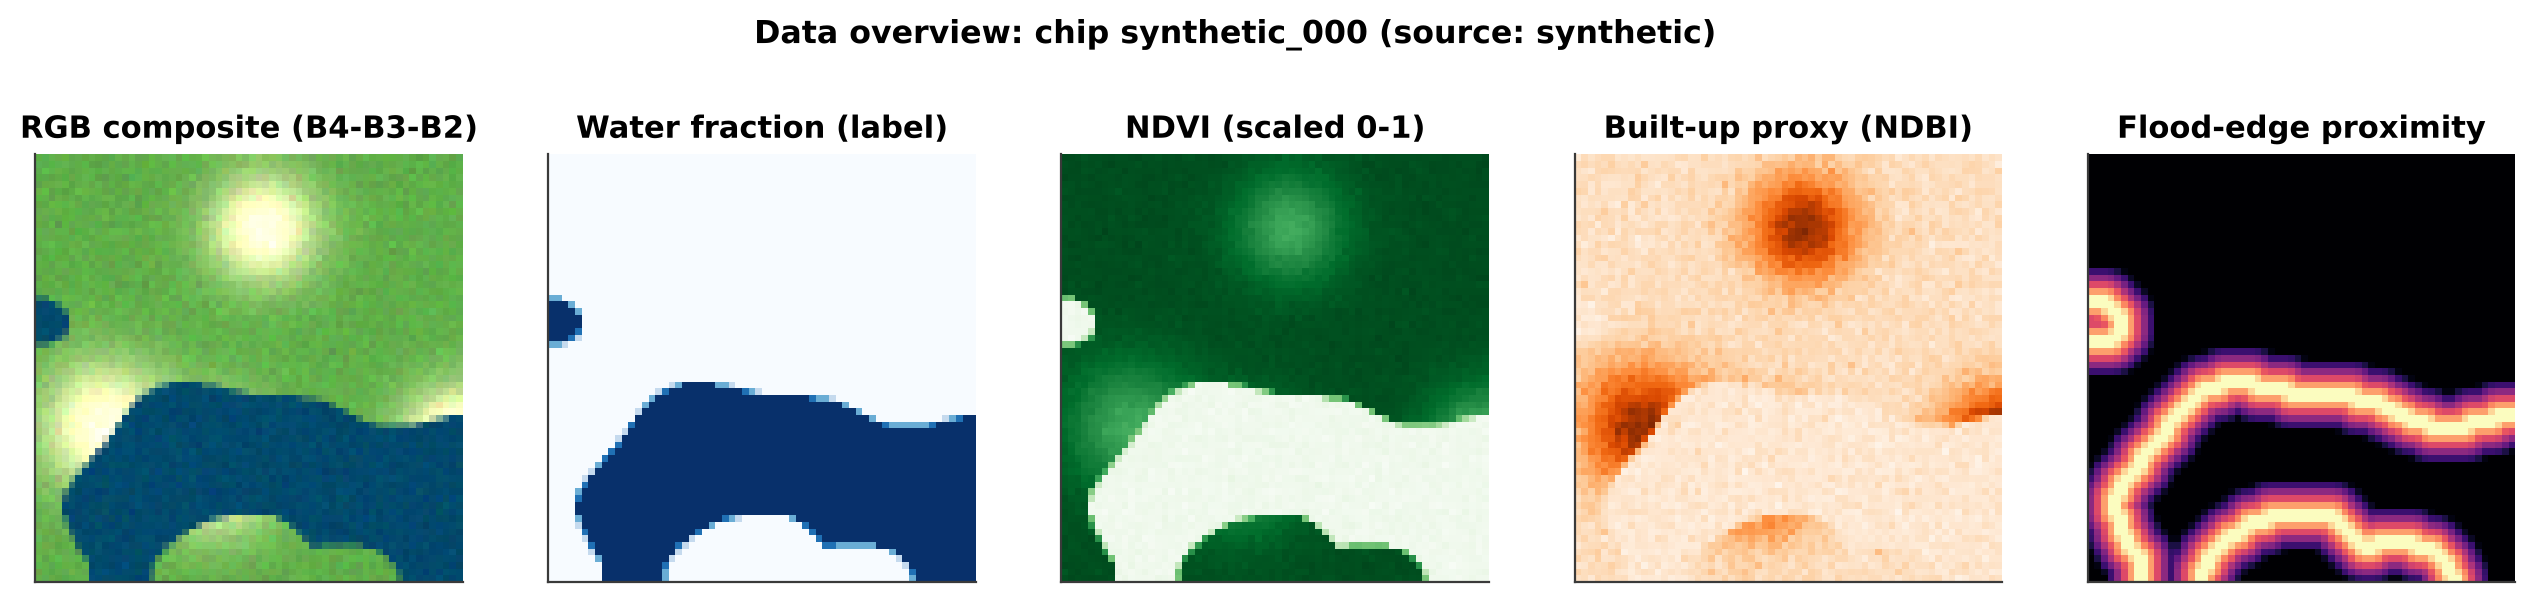

In [17]:
ds = P.stage_data(st)
print(f"X {ds.X.shape} | Y {ds.Y.shape} | sources: {ds.source_summary}")
viz.fig_data_overview(ds, 0, cfg.fig_dir); plt.show()

## 3. Heatmap model (CNN)
Three Conv-BN-ReLU blocks (16/32/64 channels), adaptive average pooling to the grid, 1x1 head, sigmoid
(< 100k parameters). MSE loss, Adam, 80/20 split by chip. Metrics on the validation chips: MAE, Pearson,
Spearman and top-k overlap. Predictions are min-max scaled per chip to give the QUBO weights `w`.

[19:34:18] INFO floodwing: start: heatmap_cnn


[19:34:19] INFO floodwing: epoch  1/8  train 0.0412  val 0.0361  spearman 0.945


[19:34:19] INFO floodwing: epoch  2/8  train 0.0239  val 0.0255  spearman 0.948


[19:34:19] INFO floodwing: epoch  3/8  train 0.0156  val 0.0173  spearman 0.947


[19:34:19] INFO floodwing: epoch  4/8  train 0.0098  val 0.0119  spearman 0.946


[19:34:19] INFO floodwing: epoch  5/8  train 0.0060  val 0.0078  spearman 0.941


... (2 outputs left out)

[19:34:19] INFO floodwing: epoch  8/8  train 0.0015  val 0.0026  spearman 0.934


[19:34:19] INFO floodwing: validation: MAE 0.0408 | Pearson 0.956 | Spearman 0.934 | top-4 overlap 0.80


[19:34:19] INFO floodwing: done:  heatmap_cnn (1.8s)


CNN: 23905 parameters on cpu | validation {'mae': 0.040804486721754074, 'pearson_r': 0.955861508846283, 'spearman_rho': 0.9340928035565436, 'topk_overlap': 0.8} | mean-predictor MAE 0.1331


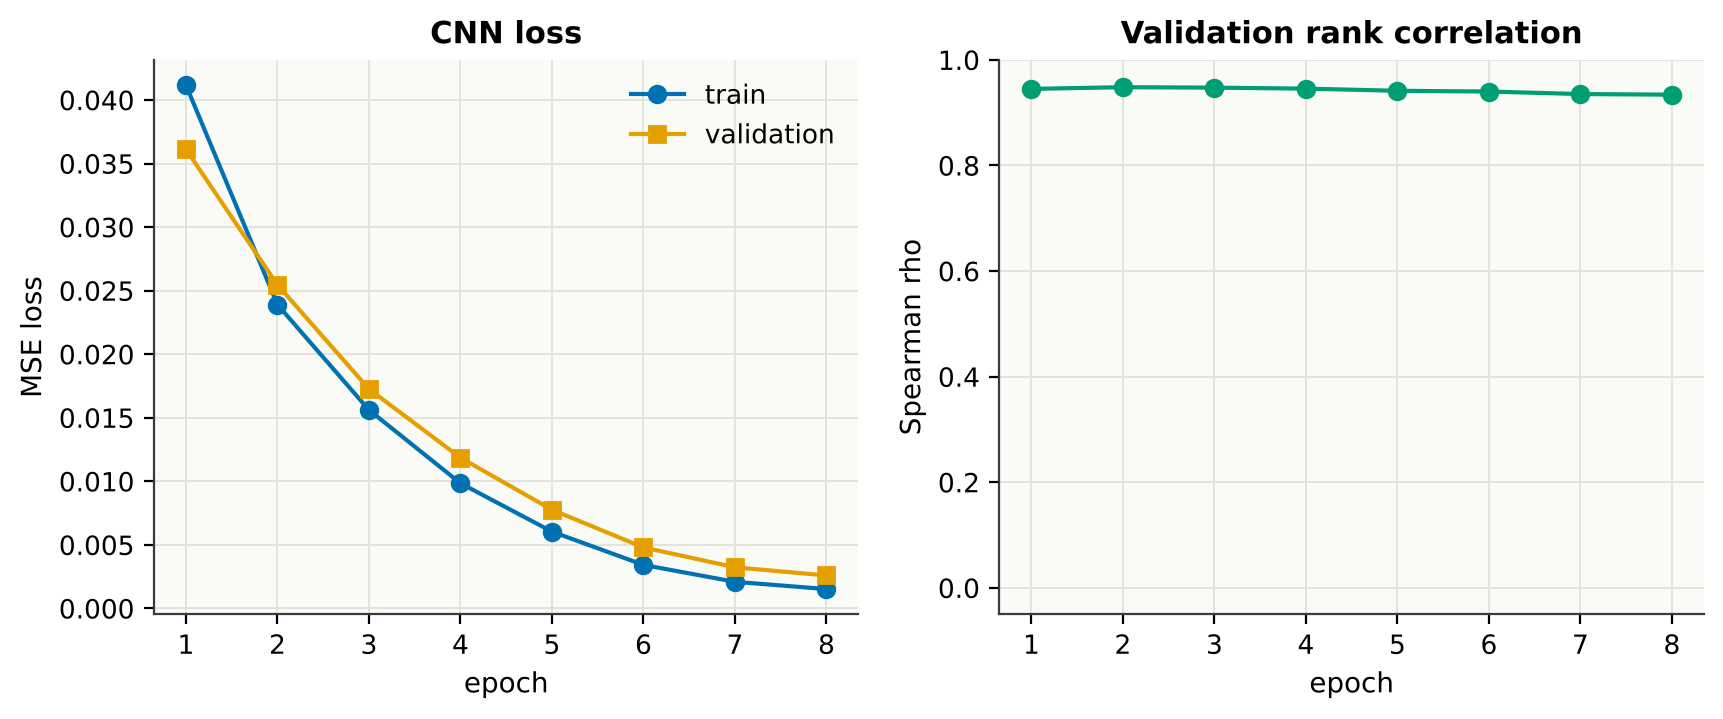

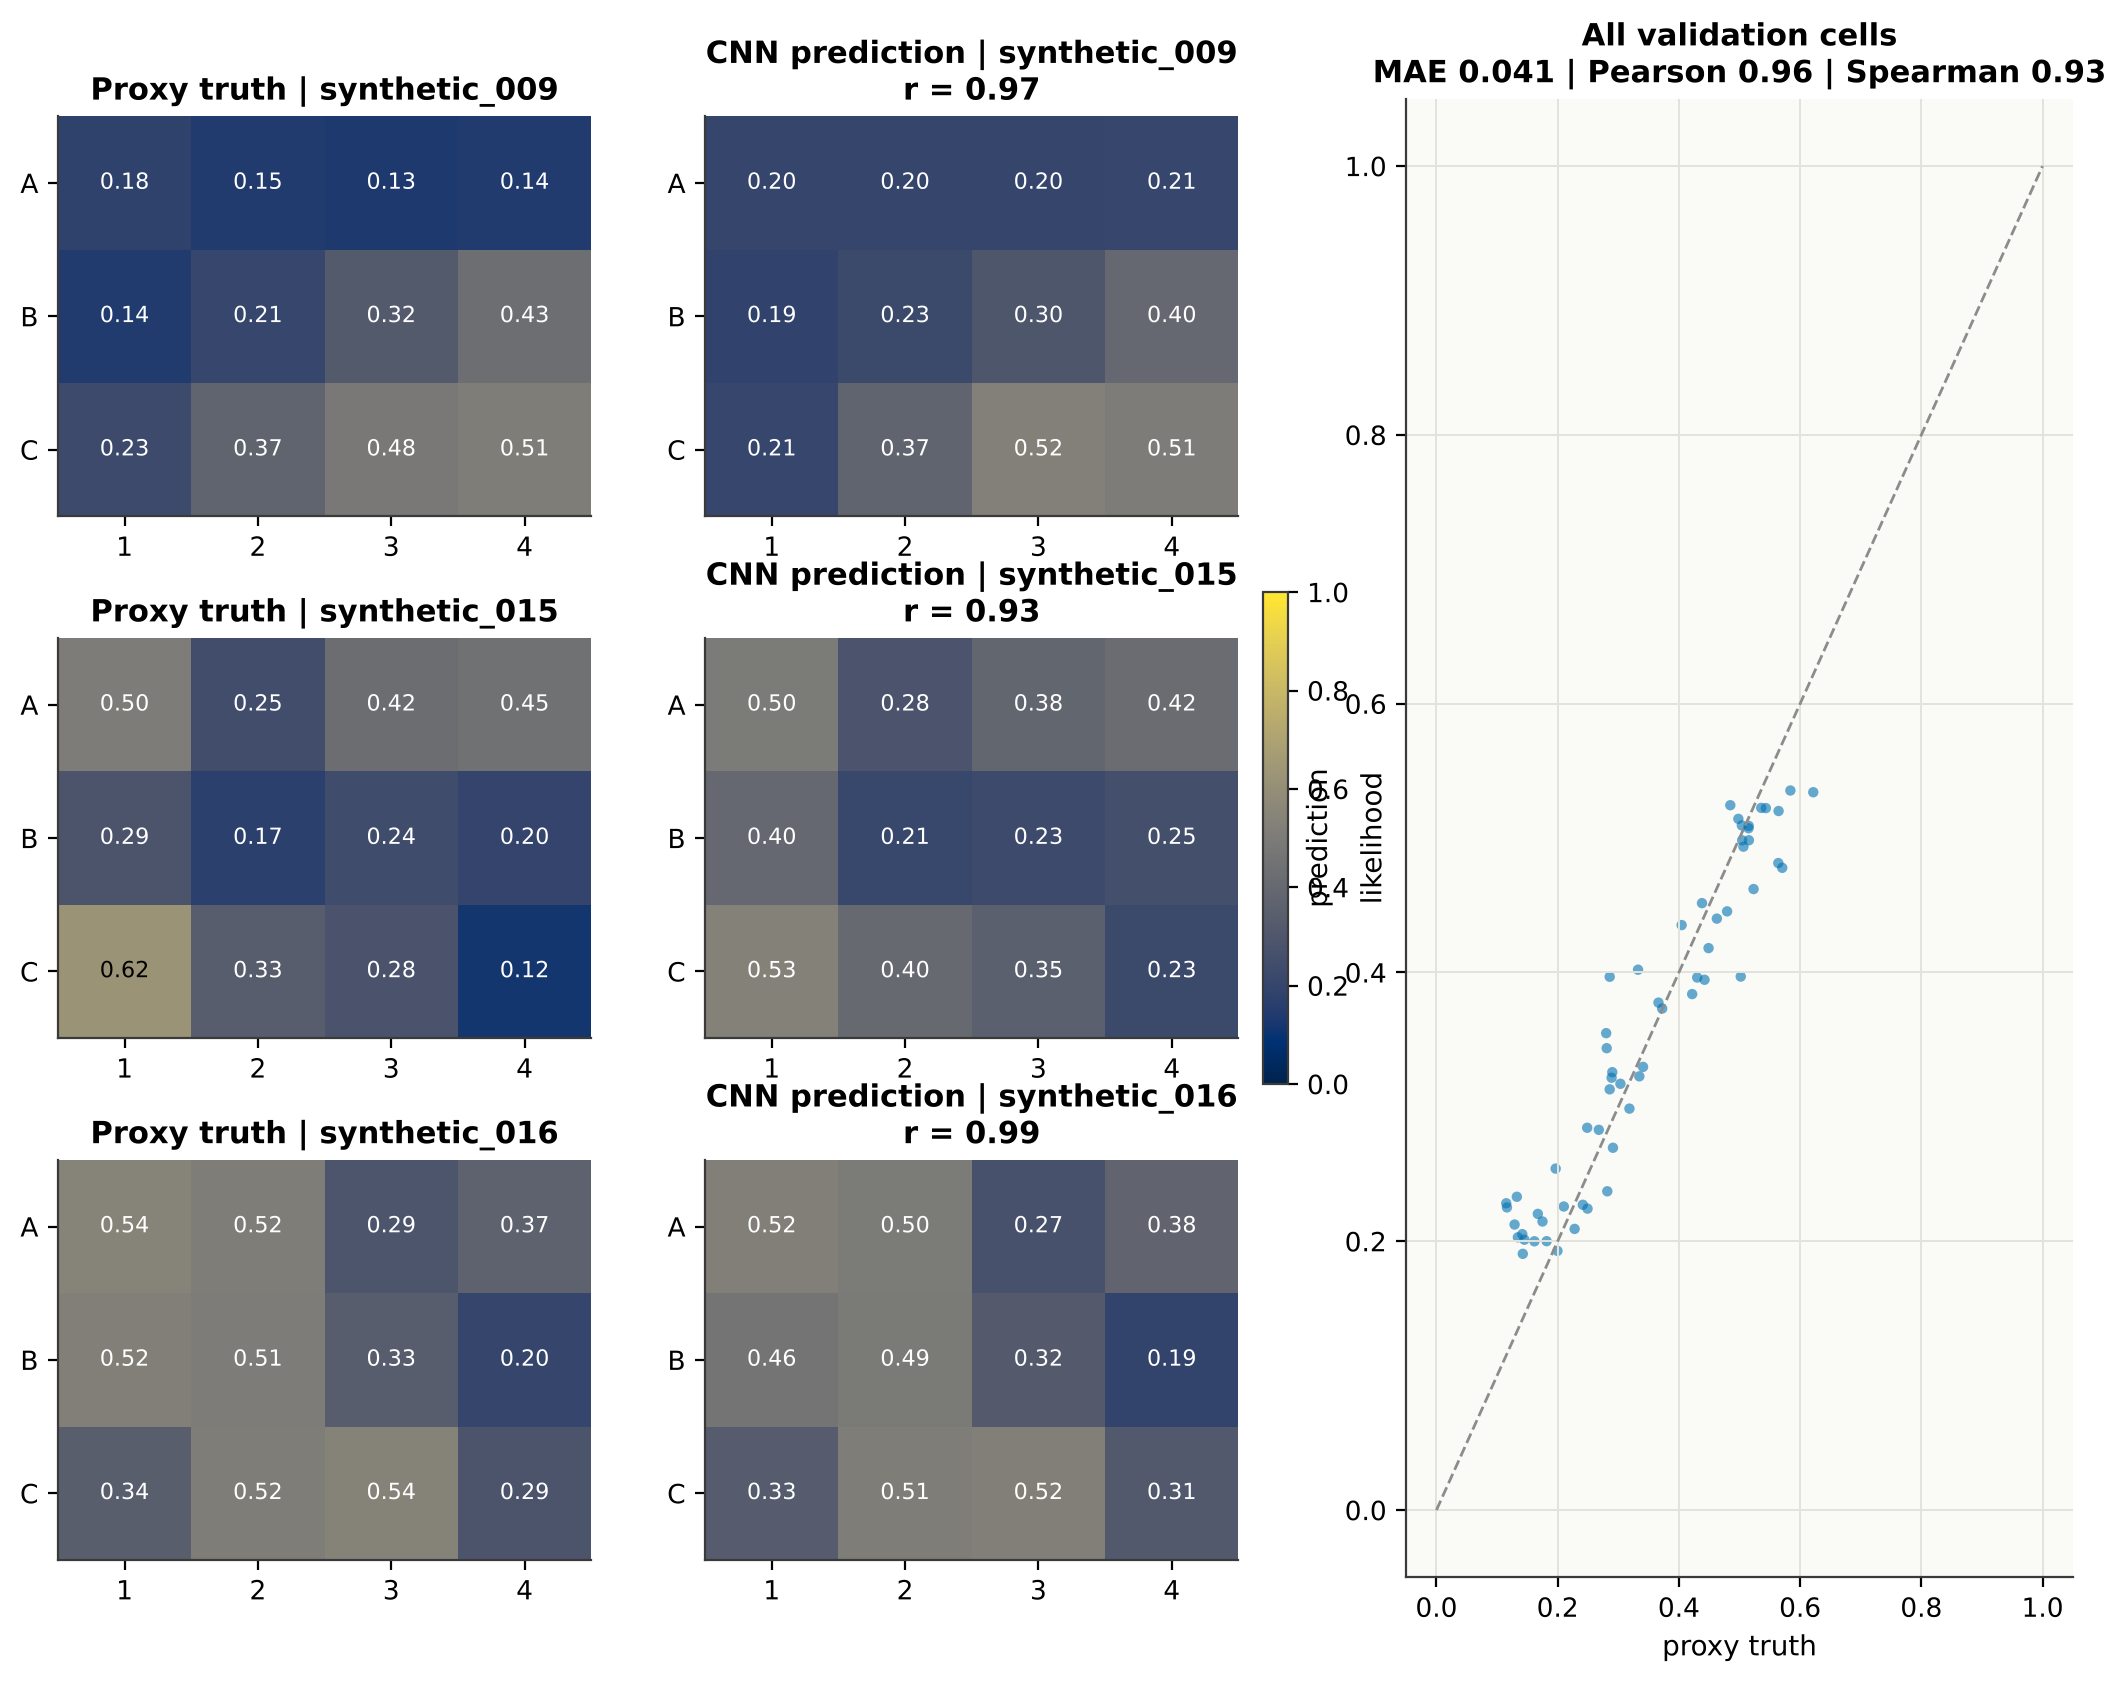

In [18]:
train = P.stage_heatmap(st)
viz.fig_training_curves(train.history, cfg.fig_dir); plt.show()
viz.fig_heatmap_prediction(ds, train, cfg.fig_dir); plt.show()

## 4. Agent layer
A deterministic keyword parser (no API keys) maps reports to updates. Cells are named letter = row,
number = column (A1..C4). Out-of-range cells are ignored and logged. Five sample reports are applied **in
sequence** to the demo heatmap and QAOA re-solves after each one. A local-LLM parser exists behind
`Config.use_local_llm` (default OFF) and falls back to the rules on any malformed output.

[19:34:21] INFO floodwing.agent: ignored out-of-range cell 'Z9' in report


[19:34:21] INFO floodwing.agent: ignored out-of-range cell 'D5' in report


[19:34:21] INFO floodwing: start: agent


8 evaluation instances; demo scenario = demo_synthetic_009
Family of four waving from a rooftop near C3. Small boat seen drifting at B4.
  -> [{'cell': 'C3', 'index': 10, 'action': 'boost', 'factor': 1.5, 'confidence': 1.0, 'evidence': 'rooftop'}, {'cell': 'B4', 'index': 7, 'action': 'boost', 'factor': 1.5, 'confidence': 1.0, 'evidence': 'boat'}]
Bridge down at A2, area is impassable. Power lines across B1, declare no-fly.
  -> [{'cell': 'A2', 'index': 1, 'action': 'block', 'factor': 0.0, 'confidence': 1.0, 'evidence': 'bridge down'}, {'cell': 'B1', 'index': 4, 'action': 'block', 'factor': 0.0, 'confidence': 1.0, 'evidence': 'power lines'}]
Sector C1 has been evacuated and cleared by ground teams.
  -> [{'cell': 'C1', 'index': 8, 'action': 'reduce', 'factor': 0.5, 'confidence': 1.0, 'evidence': 'evacuated'}]
Survivors stranded on a roof at A4; the building at B3 has collapsed.
  -> [{'cell': 'A4', 'index': 3, 'action': 'boost', 'factor': 1.5, 'confidence': 1.0, 'evidence': 'roof'}, {'c

Report 1: Family of four waving from a rooftop near C3. Small boat seen drifting at B4.
   updates: [('C3', 'boost'), ('B4', 'boost')]
   QAOA placement ['A2', 'B4', 'C2', 'C3'] (gap 0.008)


Report 2: Bridge down at A2, area is impassable. Power lines across B1, declare no-fly.
   updates: [('A2', 'block'), ('B1', 'block')]
   QAOA placement ['A3', 'C2', 'C3', 'C4'] (gap 0.000)


... (2 outputs left out)

[19:34:33] INFO floodwing: ignored out-of-range cell 'D5' in report


Report 4: Survivors stranded on a roof at A4; the building at B3 has collapsed.
   updates: [('A4', 'boost'), ('B3', 'block')]
   QAOA placement ['A3', 'C2', 'C3', 'C4'] (gap 0.000)


[19:34:36] INFO floodwing: done:  agent (15.5s)


Report 5: SOS signal from cell b2. Also unconfirmed chatter about Z9 and sector D5.
   updates: [('B2', 'boost')]
   QAOA placement ['A3', 'C2', 'C3', 'C4'] (gap 0.000)


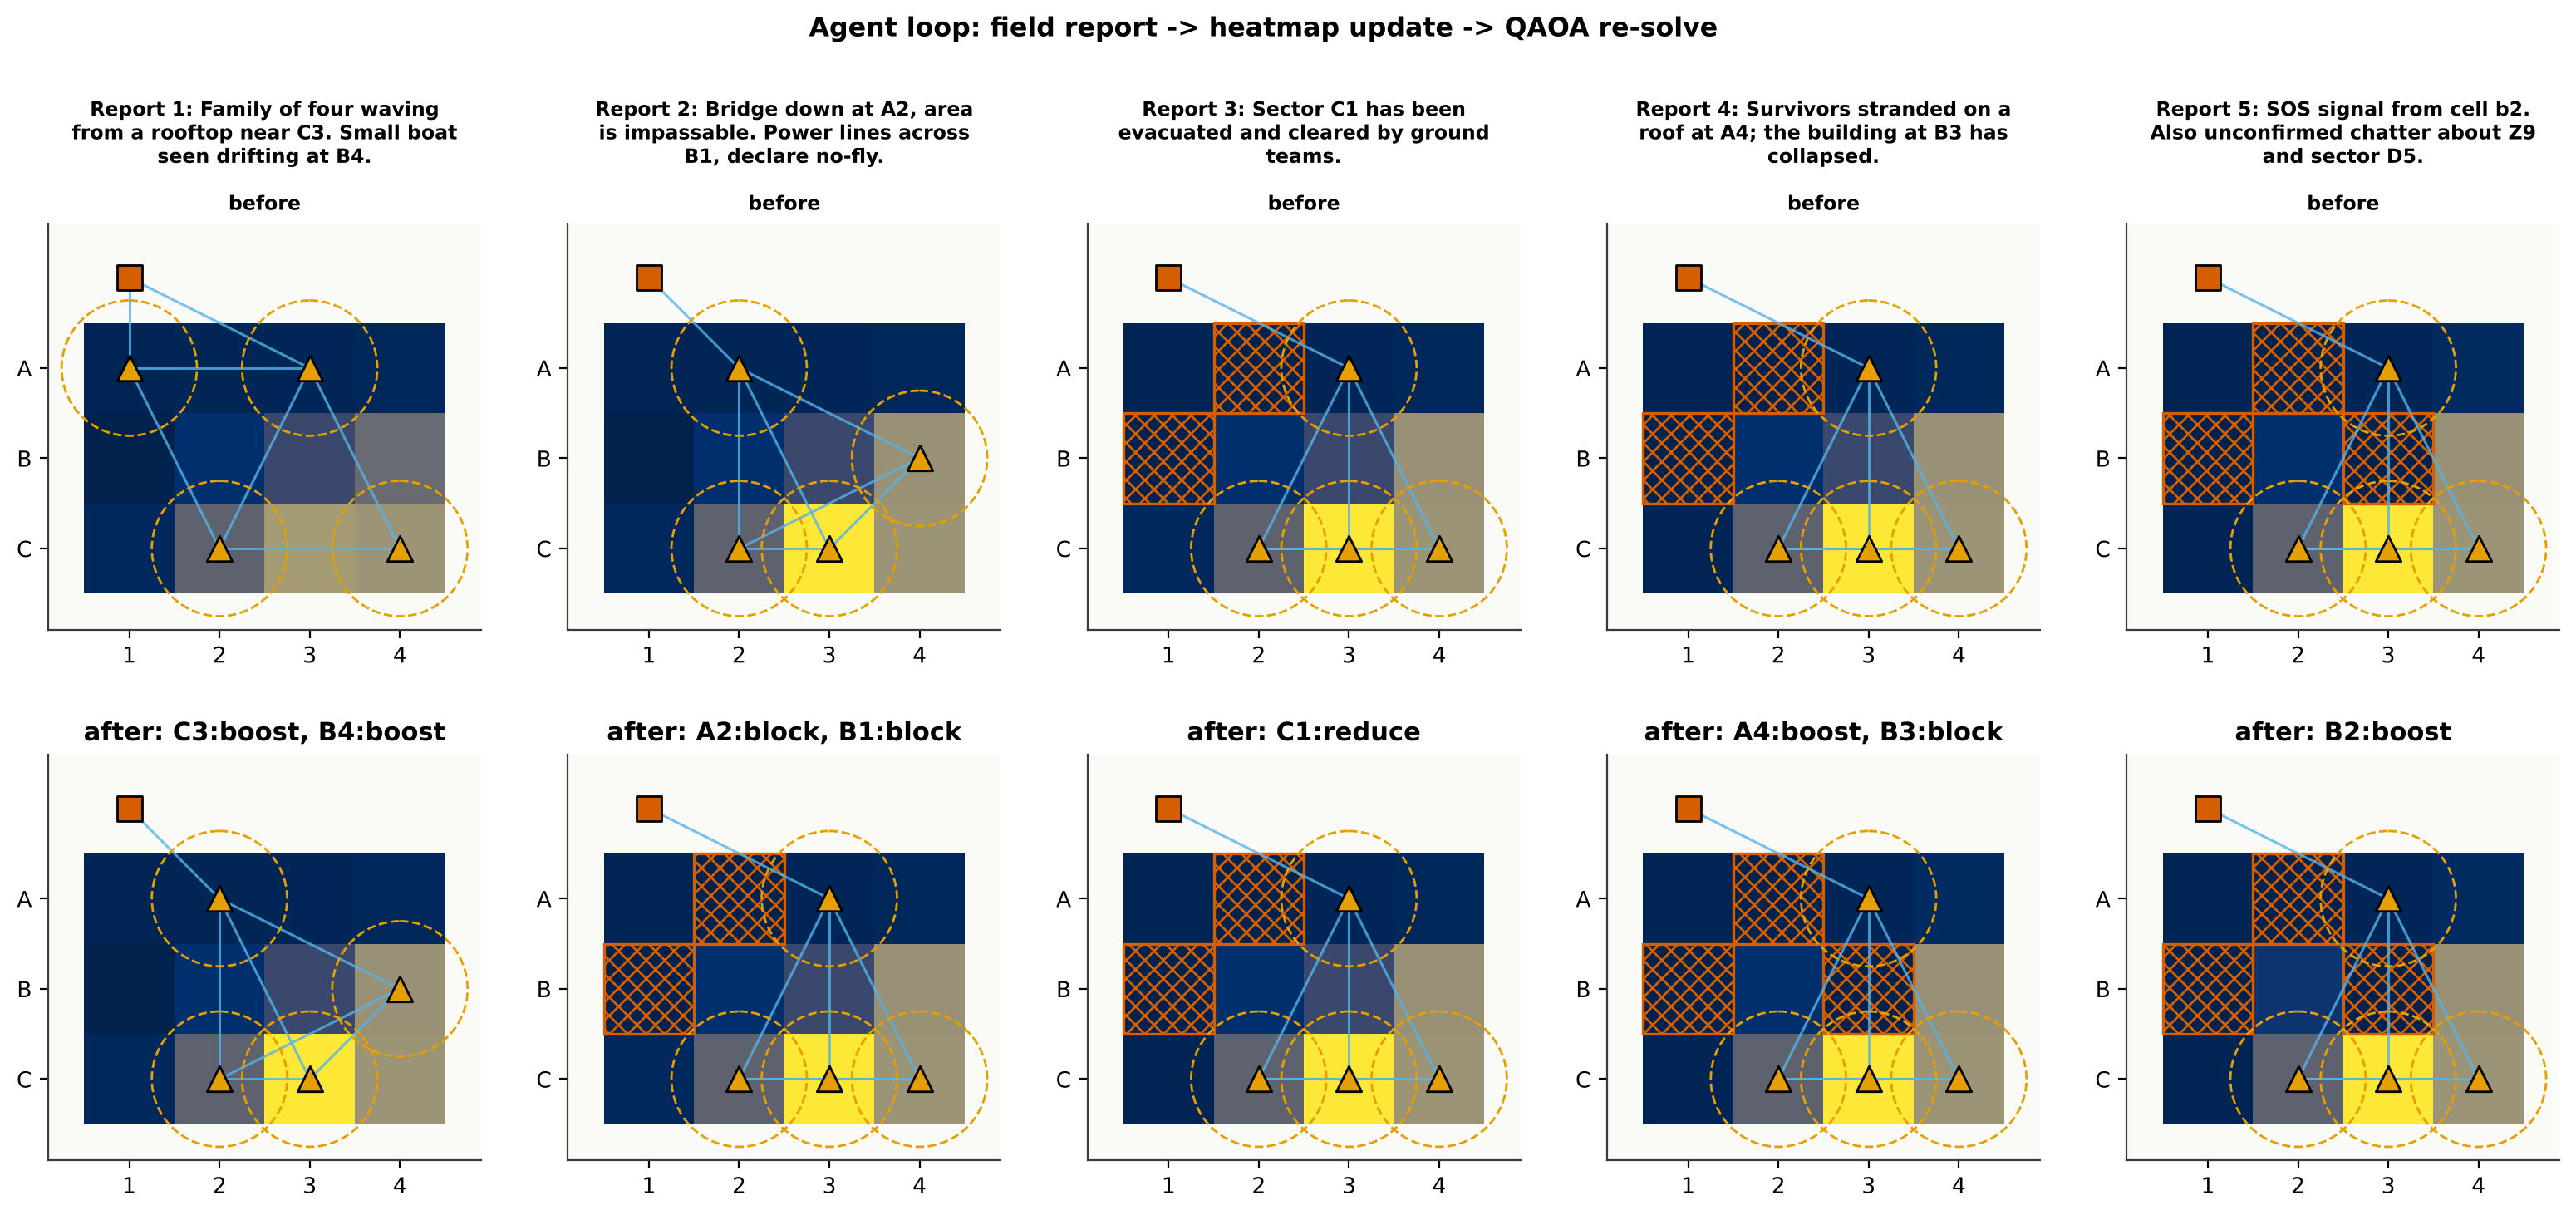

In [19]:
P.stage_instances(st)
for text in agent.SAMPLE_REPORTS:
    print(f"{text}\n  -> {agent.parse_report(text, cfg.rows, cfg.cols, cfg)}")
steps = P.stage_agent(st)
viz.fig_agent_before_after(steps, cfg.fig_dir); plt.show()

## 5. QUBO formulation
`f(x) = -sum w_i x_i + a sum O_ij x_i x_j - b sum C_ij x_i x_j`, plus `P (sum x - k)^2` and a linear penalty for
blocked cells. The model is built as a `QuadraticProgram`, converted with `QuadraticProgramToQubo`, and checked
against an explicit QUBO matrix; the unit tests run here too.

In [20]:
qubo_info = P.stage_qubo(st)
import pytest
exit_code = pytest.main(["-q", "-p", "no:cacheprovider", "-W", "ignore", str(PKG_DIR / "tests" / "test_core.py")])
print("pytest exit code:", int(exit_code))

[19:34:37] INFO floodwing: start: qubo


[19:34:37] INFO floodwing: done:  qubo (0.1s)


Problem name: demo_synthetic_009

Minimize
  0.3*x0*x1 - 0.3*x0*x2 + 0.3*x0*x4 + 0.3*x0*x5 - 0.3*x0*x6 - 0.3*x0*x8
  - 0.3*x0*x9 - 0.3*x1*x10 + 0.3*x1*x2 - 0.3*x1*x3 + 0.3*x1*x4 + 0.3*x1*x5
  + 0.3*x1*x6 - 0.3*x1*x7 - 0.3*x1*x8 - 0.3*x1*x9 + 0.3*x10*x11 - 0.3*x2*x10
  - 0.3*x2*x11 + 0.3*x2*x3 - 0.3*x2*x4 + 0.3*x2*x5 + 0.3*x2*x6 + 0.3*x2*x7
  - 0.3*x2*x9 - 0.3*x3*x10 - 0.3*x3*x11 - 0.3*x3*x5 + 0.3*x3*x6 + 0.3*x3*x7
  - 0.3*x4*x10 + 0.3*x4*x5 - 0.3*x4*x6 + 0.3*x4*x8 + 0.3*x4*x9 + 0.3*x5*x10
  - 0.3*x5*x11 + 0.3*x5*x6 - 0.3*x5*x7 + 0.3*x5*x8 + 0.3*x5*x9 + 0.3*x6*x10
  + 0.3*x6*x11 + 0.3*x6*x7 - 0.3*x6*x8 + 0.3*x6*x9 + 0.3*x7*x10 + 0.3*x7*x11
  - 0.3*x7*x9 - 0.3*x8*x10 + 0.3*x8*x9 + 0.3*x9*x10 - 0.3*x9*x11
  - 0.02822917513549328*x0 - 0.031526438891887665*x1 - x10
  - 0.9486891031265259*x11 - 0.03677748143672943*x2 - 0.043876104056835175*x3
  - 0.10551223903894424*x5 - 0.3237440586090088*x6 - 0.6159380674362183*x7
  - 0.05557083338499069*x8 - 0.5467635989189148*x9

Subject to
  Linear cons

.

.

.

... (11 outputs left out)

.

                                                           [100%]


14 passed in 0.79s


pytest exit code: 0


## 6. QAOA solve + baselines
`qiskit_algorithms.QAOA` (p = 2, COBYLA, Aer sampler) on the demo scenario, against exact brute force,
greedy, simulated annealing and random placements. Three QAOA read-outs are reported: **QAOA** (most probable
valid bitstring of the exact output state), **QAOA-shots** (most frequent valid bitstring in 4096 shots, what
hardware would give) and **QAOA-best-sample** (best valid bitstring among the shots, close to brute force).

[19:34:39] INFO floodwing: start: demo_solve


[19:34:41] INFO floodwing: done:  demo_solve (2.2s)


QAOA primitive: qiskit_aer.primitives.SamplerV2 (8192 shots) | decode: most_probable_valid (exact distribution) | 78 Pauli terms | optimal params [-0.368 -0.13   0.167  0.534]


,method,objective,gap,valid,coverage,overlap,connected,p_valid,p_optimal,n_evals,runtime_s,cells_named
0,Exact,-3.1322,0.0000,True,2.5322,2,True,NaN,NaN,495,6.2469e-04,"A3, C2, C3, C4"
1,QAOA,-3.0605,0.0229,True,1.5605,0,True,0.5108,0.0012,31,2.1018e+00,"A1, A3, C2, C4"
2,QAOA-shots,-0.8452,0.7302,True,2.0452,5,True,0.5161,0.0007,31,2.1018e+00,"B2, B3, B4, C3"
3,QAOA-best-sample,-3.1322,0.0000,True,2.5322,2,True,0.5161,0.0007,31,2.1018e+00,"A3, C2, C3, C4"
4,Greedy,-2.9241,0.0665,True,2.0241,1,True,NaN,NaN,42,5.1908e-05,"A2, A4, C3, C4"
5,SA,-3.1322,0.0000,True,2.5322,2,True,NaN,NaN,3000,1.2433e-01,"A3, C2, C3, C4"
6,Random,-1.1236,0.6413,True,1.5420,3,False,NaN,NaN,1000,6.5601e-03,"B3, B4, C1, C2"


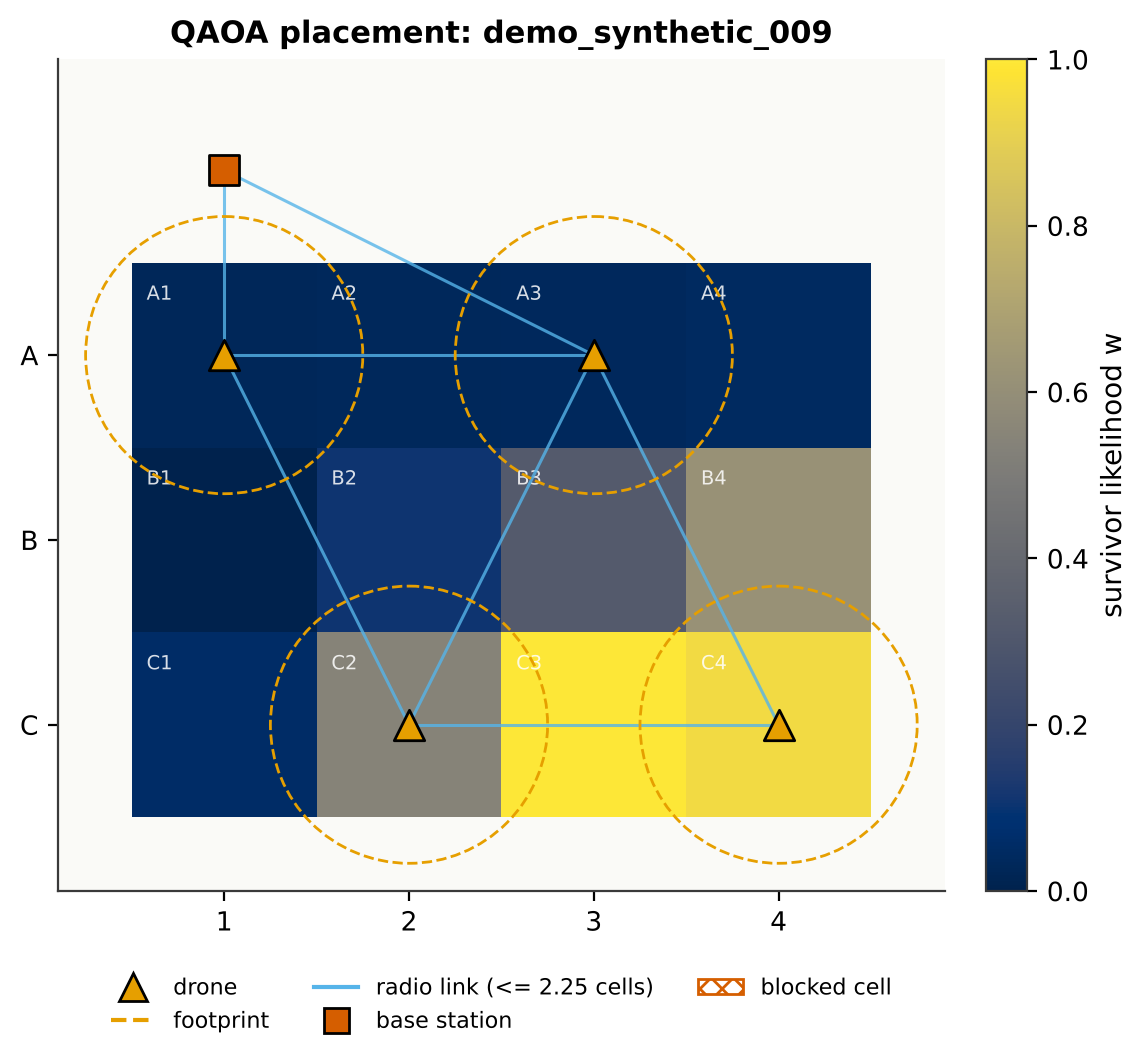

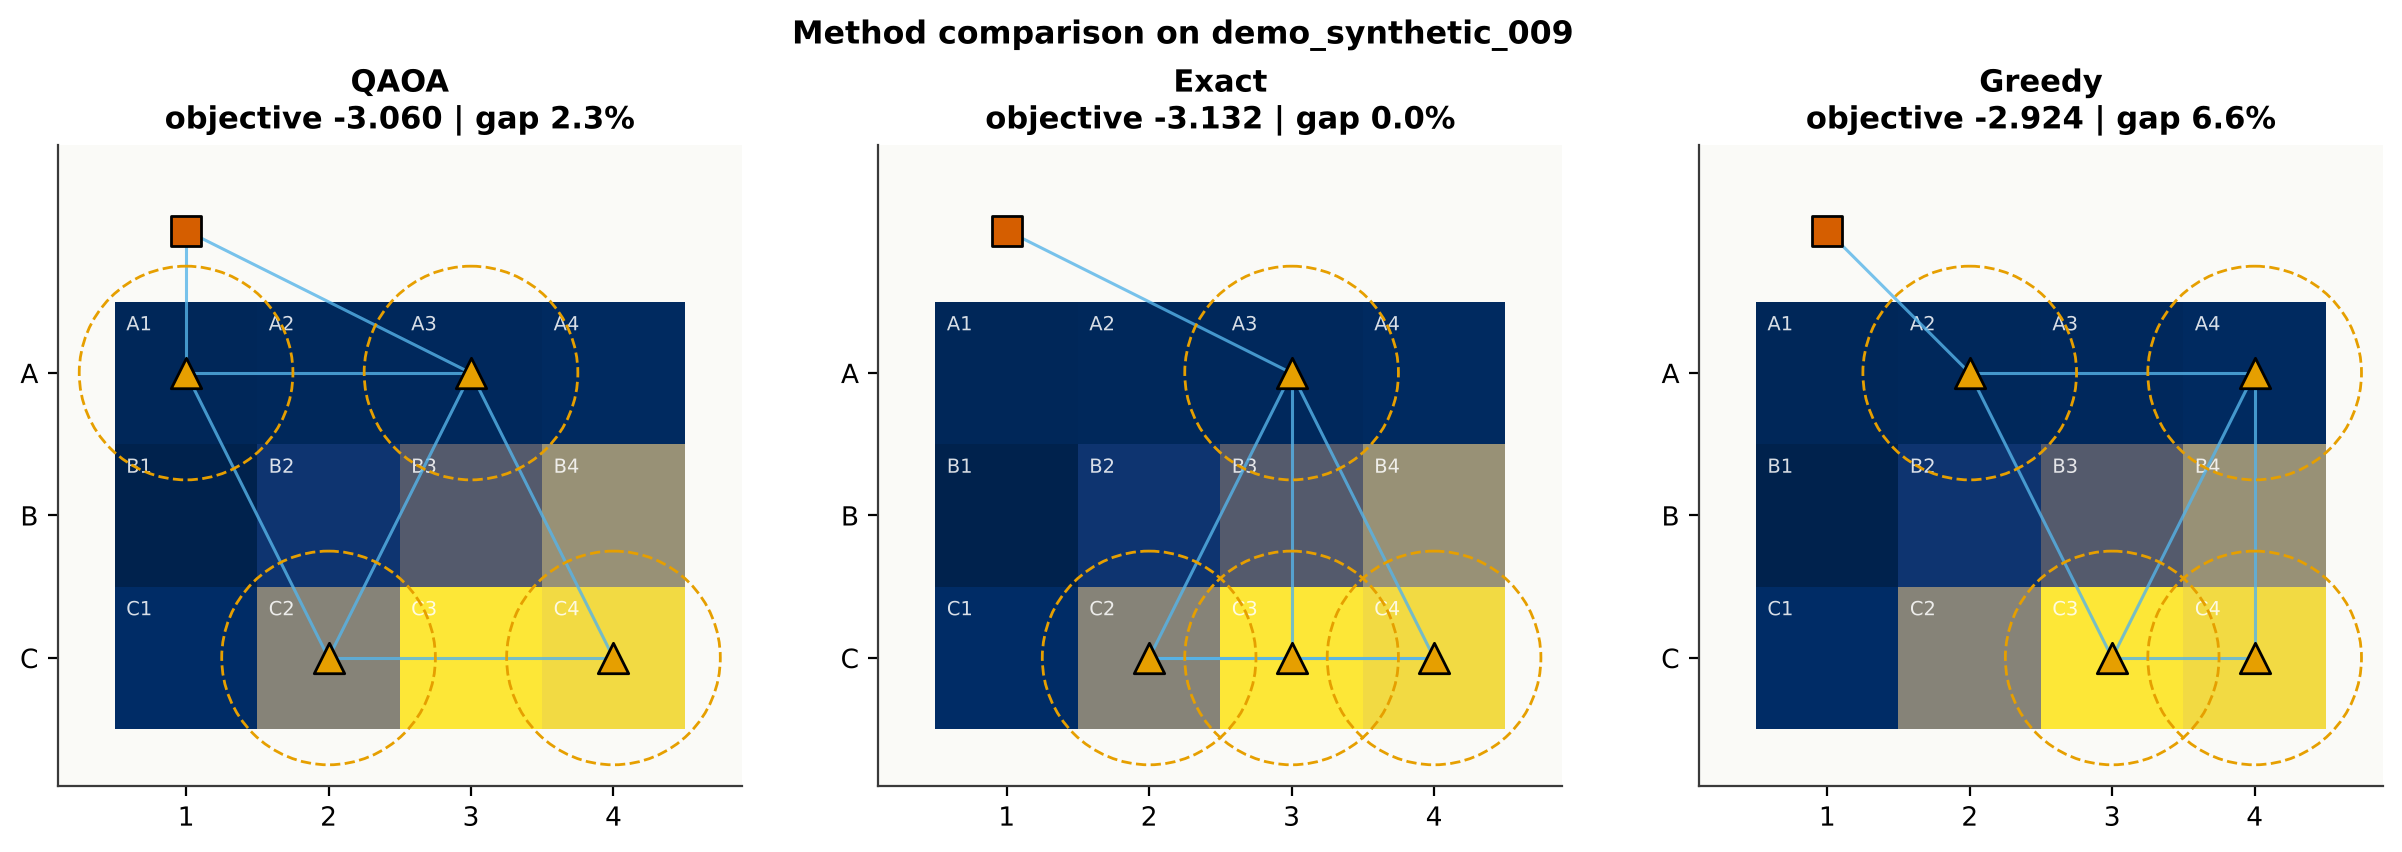

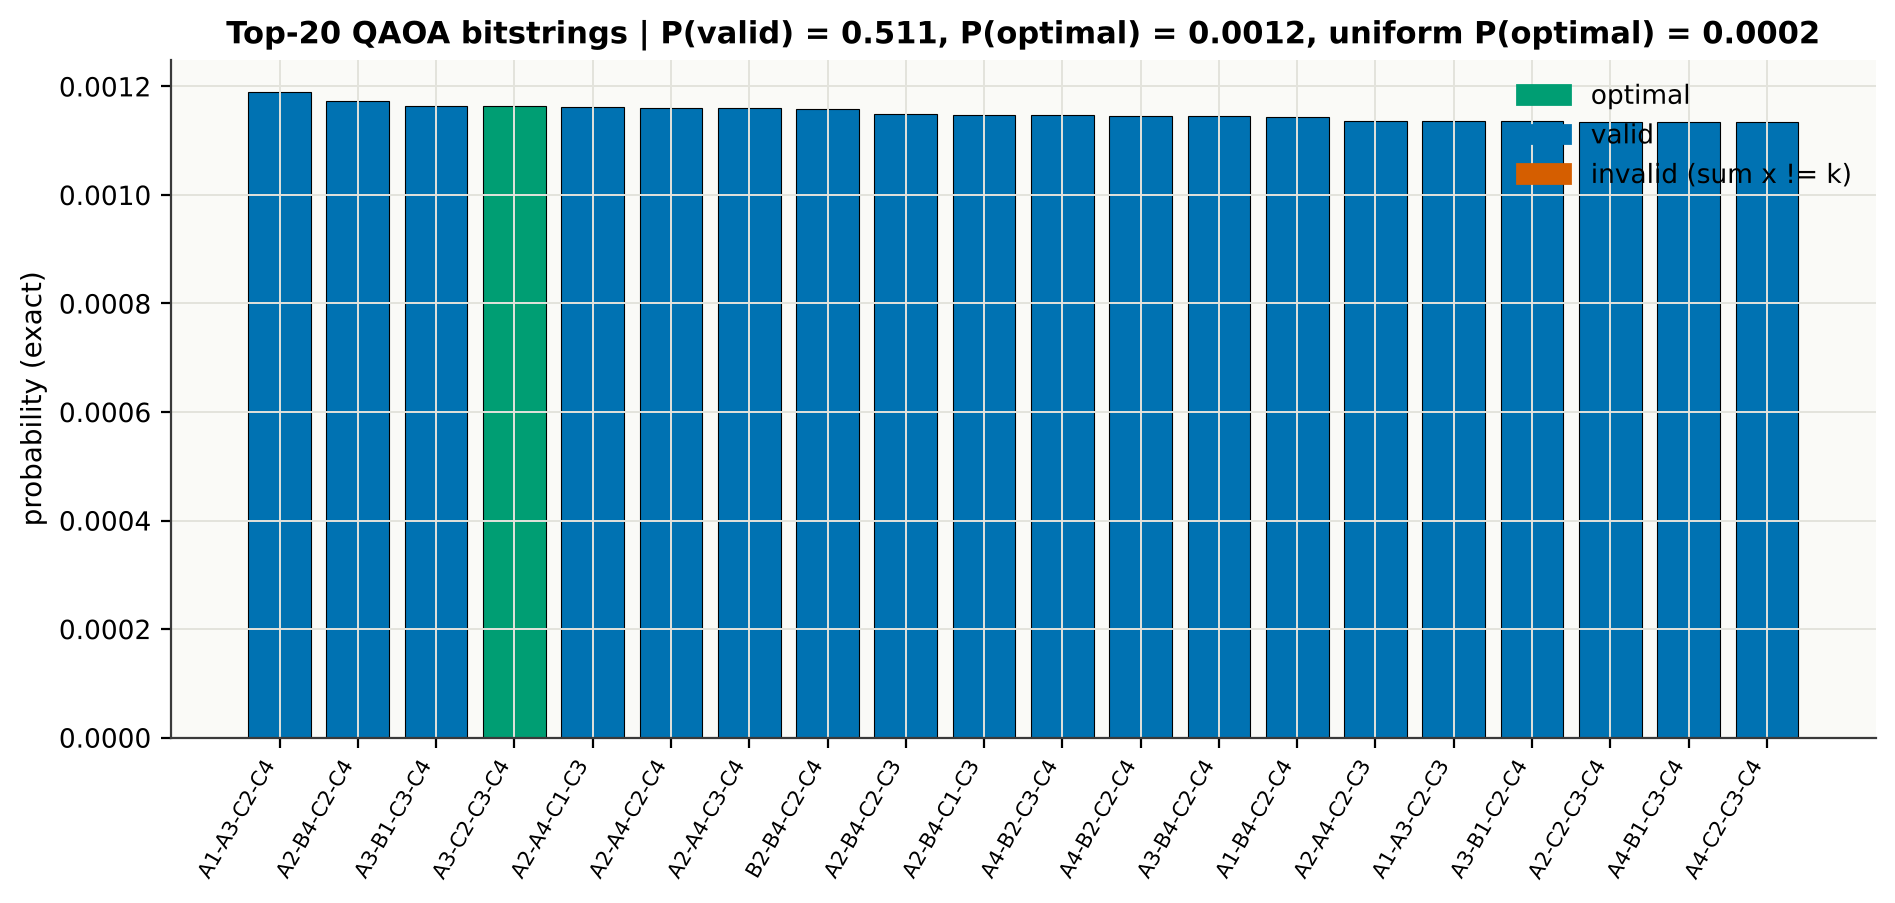

In [21]:
demo_df = P.stage_demo_solve(st)
display(demo_df[["method", "objective", "gap", "valid", "coverage", "overlap", "connected", "p_valid",
                 "p_optimal", "n_evals", "runtime_s", "cells_named"]])
q = st.demo_results["QAOA"]
viz.fig_placement_map(st.demo.problem, q.x, cfg.fig_dir, f"QAOA placement: {st.demo.name}"); plt.show()
viz.fig_method_comparison(st.demo.problem, {m: st.demo_results[m] for m in ("QAOA", "Exact", "Greedy")}, cfg.fig_dir); plt.show()
viz.fig_bitstring_probs(st.demo.problem, q.extras["p_exact"], cfg.fig_dir); plt.show()

## 7. Evaluation across instances
Every method on every instance (one instance per chip heatmap, validation chips first). Outputs
`results/tables/main_results.csv`, `results/tables/summary.csv` and a paired Wilcoxon test of QAOA vs greedy.

[19:34:42] INFO floodwing: start: evaluation


[19:34:44] INFO floodwing: inst00_synthetic_009: QAOA gap 0.023 | P(valid) 0.51 | P(opt) 0.0012 | evals 31 | 2.2s


[19:34:47] INFO floodwing: inst01_synthetic_015: QAOA gap 0.000 | P(valid) 0.52 | P(opt) 0.0012 | evals 37 | 2.6s


[19:34:50] INFO floodwing: inst02_synthetic_016: QAOA gap 0.000 | P(valid) 0.52 | P(opt) 0.0012 | evals 36 | 2.5s


[19:34:52] INFO floodwing: inst03_synthetic_018: QAOA gap 0.053 | P(valid) 0.51 | P(opt) 0.0012 | evals 28 | 1.9s


[19:34:54] INFO floodwing: inst04_synthetic_019: QAOA gap 0.000 | P(valid) 0.53 | P(opt) 0.0013 | evals 33 | 2.4s


... (3 outputs left out)

[19:35:01] INFO floodwing: done:  evaluation (19.4s)


Wilcoxon QAOA vs Greedy: {'a': 'QAOA', 'b': 'Greedy', 'n': 8, 'mean_diff': -0.07977523650042961, 'a_better': 3, 'b_better': 0, 'ties': 5, 'statistic': 0.0, 'p_value': 0.25, 'note': 'not significant at 5% (p=0.250, 3 non-tied pairs); no reliable difference between the methods on these instances'}


,method,n,gap_mean,gap_median,valid_rate,p_valid_mean,p_optimal_mean,connected_rate,evals_mean,runtime_mean_s,tie_vs_exact,loss_vs_exact
0,Exact,8,0.0000,0.0000,1.0,NaN,NaN,1.00,495.000,5.3599e-04,8,0
1,QAOA,8,0.0094,0.0000,1.0,0.5156,0.0012,1.00,32.375,2.2887e+00,6,2
2,QAOA-shots,8,0.5564,0.5859,1.0,0.5215,0.0007,1.00,32.375,2.2887e+00,0,8
3,QAOA-best-sample,8,0.0000,0.0000,1.0,0.5215,0.0007,1.00,32.375,2.2887e+00,8,0
4,Greedy,8,0.0308,0.0000,1.0,NaN,NaN,1.00,42.000,5.3236e-05,5,3
5,SA,8,0.0000,0.0000,1.0,NaN,NaN,1.00,3000.000,1.1819e-01,8,0
6,Random,8,0.5847,0.5794,1.0,NaN,NaN,0.75,1000.000,6.6187e-03,0,8


not significant at 5% (p=0.250, 3 non-tied pairs); no reliable difference between the methods on these instances


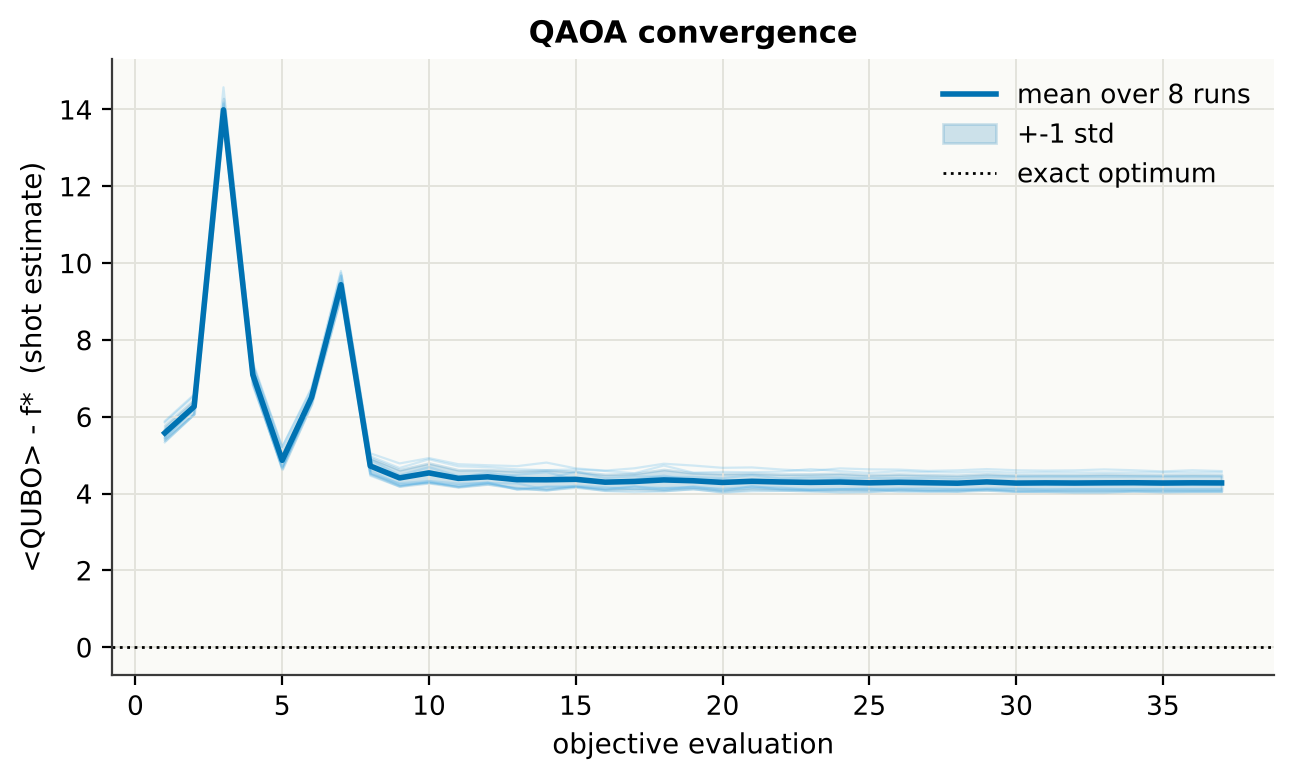

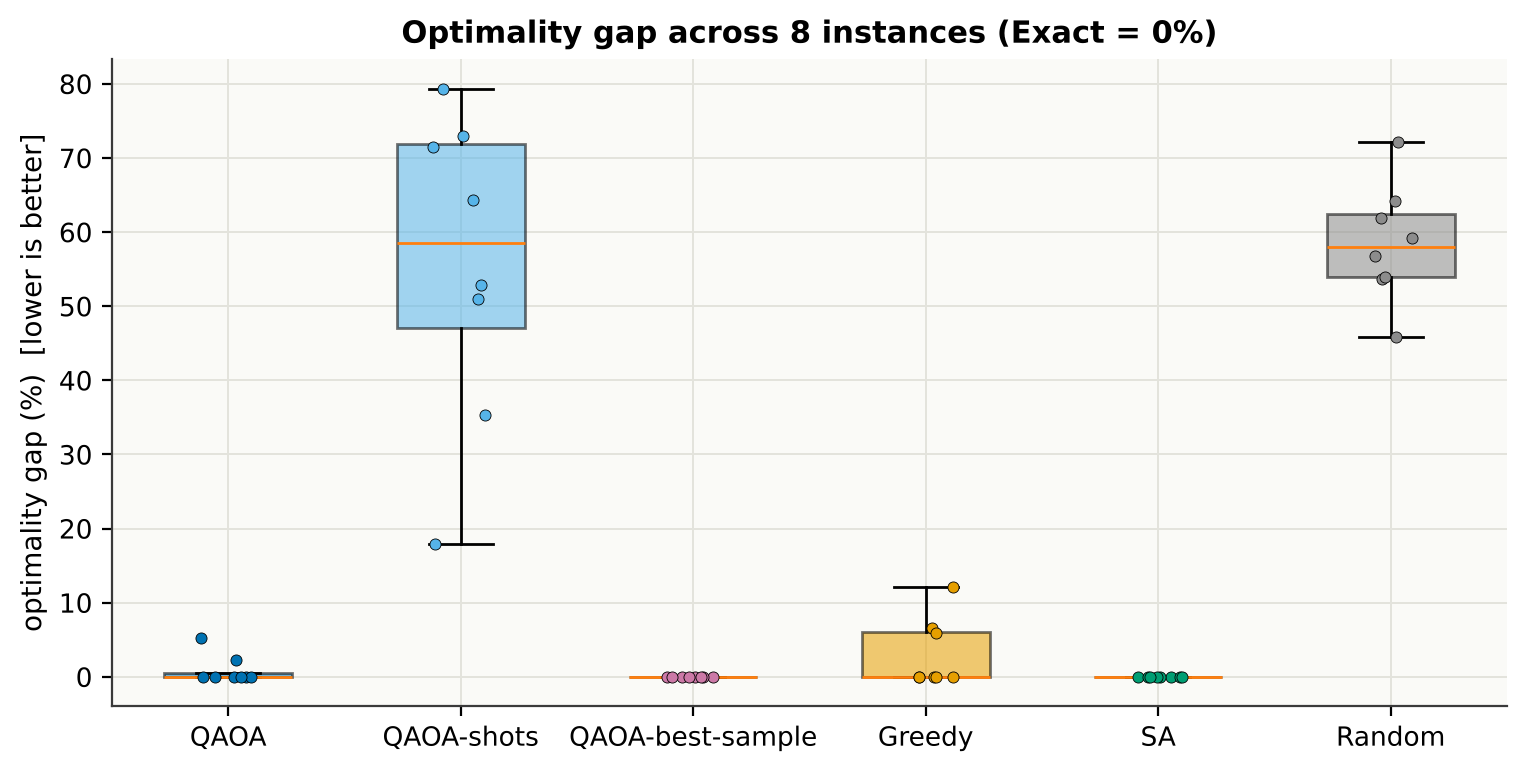

In [22]:
main_df, summary_df = P.stage_evaluate(st)
display(summary_df[["method", "n", "gap_mean", "gap_median", "valid_rate", "p_valid_mean", "p_optimal_mean",
                    "connected_rate", "evals_mean", "runtime_mean_s", "tie_vs_exact", "loss_vs_exact"]])
print(st.wilcoxon["note"])
hist = [v["qaoa"].extras["history"] for v in st.raw_eval.values()]
opts = [v["exact"].objective for v in st.raw_eval.values()]
viz.fig_qaoa_convergence(hist, opts, cfg.fig_dir); plt.show()
viz.fig_gap_distribution(main_df, cfg.fig_dir); plt.show()

## 8. Bonus quantum experiments
Each experiment is gated by a `Config` flag and wrapped so a failure is logged (and reported in Section 10)
instead of stopping the run: depth study, penalty sweep, warm start after an agent update, optimizer
comparison, noise robustness, (gamma, beta) landscape, scaling probe, and a constraint-preserving XY mixer.

In [23]:
bonus = P.stage_bonus(st)
GROUP_BY = {"depth": "p", "penalty": "multiplier", "optimizers": "optimizer", "xy_mixer": "mixer"}
for key in ("depth", "penalty", "optimizers", "xy_mixer", "noise", "scaling"):
    df_b = bonus.get(key)
    if not isinstance(df_b, pd.DataFrame):
        continue
    display(Markdown(f"**{key}**"))
    display(df_b.groupby(GROUP_BY[key]).mean(numeric_only=True) if key in GROUP_BY else df_b)
if bonus.get("warmstart"):
    print("warm start:", bonus["warmstart"]["warm_summary"])
    print("random init:", pd.DataFrame(bonus["warmstart"]["cold_summary"]).mean().to_dict())

[19:35:02] INFO floodwing: start: bonus_depth


[19:35:03] INFO floodwing: depth p=1 inst00_synthetic_009: gap 0.023 P(opt) 0.0011 evals 23


[19:35:06] INFO floodwing: depth p=2 inst00_synthetic_009: gap 0.023 P(opt) 0.0012 evals 31


[19:35:09] INFO floodwing: depth p=3 inst00_synthetic_009: gap 0.023 P(opt) 0.0013 evals 43


[19:35:11] INFO floodwing: depth p=1 inst01_synthetic_015: gap 0.000 P(opt) 0.0010 evals 29


[19:35:13] INFO floodwing: depth p=2 inst01_synthetic_015: gap 0.000 P(opt) 0.0013 evals 30


... (66 outputs left out)

,level,p1,p2,readout,p_optimal,p_valid,mean_energy,cx_count,depth
0,0.0,0.0000,0.000,0.000,0.0007,0.5161,0.9147,264,113
1,0.5,0.0005,0.005,0.005,0.0002,0.3804,4.0422,264,113
2,1.0,0.0010,0.010,0.010,0.0007,0.3003,7.1864,264,113
3,2.0,0.0020,0.020,0.020,0.0002,0.2214,13.1006,264,113
4,4.0,0.0040,0.040,0.040,0.0000,0.1494,20.3648,264,113


**scaling**

,n_qubits,grid,k,qaoa_time_s,evals,time_per_eval_s,statevector_bytes,exact_time_s,exact_candidates,gap
0,8,2x4,4,0.3033,5,0.0607,4096,0.0004,70,0.0189
1,10,2x5,4,0.4553,5,0.0911,16384,0.0008,210,0.0000
2,12,3x4,4,0.5686,5,0.1137,65536,0.0014,495,0.0000
3,14,2x7,4,0.8486,5,0.1697,262144,0.0014,1001,0.0000
4,16,4x4,4,1.2499,5,0.2500,1048576,0.0019,1820,0.0000


warm start: {'evals': 29, 'evals_to_converge': 13, 'final_energy': 1.054245497522839, 'gap': 0.008268486026472585, 'p_optimal': 0.0012759053681626064, 'p_valid': 0.5579604776085338}
random init: {'evals': 54.0, 'evals_to_converge': 45.0, 'final_energy': 24.189644146910478, 'gap': 0.5252790316133861, 'p_optimal': 0.0009298178450701904, 'p_valid': 0.4397727344113147}


## 9. Visualisations gallery
All figures are regenerated at 200 dpi in `results/figures/`.

[19:38:51] INFO floodwing: start: figures


[19:38:57] INFO floodwing: done:  figures (5.6s)


19 figures in /home/claude/floodwing/results/figures


**01_data_overview.png**

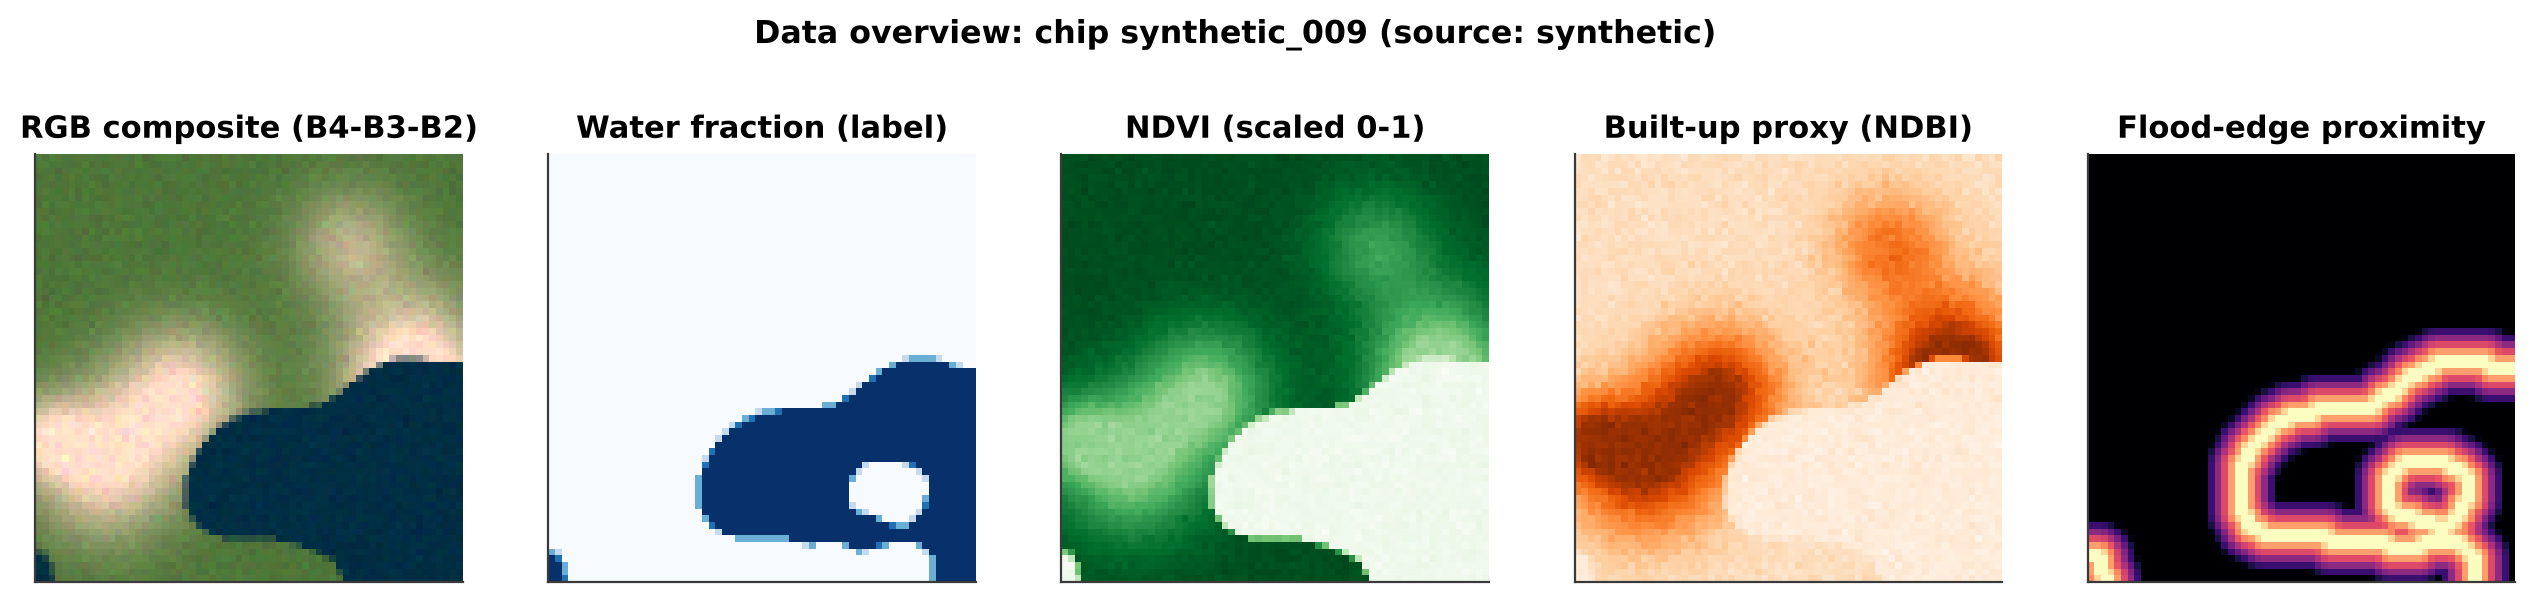

**02_heatmap_prediction.png**

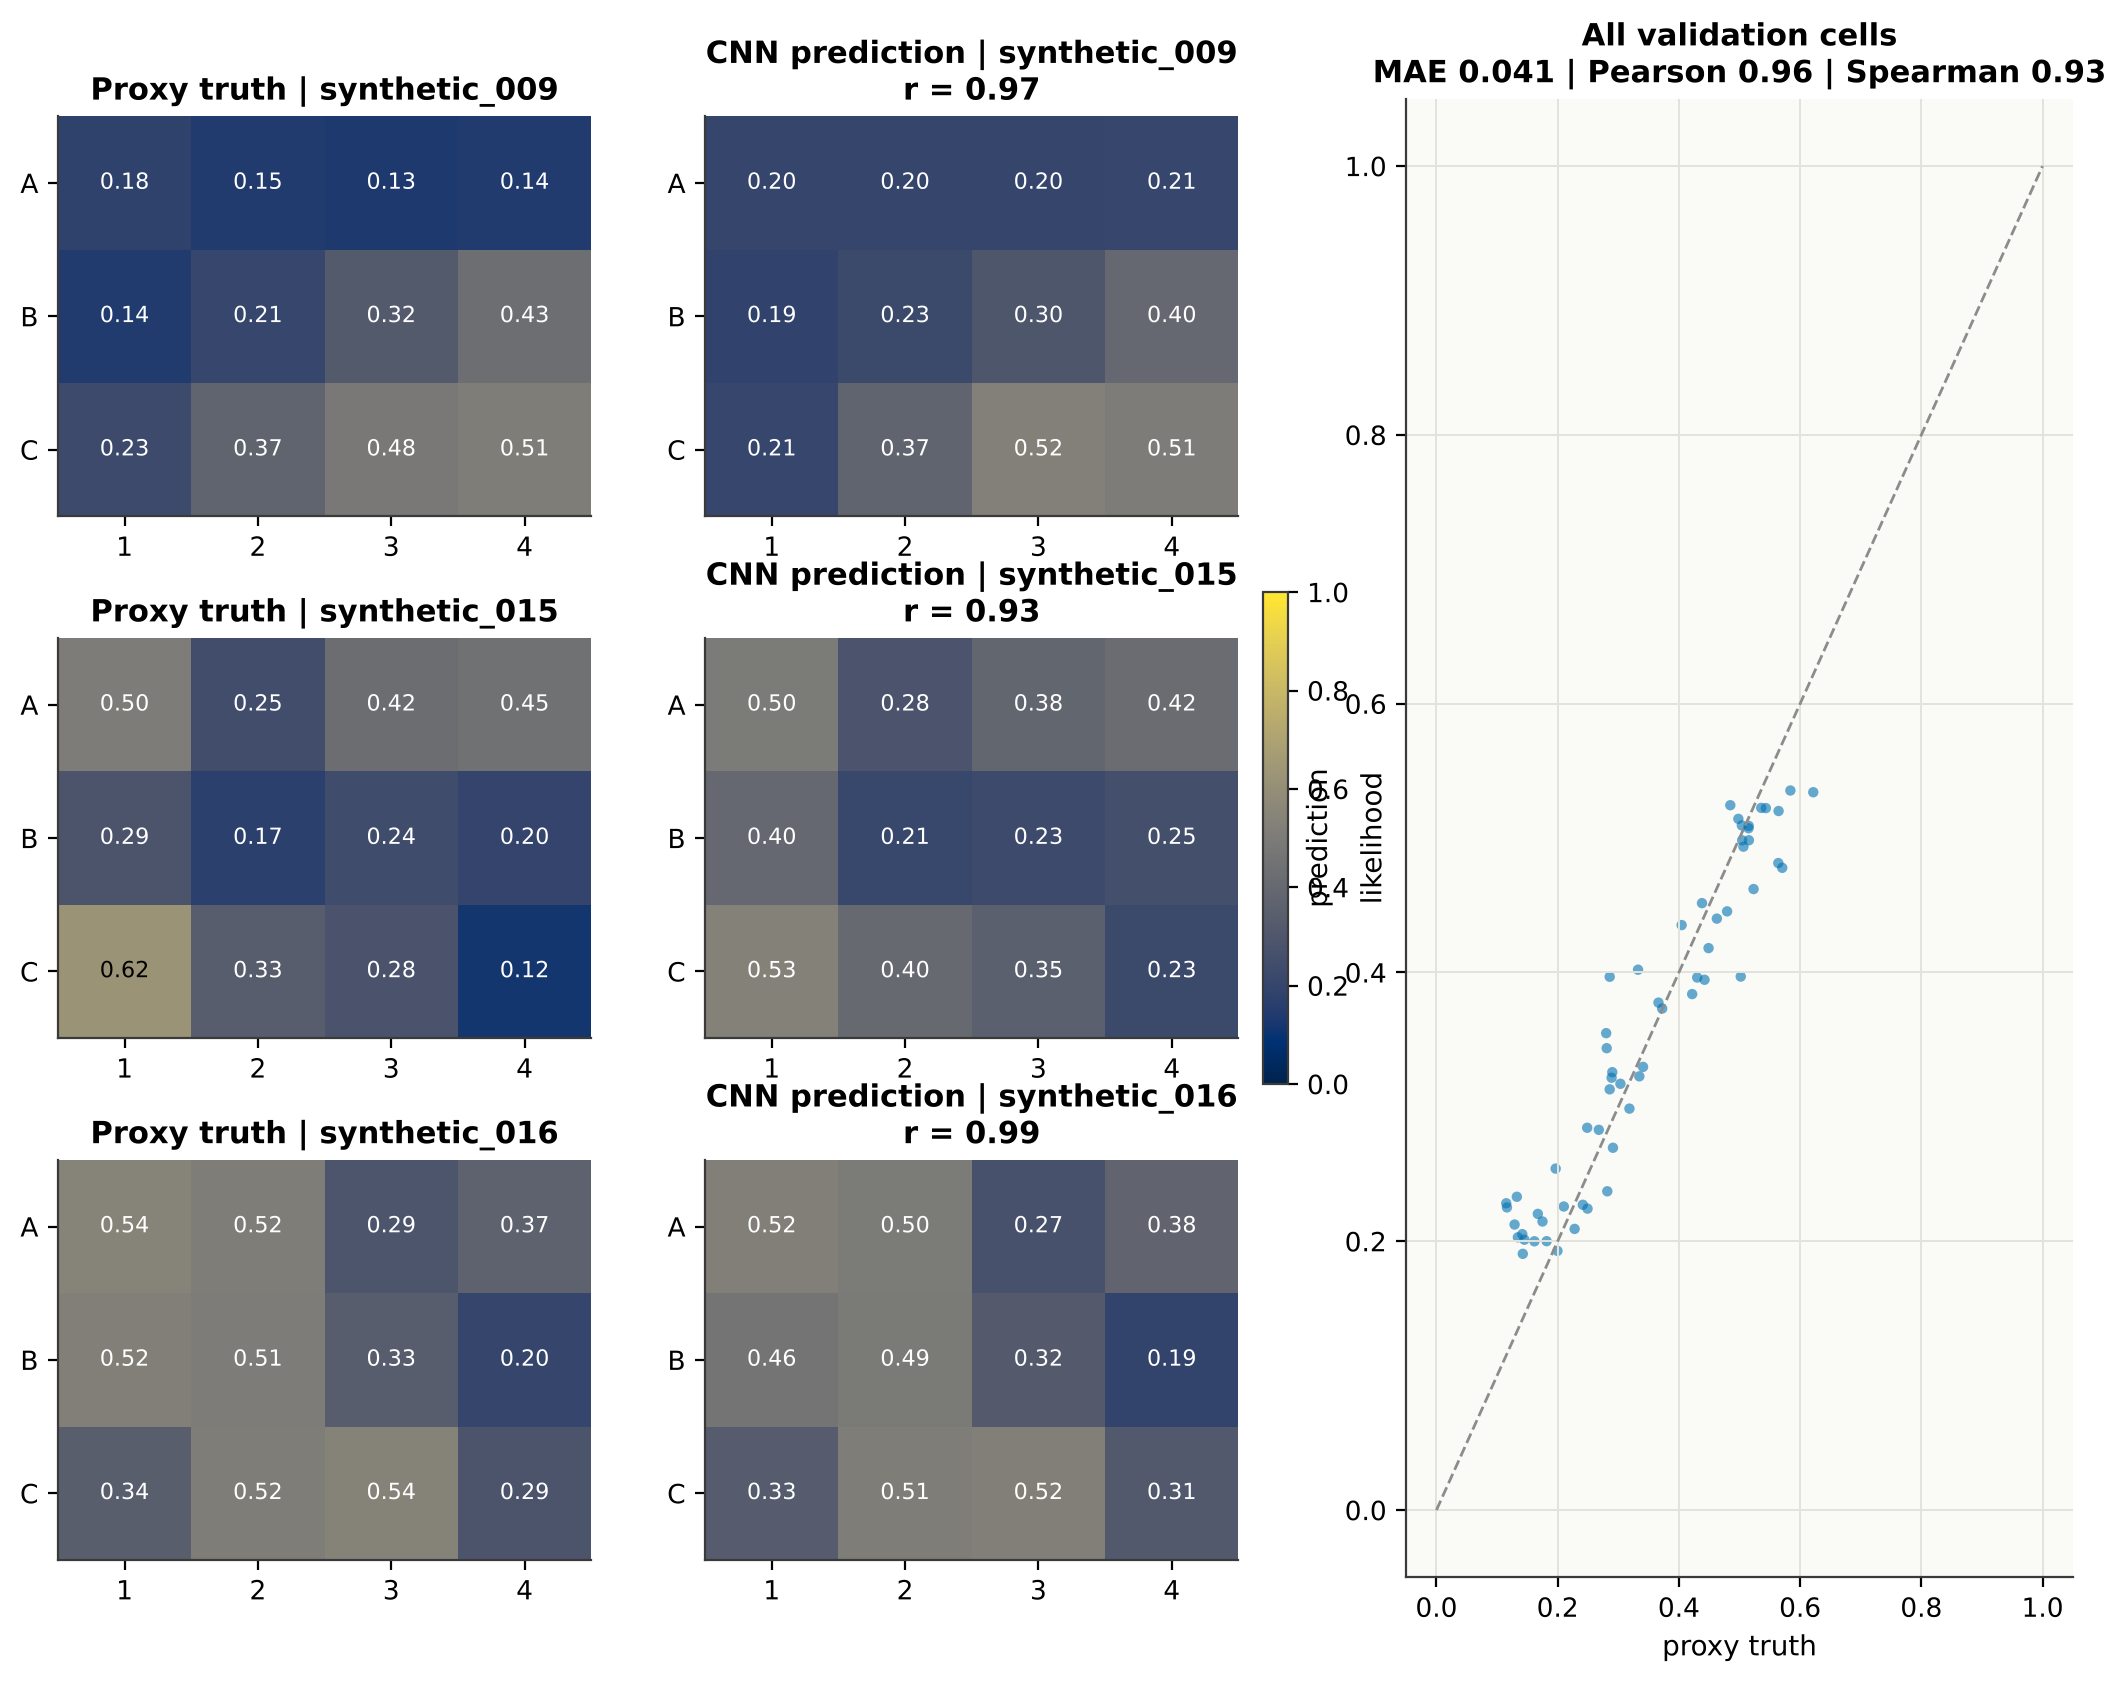

**03_cnn_training_curves.png**

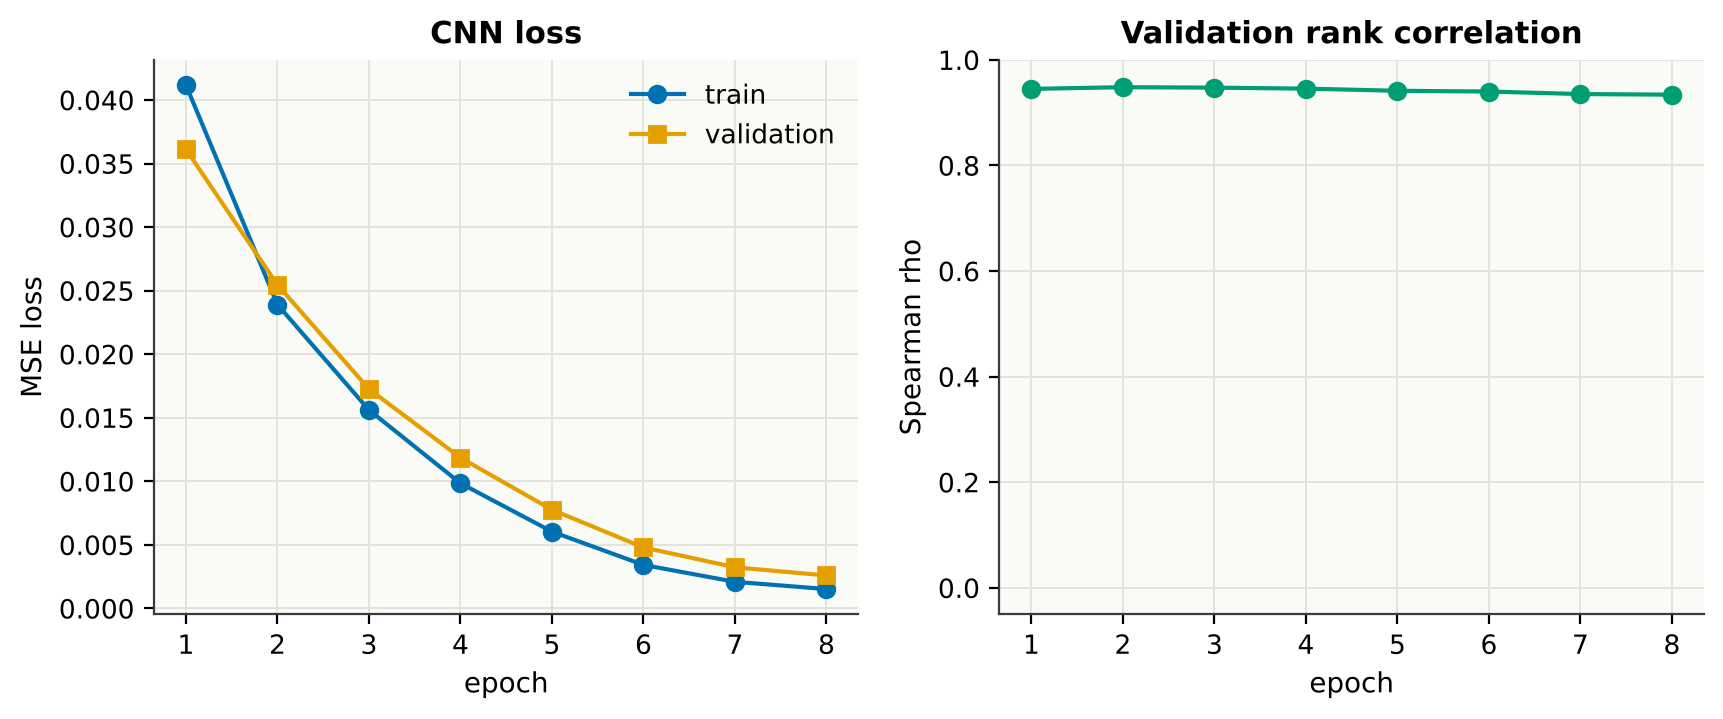

**04_placement_map.png**

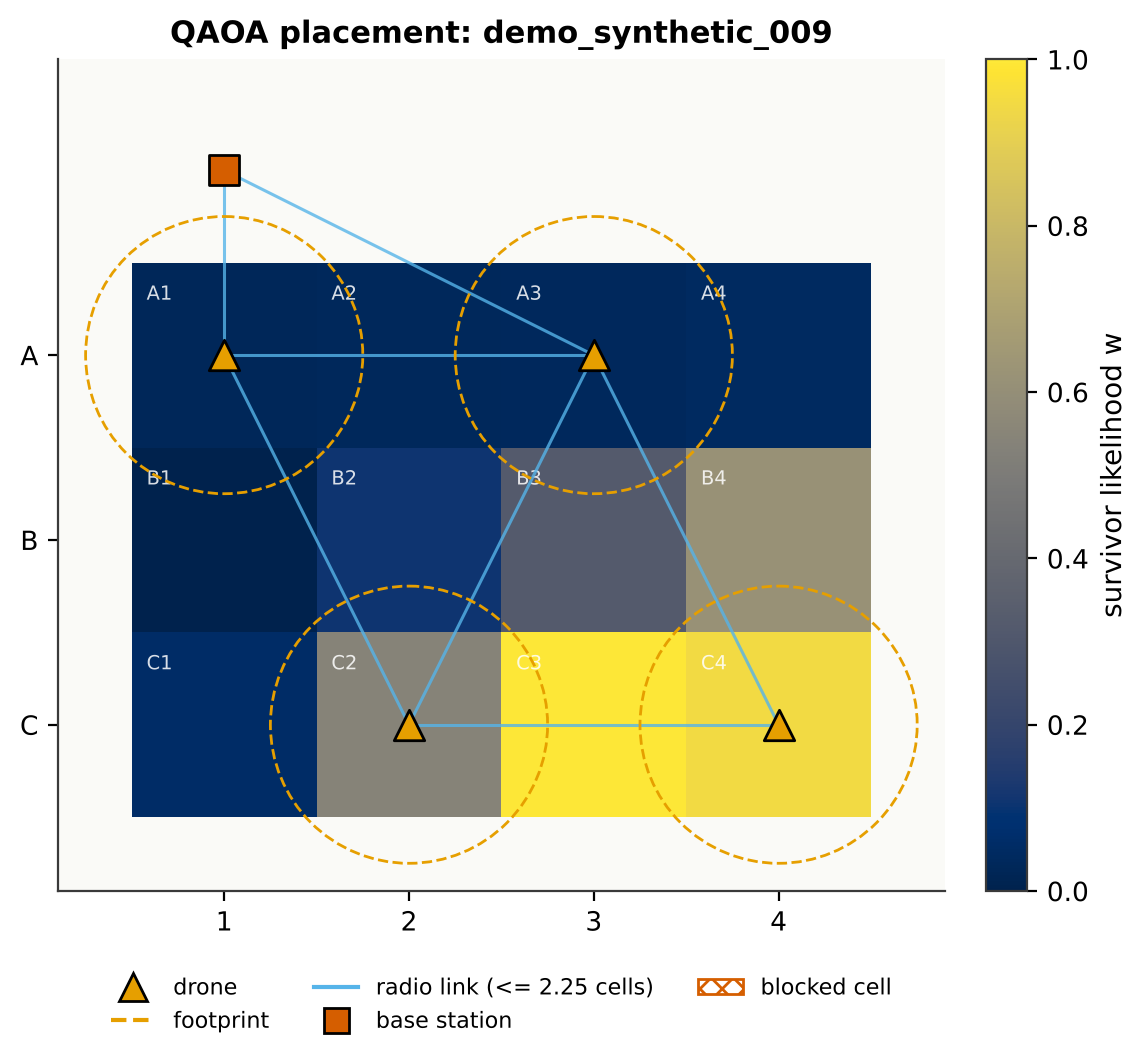

**05_method_comparison.png**

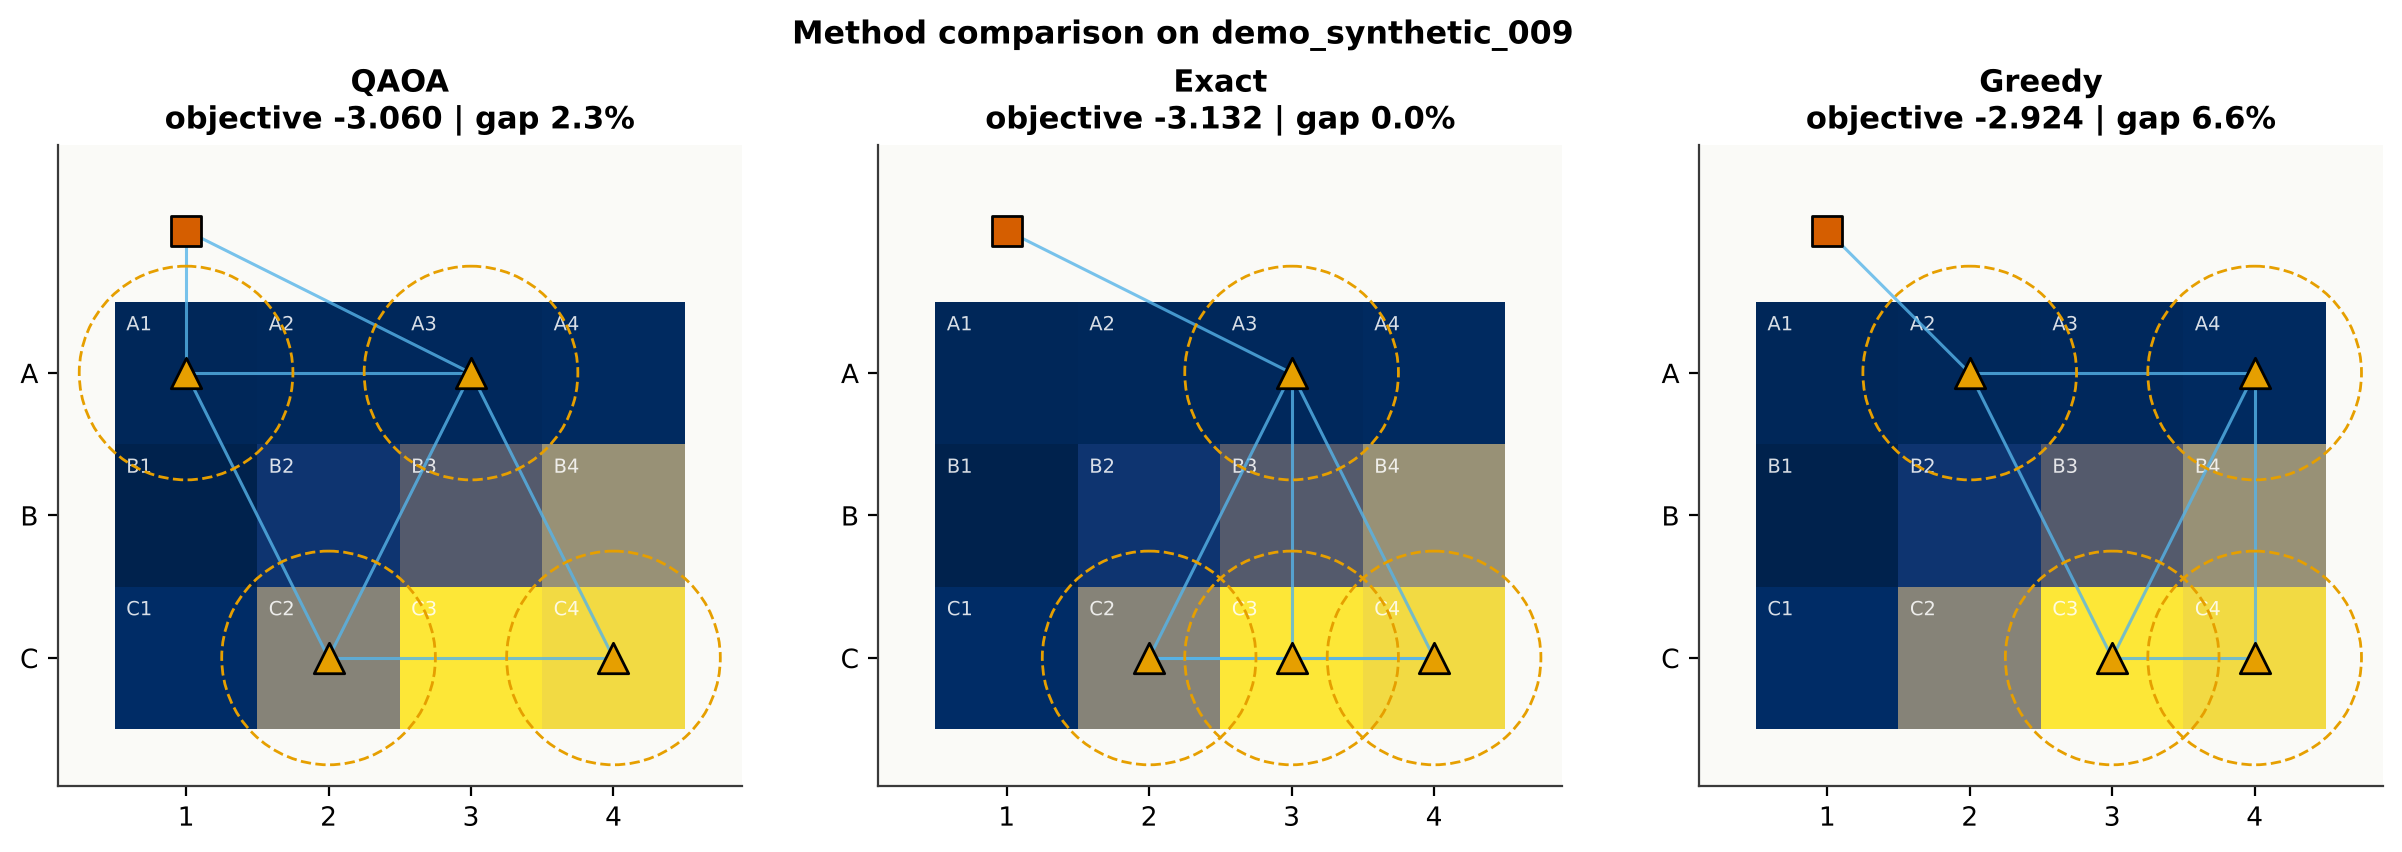

**06_qaoa_convergence.png**

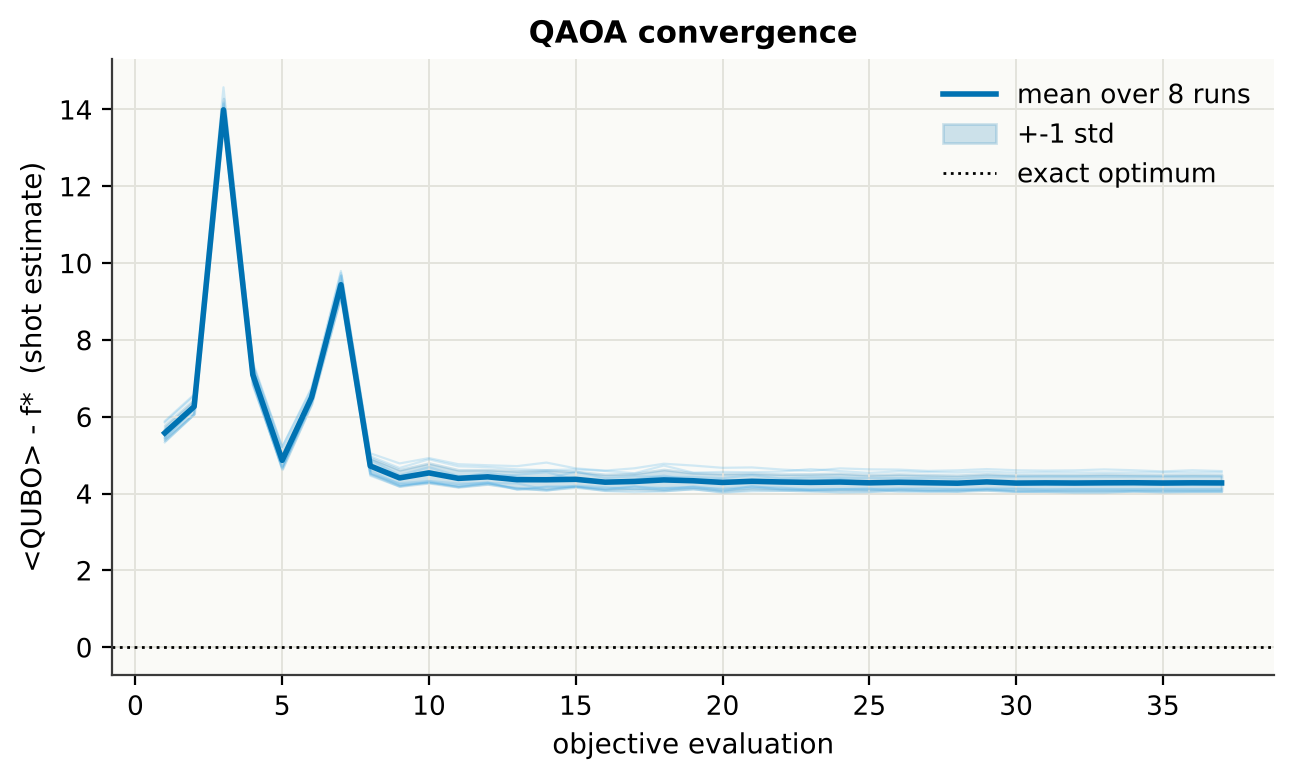

**07_bitstring_probabilities.png**

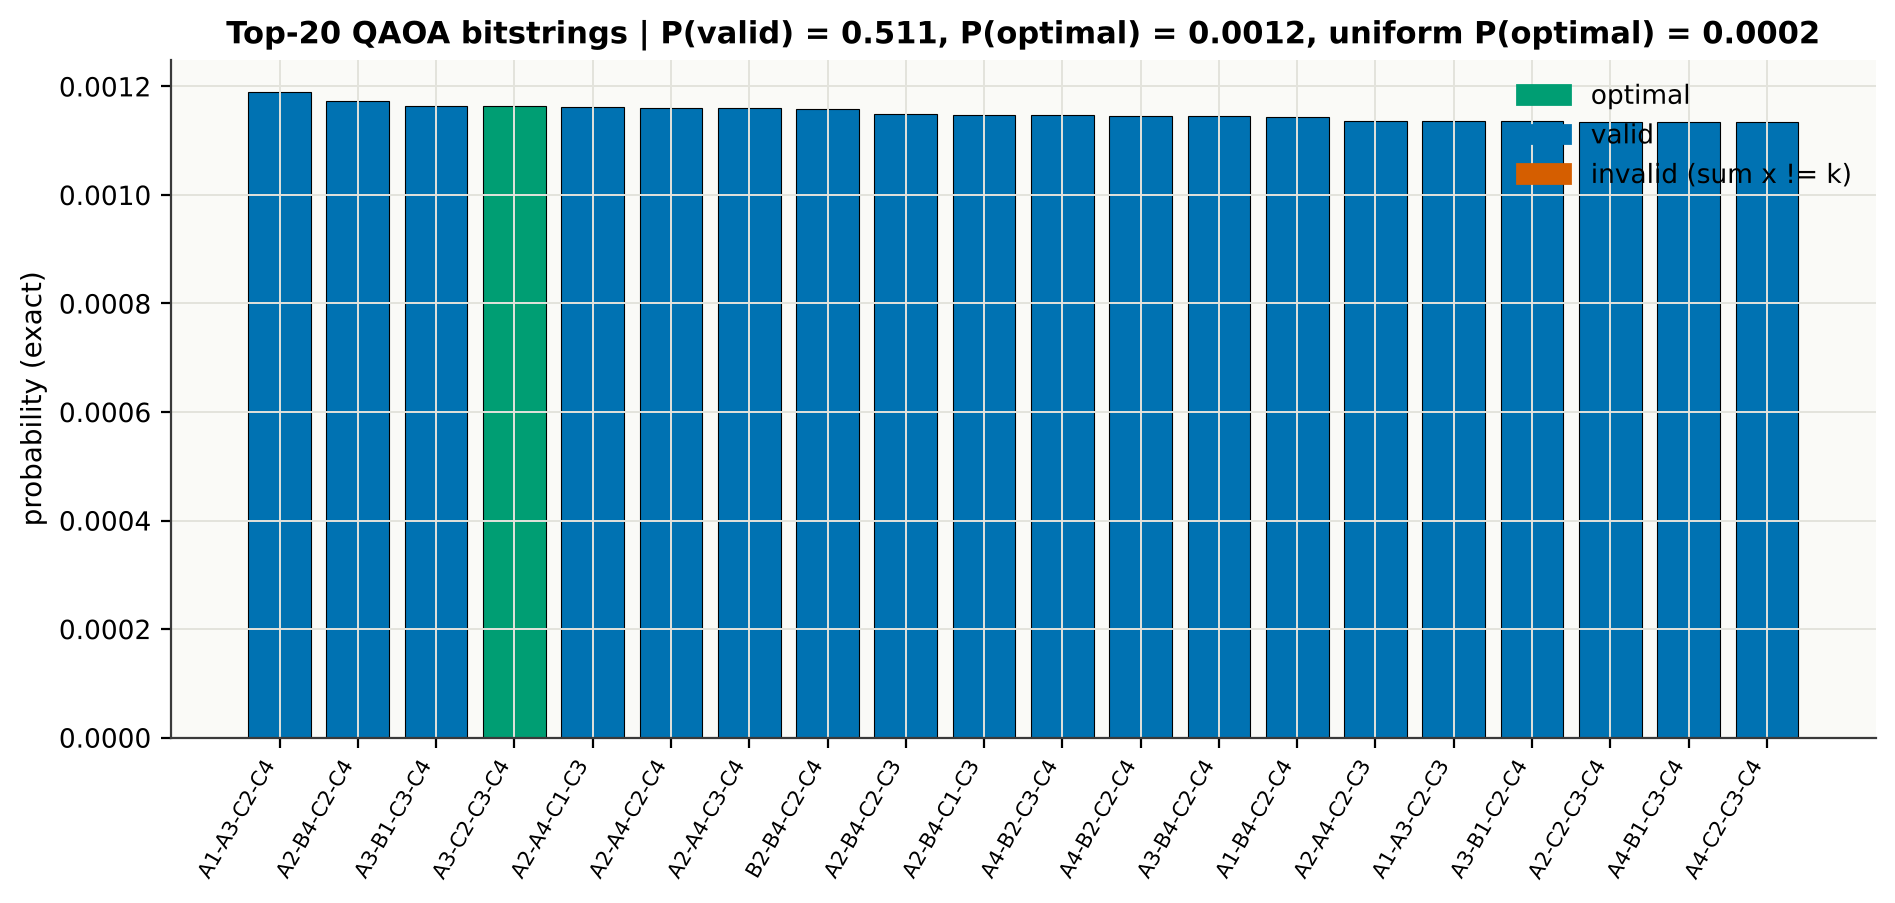

**08_optimality_gap.png**

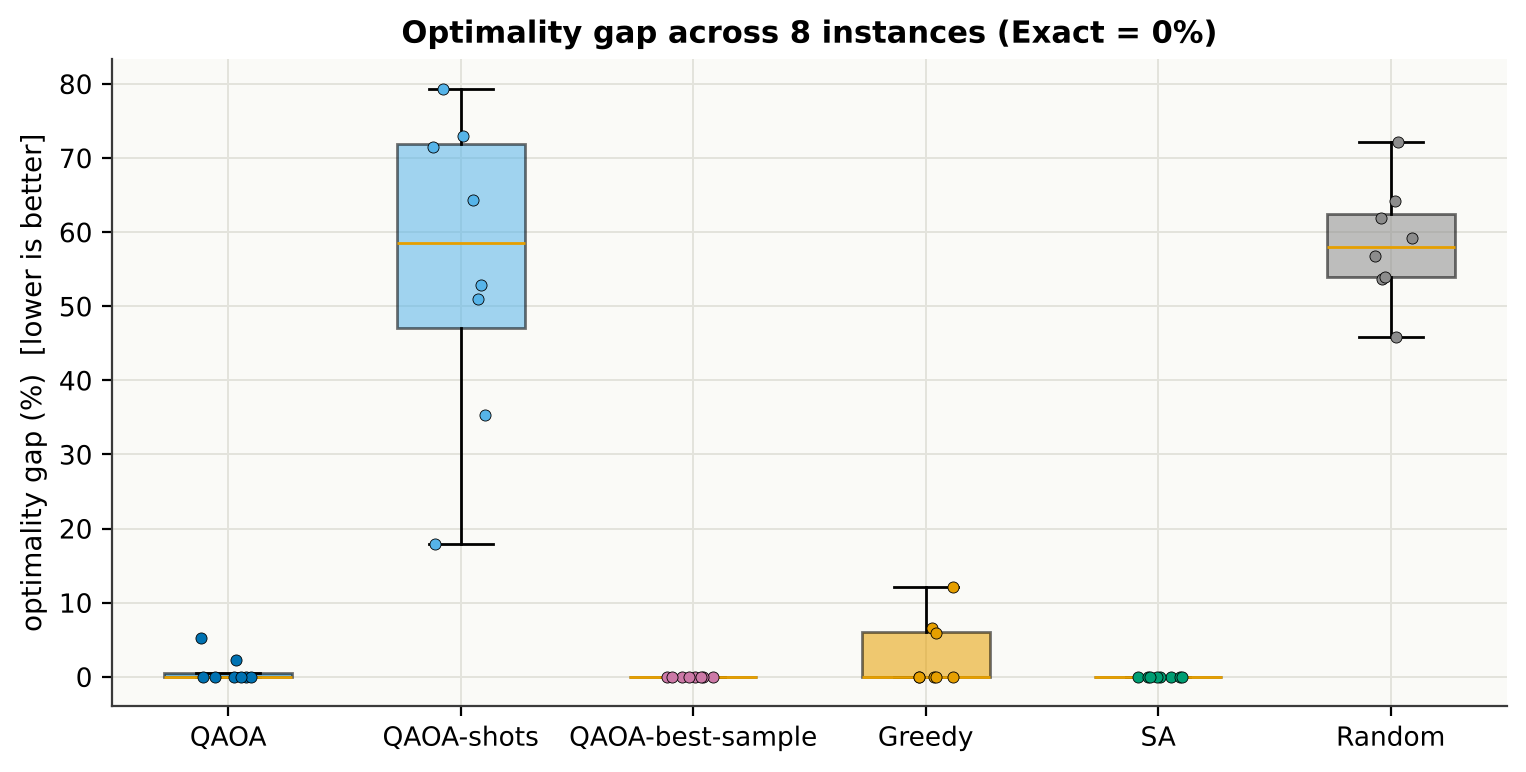

**09_agent_before_after.png**

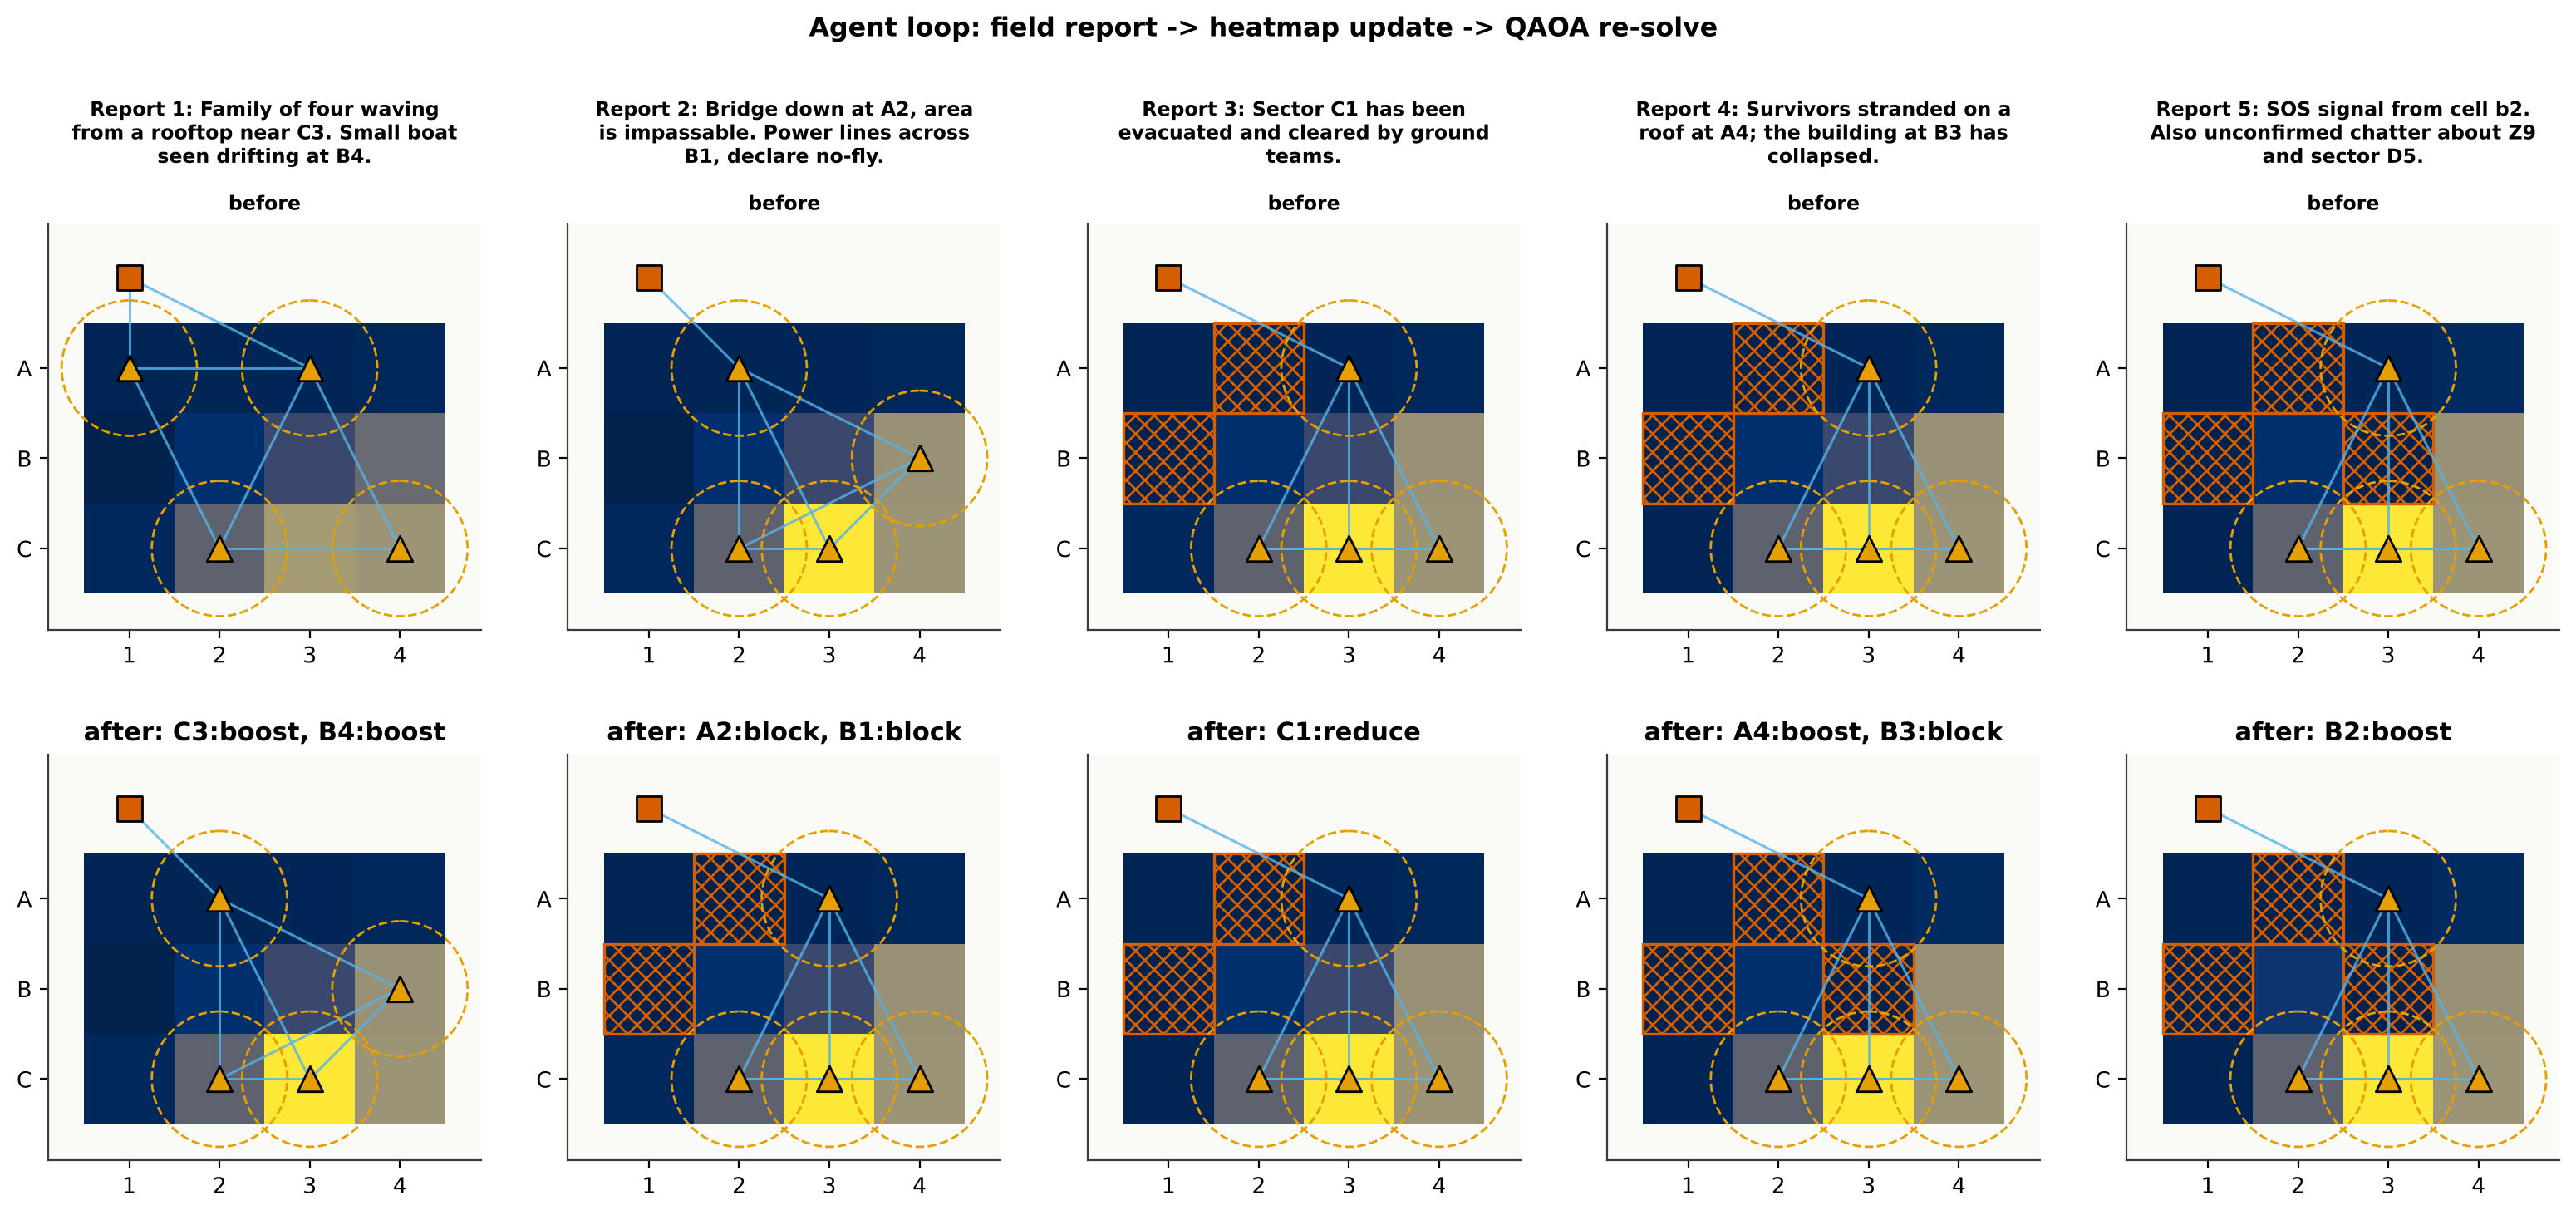

**10_depth_study.png**

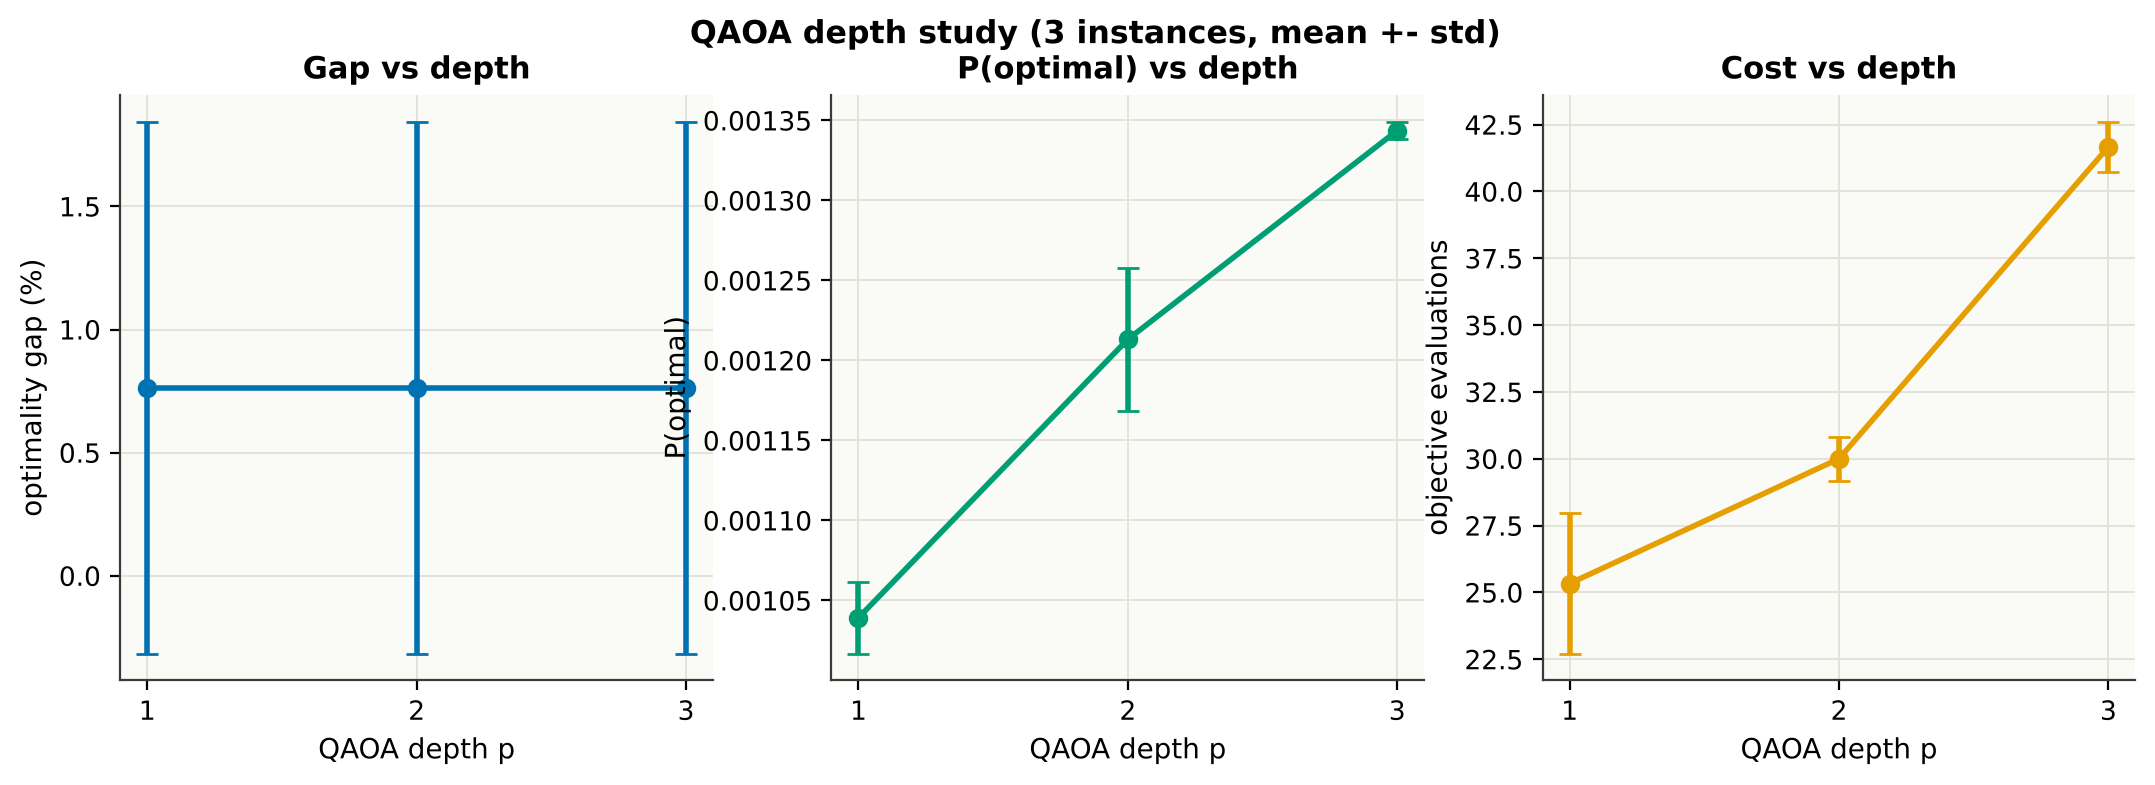

**11_penalty_sensitivity.png**

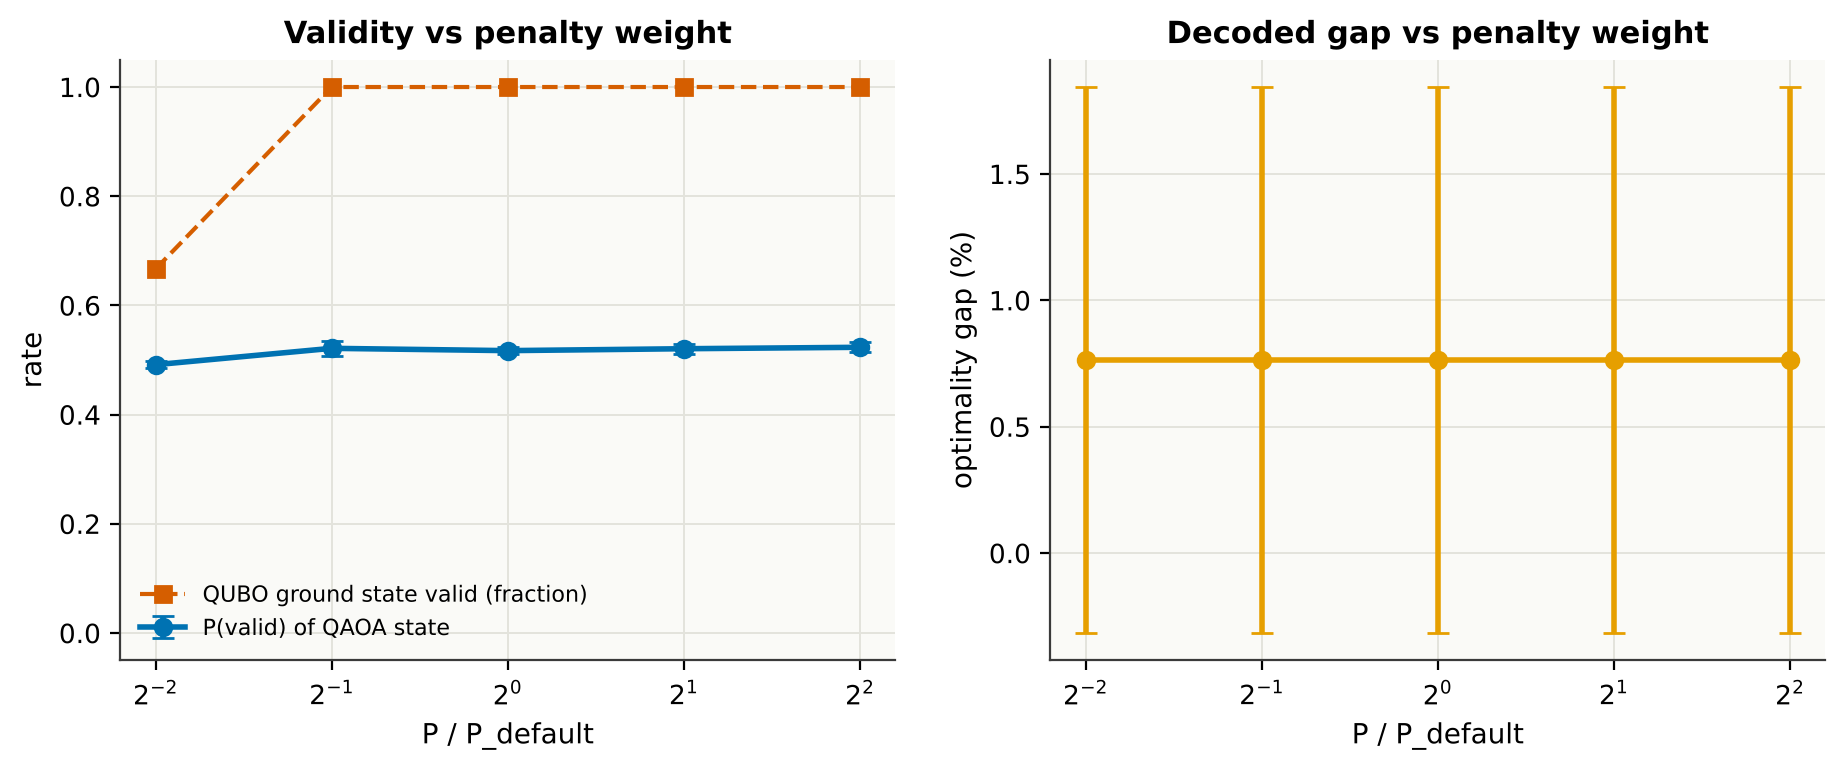

**12_warm_start.png**

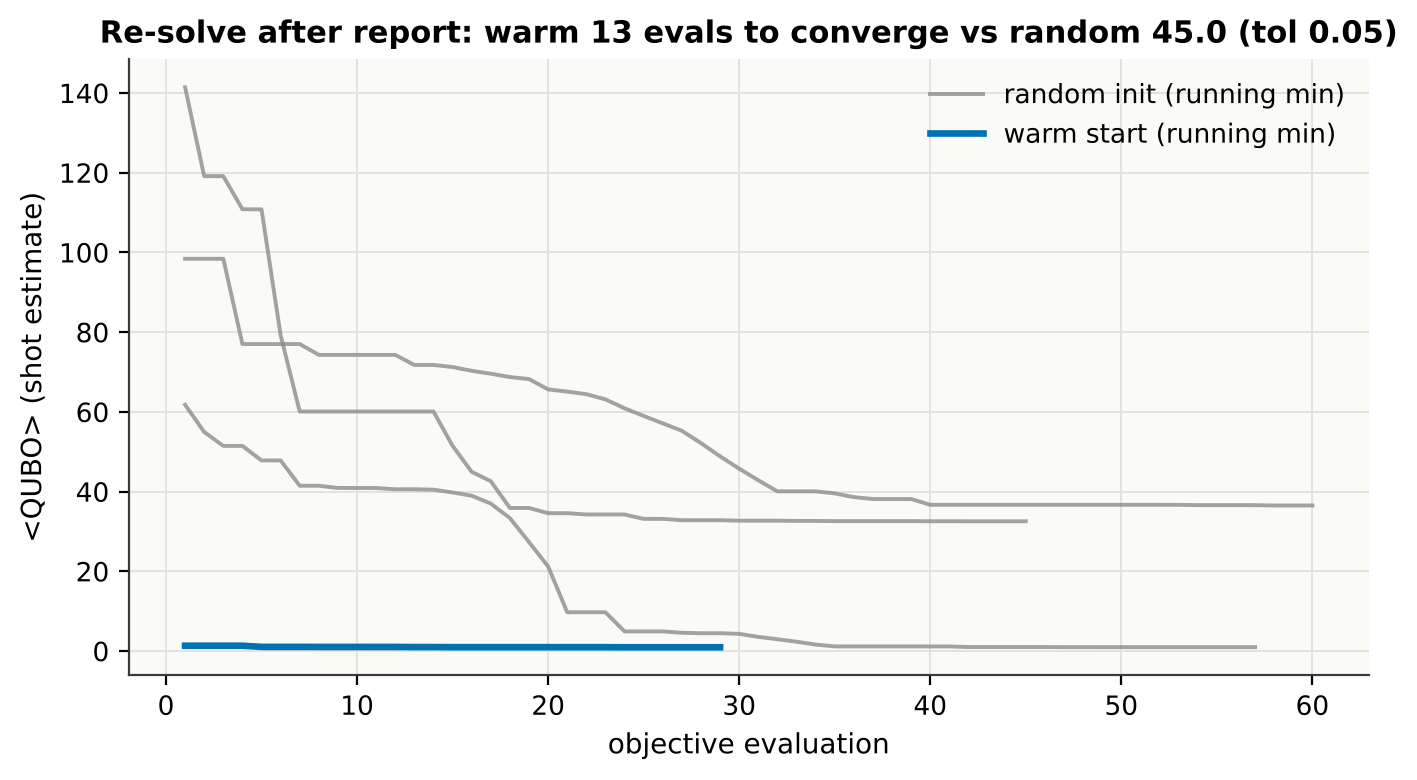

**13_optimizer_comparison.png**

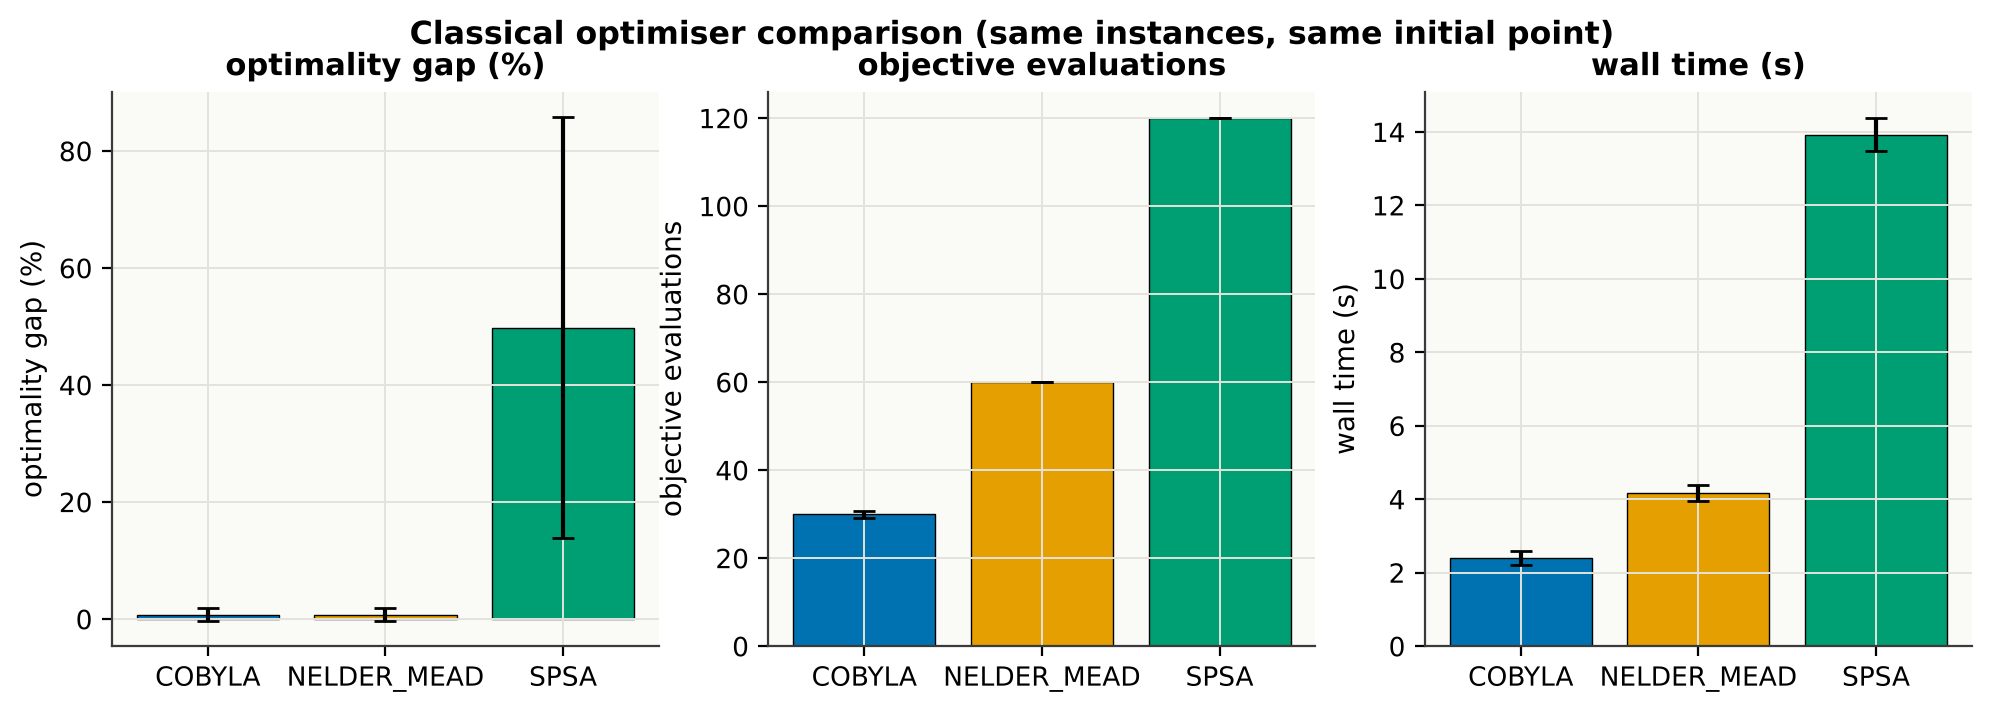

**14_noise_robustness.png**

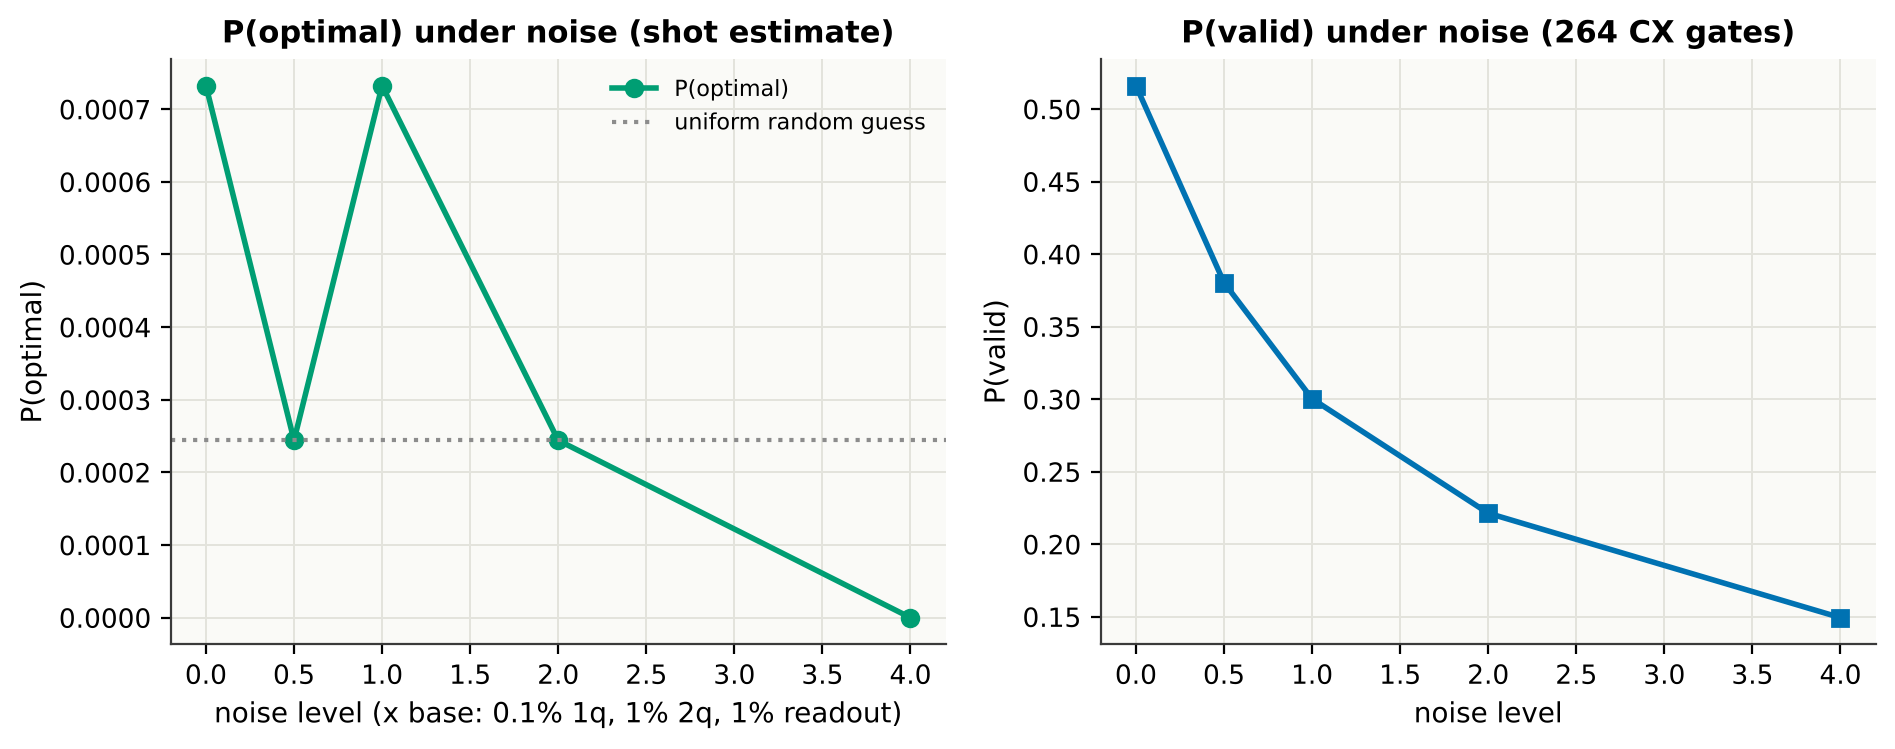

**15_landscape_p1.png**

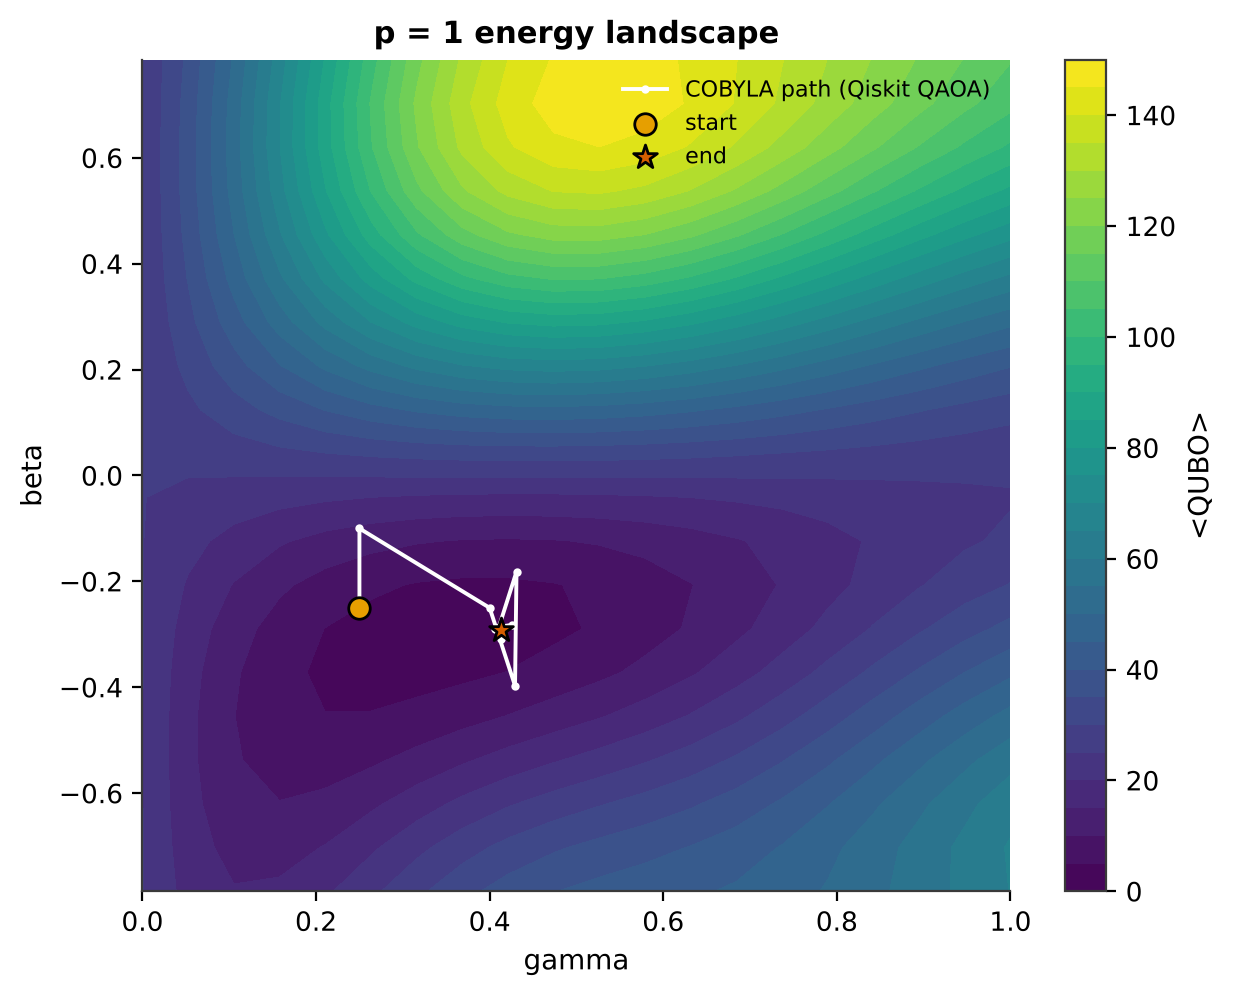

**16_scaling.png**

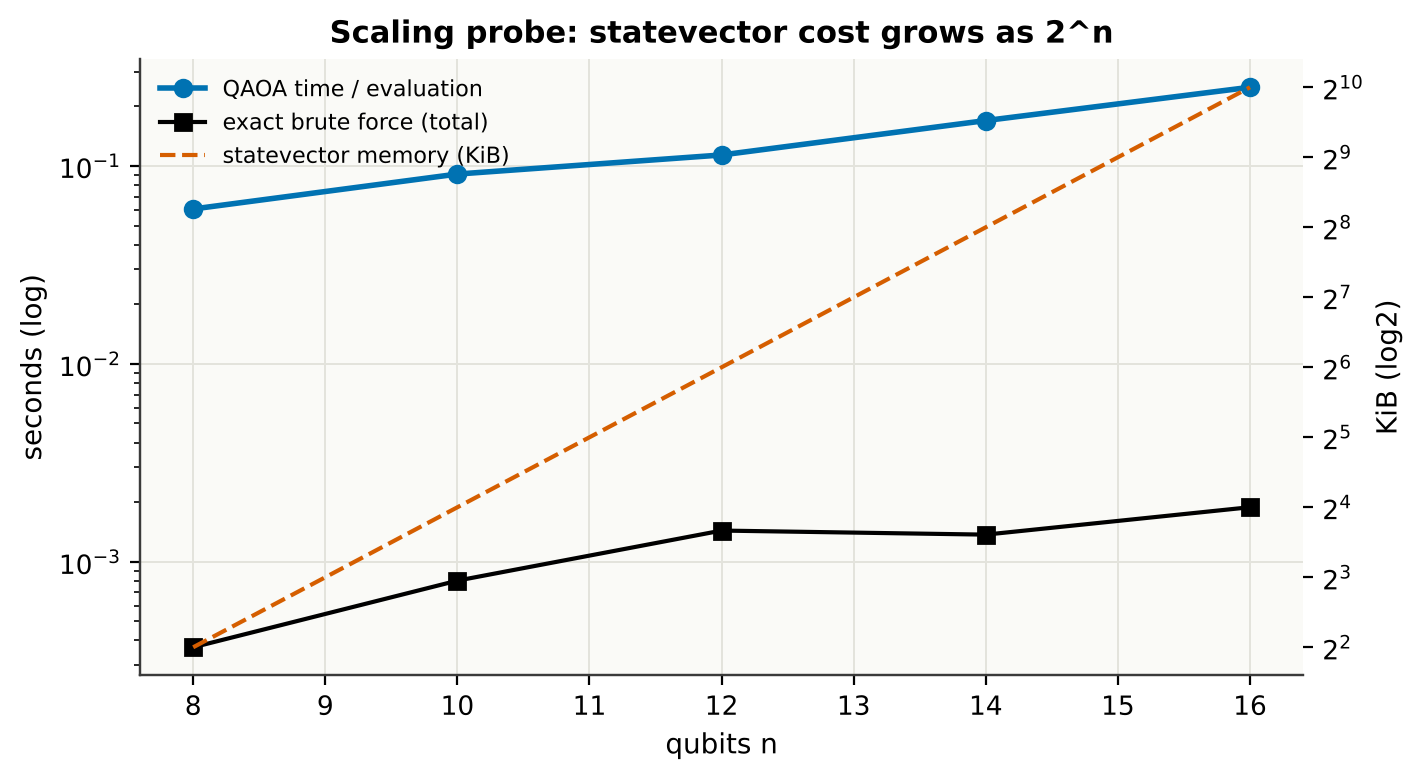

**17_circuit_diagram.png**

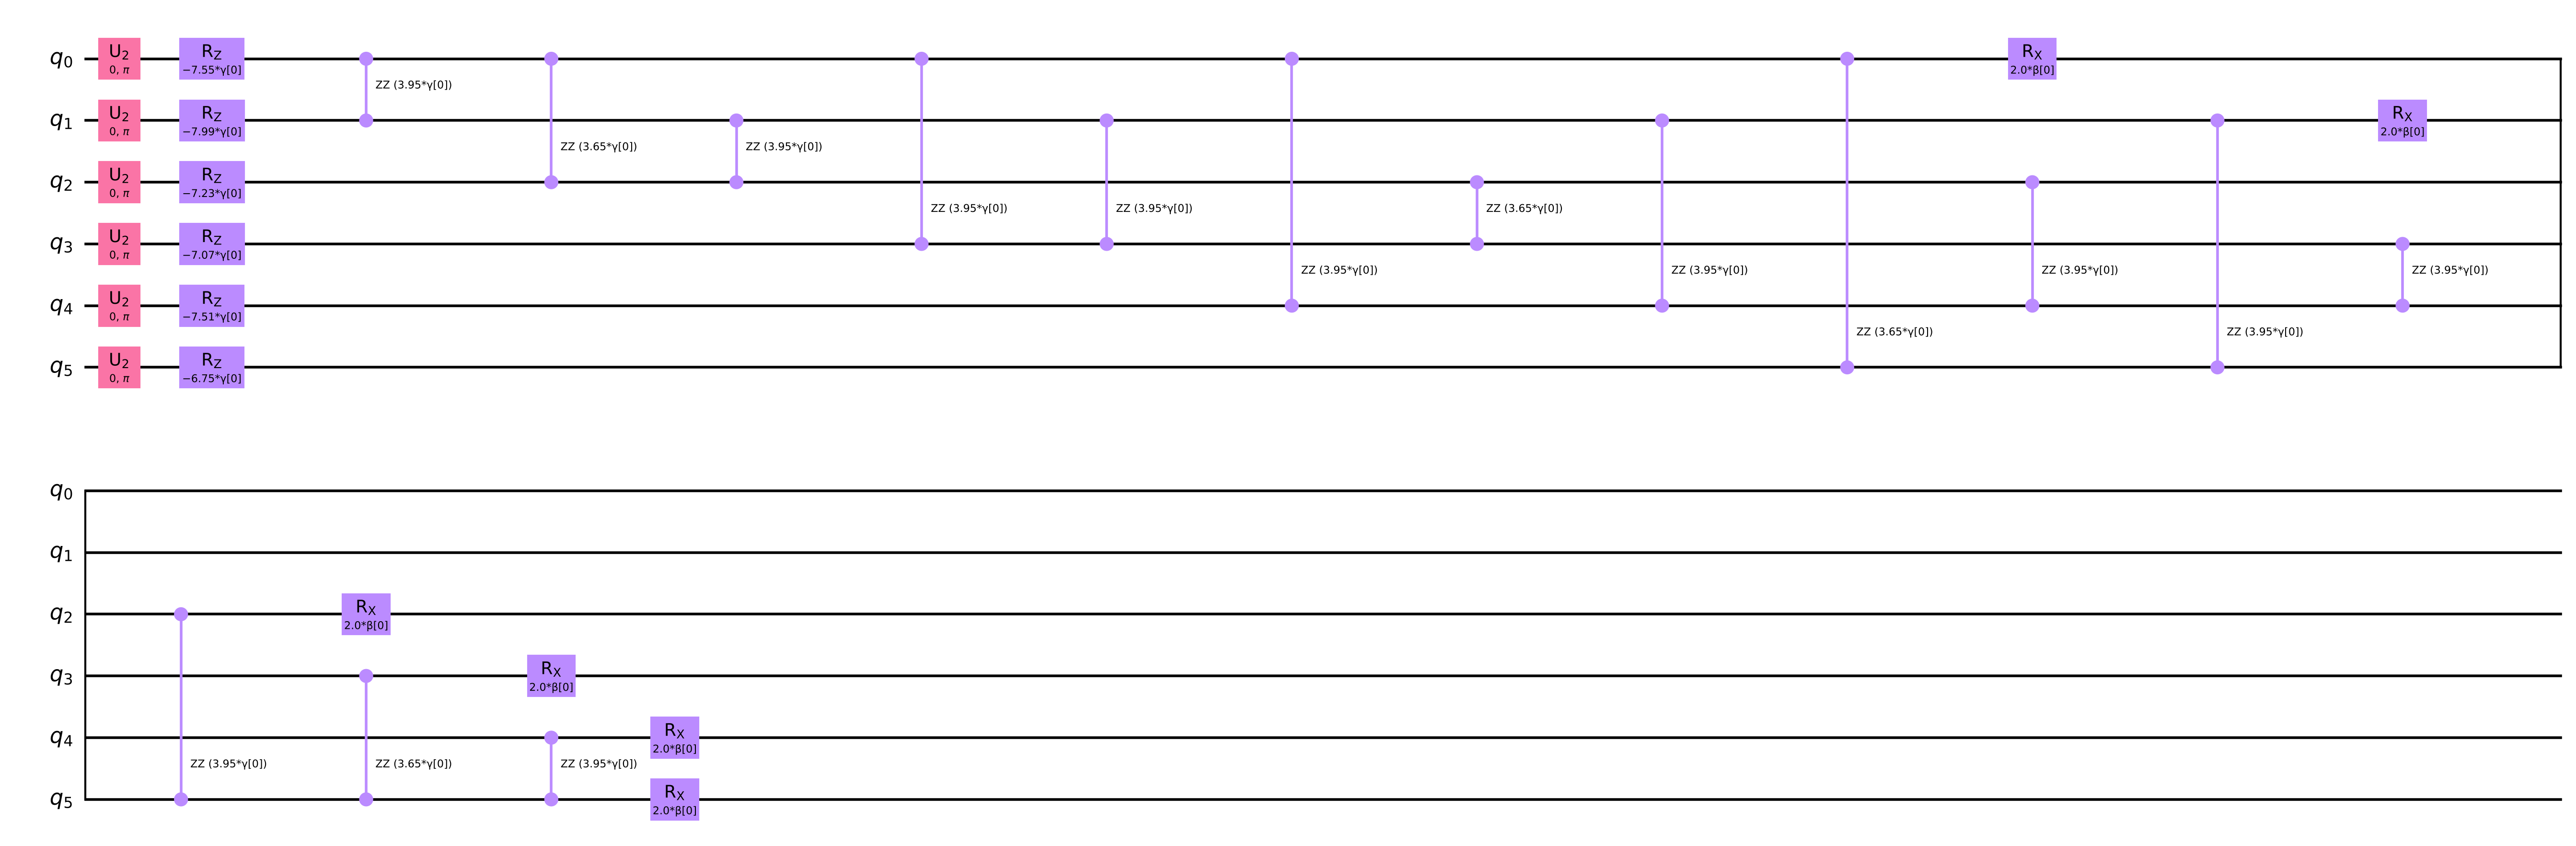

**18_architecture.png**

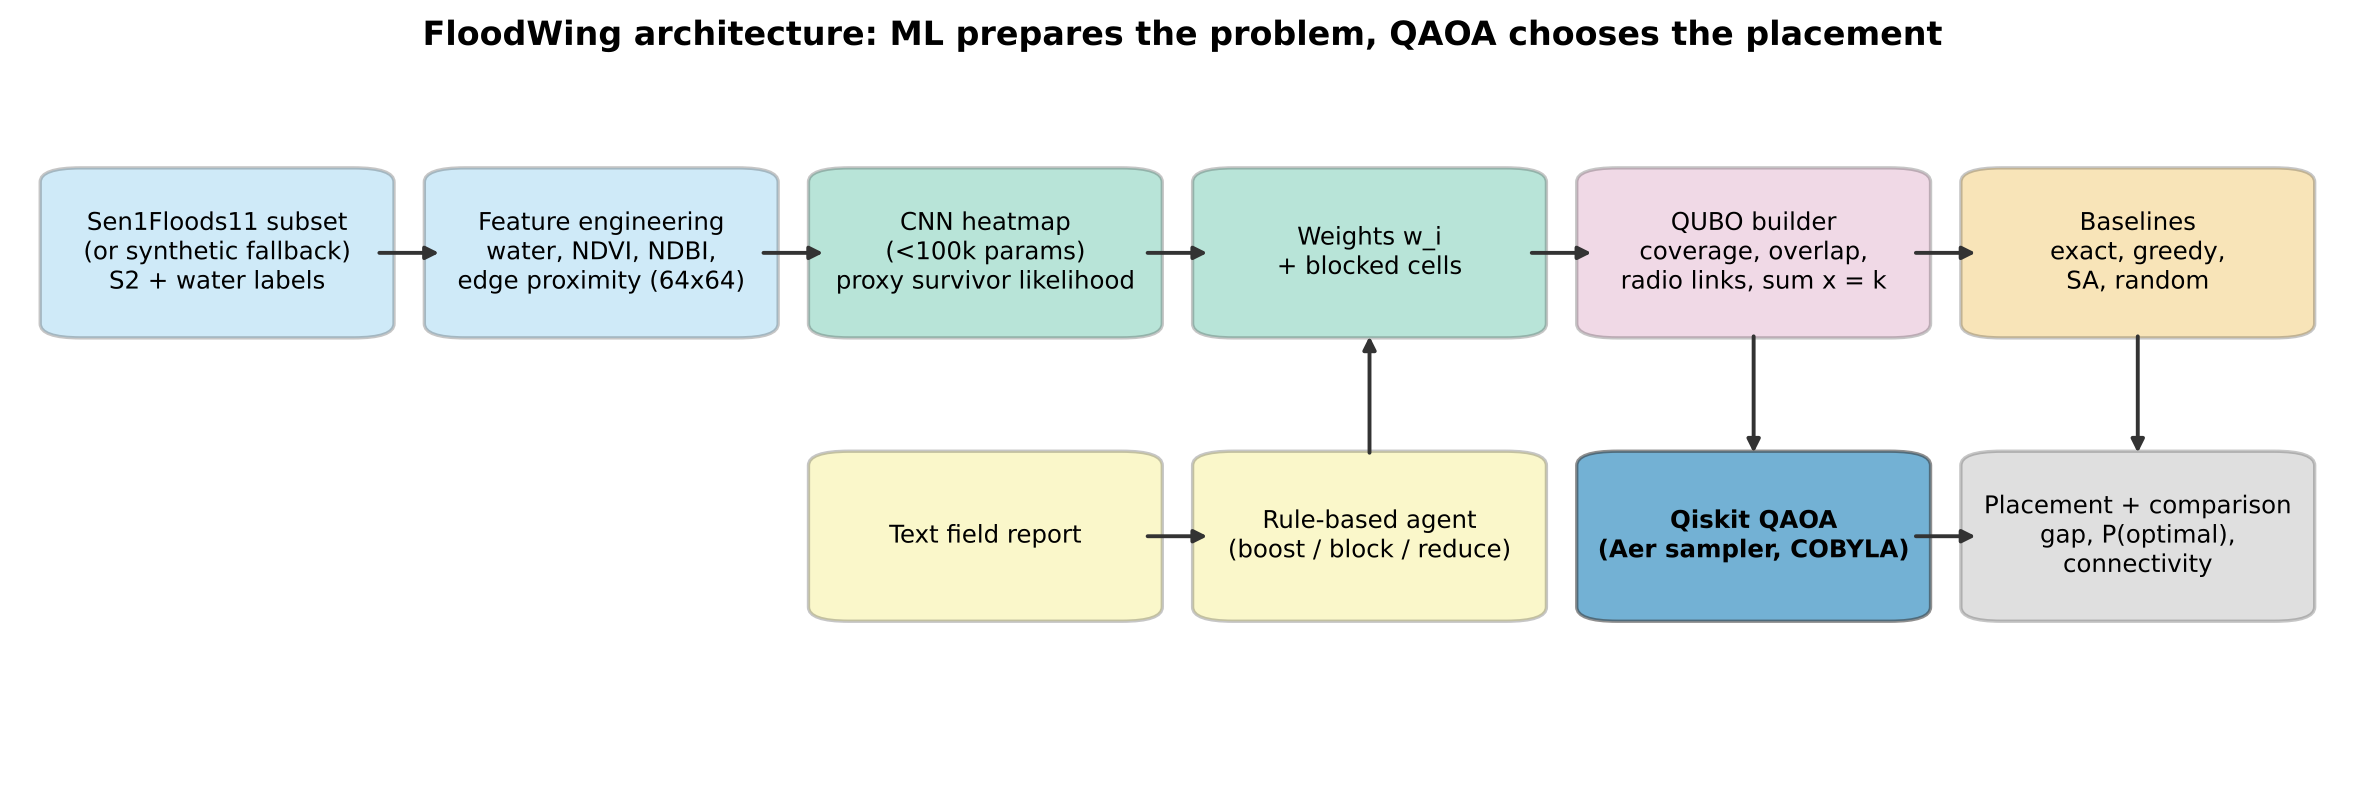

**19_xy_mixer.png**

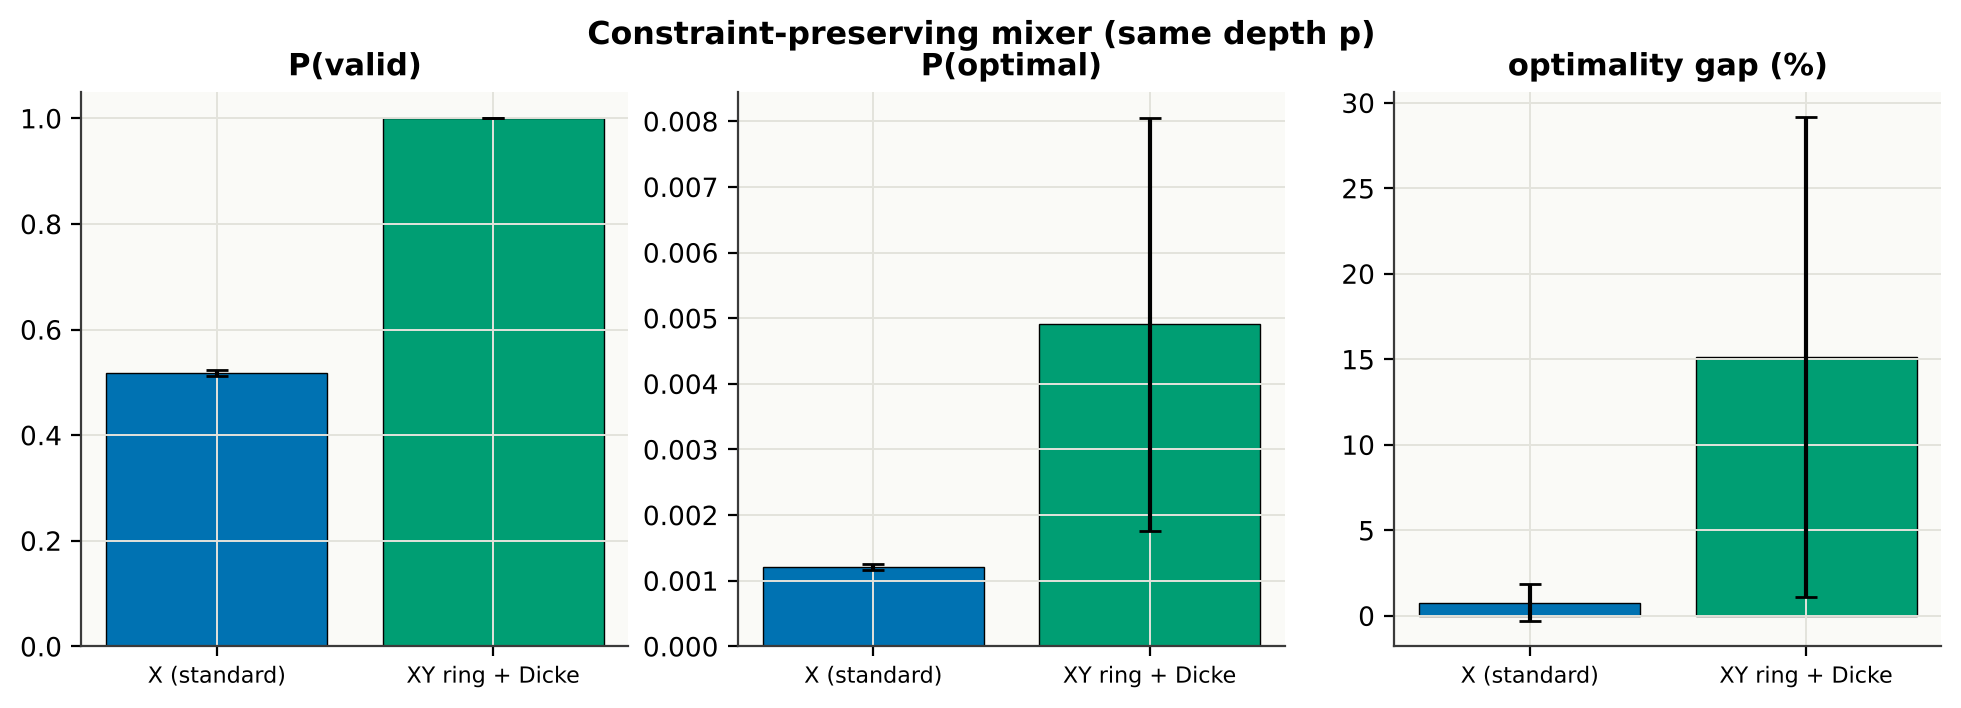

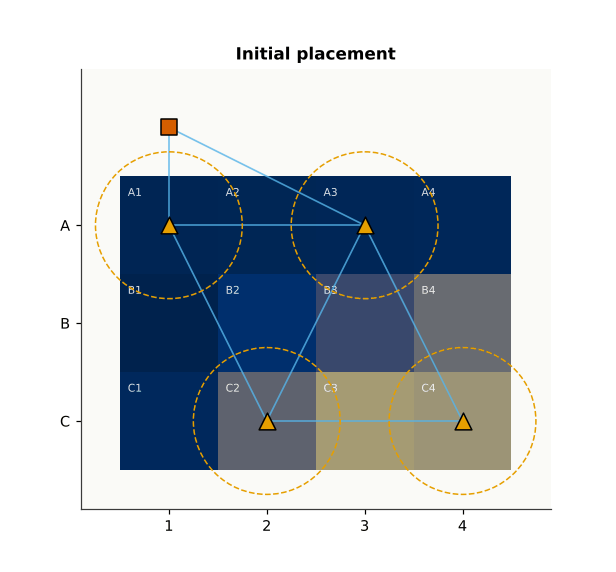

In [24]:
figs = P.stage_figures(st)
for name in figs:
    display(Markdown(f"**{name}**")); display(Image(filename=str(cfg.fig_dir / name), width=900))
gif = cfg.fig_dir / "agent_updates.gif"
if gif.exists():
    display(Image(filename=str(gif)))

## 10. Limitations and honest reflection
* 12-16 variables are solved exactly in milliseconds, so there is **no quantum advantage claim**.
* With the standard X mixer, QAOA mostly learns the `sum x = k` constraint: P(optimal) stays a small multiple of
  uniform guessing at p <= 3 and depends on the penalty weight (Section 8). The XY mixer keeps every sample valid.
* The headline **QAOA** read-out uses the exact statevector distribution (simulator-only). The
  hardware-realistic **QAOA-shots** read-out is much noisier; **QAOA-best-sample** is close to brute force.
* The survivor likelihood is a **proxy**, so the CNN learns a known function plus noise.
* The pairwise radio reward does not guarantee a connected relay chain to base (post-hoc connectivity is reported).
* The agent is a keyword parser and is brittle to unusual phrasing.
* Simulator and simple noise-model results do not predict real hardware. Scaling beyond 16 qubits is untested.

Items recorded during this run (data source, skipped or failed bonus items, figure failures):

In [25]:
for msg in st.issues or ["(none)"]:
    print("-", msg)

- data source: synthetic: 24 (synthetic chips were used)


## 11. Export
Writes `results/summary.json` (every headline number used in the report) and zips the figures. `P.run_all(cfg)` reproduces Sections 1-11 in one call.

In [26]:
summary = P.stage_export(st)
print(f"total runtime {st.elapsed():.0f}s")
display(pd.Series(st.timings, name="seconds").round(1))

wrote /home/claude/floodwing/results/summary.json and /home/claude/floodwing/results/figures.zip
total runtime 281s


data                 0.7
heatmap_cnn          1.8
agent               15.5
qubo                 0.1
demo_solve           2.2
evaluation          19.4
bonus_depth         21.4
bonus_penalty       36.3
bonus_warmstart     18.4
bonus_optimizers    61.5
bonus_noise         73.4
bonus_landscape      1.9
bonus_scaling        3.4
bonus_xy_mixer      13.0
figures              5.6
Name: seconds, dtype: float64